# Tensor networks on quantum data

**Marcin Płodzień** — Institute of Theoretical Physics, Jagiellonian University in Kraków  
[ORCID 0000-0002-0835-1644](https://orcid.org/0000-0002-0835-1644) · [github.com/MarcinPlodzien](https://github.com/MarcinPlodzien) · [www](https://chaos.if.uj.edu.pl/marcinplodzien/)

*Quantum Many-Body Simulation — Chapter 13 — Quantum machine learning*

## 1. Introduction

Matrix product states have been trained on images, as classifiers and as generative models. Here the data come from
quantum many-body states: the bit strings that a quantum simulator returns when every qubit of a prepared state is
measured. Such measurement records are what experiments with trapped ions, Rydberg atoms or superconducting qubits
produce, and a matrix product state (MPS) suits them for two reasons: ground states of one-dimensional gapped
Hamiltonians carry little entanglement and are compressed efficiently into an MPS, and an MPS can be sampled exactly
and evaluated on any bit string at a cost linear in the number of qubits. The notebook assumes the matrix product
states and DMRG of [notebook 18, matrix product states, DMRG and TEBD](../ch07_tensor_networks/18_mps_tebd.ipynb)
and the two machine-learning models of
[notebook 56, tensor networks as machine-learning models](56_tensor_networks_for_machine_learning.ipynb) and
[notebook 57, the MPS Born machine](57_mps_born_machine.ipynb).

### 1.1 Snapshots

Let $\vert\psi\rangle$ be a state of $N$ qubits. Measuring every qubit in the computational basis (the common
eigenbasis of all $Z_j$) returns a bit string $\mathbf s=(s_0,\dots,s_{N-1})$, $s_j\in\{0,1\}$, with the probability
given by the Born rule,

$$p(\mathbf s)=\vert\langle\mathbf s\vert\psi\rangle\vert^2=\vert\psi(\mathbf s)\vert^2, \tag{1}$$

and destroys the state. One such string is a *snapshot* in the $Z$ basis. Rotating every qubit by the Hadamard gate
$U_{\rm H}=(X+Z)/\sqrt2$ before the measurement gives a snapshot in the $X$ basis, with probabilities
$\vert\langle\mathbf s\vert U_{\rm H}^{\otimes N}\vert\psi\rangle\vert^2$. The outcome $s_j=0$ means the eigenvalue
$+1$ of $Z_j$ (or of $X_j$), $s_j=1$ the eigenvalue $-1$, so the measured value is $(-1)^{s_j}$. A data set is a list
of $M$ snapshots of $M$ identically prepared copies. Sites, bits and bonds are counted from 0, and bond $j$ is the cut
between sites $j-1$ and $j$.

### 1.2 Two tasks: reconstructing a state and learning a property

**Part A (Section 4) is quantum state tomography with a prior.** Full tomography of a density matrix of $N$ qubits
has $4^N-1$ real parameters and needs measurements in $3^N$ settings of single-qubit Pauli bases, as derived in
[notebook 23, quantum state tomography](../ch08_quantum_information_protocols/23_quantum_state_tomography.ipynb);
this is out of reach beyond about ten qubits. Here the state of $N=32$ qubits is reconstructed inside a much smaller
set fixed in advance, the *prior*: the state is pure, its amplitudes in the $Z$ basis are non-negative, and it is well
approximated by an MPS of small bond dimension. Under the second assumption Eq. (1) can be inverted,
$\psi(\mathbf s)=\sqrt{p(\mathbf s)}$, so the state is fixed by its distribution in a single basis, and learning that
distribution from snapshots reconstructs the state. The learner is the MPS Born machine, introduced in
[[1]](#ref-1). Ground states of *stoquastic* Hamiltonians, such as the transverse-field Ising chain used below,
satisfy its sign and purity parts exactly (Section 3.1). Neural-network quantum state tomography, introduced in [[2]](#ref-2), used
the same prior for ground states of the transverse-field Ising and XXZ models, which it reconstructed from $\sigma^z$
snapshots alone with a restricted Boltzmann machine. The prior buys a single measurement basis instead of $3^N$
settings and a model of $O(N\chi^2)$ numbers. It costs the ability to see signs, phases or mixedness (Section 4.9);
the MPS tomography of [[3]](#ref-3), which removes the sign prior by measuring neighbouring blocks of qubits in all Pauli
bases, is outlined in Section 4.10.

**Part B (Section 5) is property learning.** An MPS classifier, introduced in [[4]](#ref-4), is trained on snapshots
labelled by the phase of the state they come from and then asked, at every field, which phase the snapshots look like.
Nothing is reconstructed: the classifier learns one binary property of the state from its measurement records.
Training a classifier on configurations labelled by their phase and reading the transition off the point where its
output changes was introduced in [[5]](#ref-5), for classical Monte Carlo configurations; here it is applied to quantum
snapshots in two measurement bases. Section 5 also shows what such a crossing converges to as $N$ grows, and which
crossings converge to the critical point.

### 1.3 Road map

* **Section 3** defines the transverse-field Ising chain, shows that its ground state can be taken with non-negative
  amplitudes in the $Z$ basis and in the $X$ basis, with the non-degeneracy this needs checked by printed gaps, computes ground states for $N=16$, $32$ and $64$ by DMRG, removes the symmetry
  breaking of DMRG by a parity projection, and samples snapshots in both bases. Everything is checked against exact
  diagonalisation at $N=12$, against the exact free-fermion energies, and at $N=16$ one to one against exact state
  vectors.
* **Section 4** reconstructs the ground state of $N=32$ spins from $Z$ snapshots: the estimator, the Kullback–Leibler
  divergence and the fidelity with their statistical errors, observables of the reconstruction from local estimators,
  the dependence on the number of snapshots and on the bond dimension, the field dependence across the critical point,
  an exact state-vector check at $N=16$, the failure for a state with signs and for a mixed state, and the step to
  general MPS tomography.
* **Section 5** classifies snapshots by phase in the $Z$ and the $X$ basis for $N=16$, $32$ and $64$, identifies which
  statistic of the snapshots each classifier tracks, computes the exact limits of these crossings from the free-fermion
  solution, locates the critical point with crossings of two system sizes, and repeats the $N=16$ analysis with exact
  state vectors.
* **Sections 6–7** give the cost, the point where exact state vectors stop, and the limits of the methods.

### What you will learn

*Physics*

* why ground states of stoquastic Hamiltonians are sign-free, and why for them one measurement basis determines the
  state;
* what $Z$ and $X$ snapshots of the Ising chain can and cannot reveal: the order parameter, the transverse
  magnetisation, the disorder operator of the Kramers–Wannier duality, signs and coherence;
* why the field at which a classifier, or any order parameter, crosses a fixed level does not converge to the critical
  point, and why the crossing of two system sizes does.

*Numerical methods*

* quantum state tomography with a prior, the fidelity of a reconstruction, the bound $F\geq e^{-D_{\rm KL}}$, and
  statistical errors of Monte Carlo estimates from exact samples;
* local estimators of off-diagonal observables for a positive wave function, and their zero variance for an
  eigenstate;
* model selection on a validation set; exact correlation functions of the chain from Majorana determinants;
  scale-invariant crossings and the Binder cumulant.

*Implementation practice*

* DMRG ground states as data generators, with warm starts along a field scan; a parity projection as an exact MPS
  operation; exact sampling in a rotated basis by a gate on the physical legs;
* reuse of compiled training functions across data sets of one shape; validation of every estimator on a chain small
  enough to enumerate or against an exact solution;
* one-to-one checks of every MPS result against exact state vectors at $N=16$, with Lanczos in the parity sectors and
  snapshots drawn directly from the state vector.

## Configuration

Every notebook of this course starts with the same cell. Choose where to run (`DEVICE`) and the floating-point precision (`PRECISION`): `"double"` = `float64/complex128` (default, recommended for physics), `"single"` = `float32/complex64` (half the memory, faster on consumer GPUs, but watch the round-off). All code below derives its dtypes from `RDTYPE`/`CDTYPE` and its check tolerances from `TOL`, so nothing else needs to change.

In [1]:
# ==============================================================================
# CONFIGURATION  -- adapt to your hardware, then run the notebook top to bottom
# ==============================================================================
DEVICE    = "auto"     # "auto": use a GPU if JAX finds one, else CPU | "cpu" | "gpu"
PRECISION = "double"   # "double": float64/complex128 | "single": float32/complex64

import os
if DEVICE == "cpu":
    os.environ["JAX_PLATFORMS"] = "cpu"          # must be set BEFORE jax is imported

import string
from functools import partial

import math
import numpy as np
import jax
import jax.numpy as jnp
from jax import lax

# Precision is configurable: "double" = float64/complex128 (default; needed for long time evolutions and
# tight validation), "single" = float32/complex64 (half the memory, faster on consumer GPUs).
# In a notebook PRECISION is defined in the Configuration cell; for this module use the env var QE_PRECISION.
PRECISION = globals().get("PRECISION", os.environ.get("QE_PRECISION", "double"))
jax.config.update("jax_enable_x64", PRECISION == "double")
RDTYPE = jnp.float64 if PRECISION == "double" else jnp.float32       # real dtype
CDTYPE = jnp.complex128 if PRECISION == "double" else jnp.complex64  # complex dtype of all states/operators
TOL = 1e-10 if PRECISION == "double" else 1e-4                       # tolerance for sanity checks (asserts)
_LETTERS = string.ascii_letters  # the 52 einsum index labels a-z, A-Z

import time
import matplotlib.pyplot as plt

if DEVICE == "gpu" and jax.default_backend() == "cpu":
    print("WARNING: DEVICE='gpu' requested but JAX found no GPU -- running on CPU.")
print(f"JAX {jax.__version__} | backend: {jax.default_backend()} | devices: {jax.devices()}")
print(f"precision: {PRECISION} -> real {RDTYPE.__name__}, complex {CDTYPE.__name__}, check tolerance TOL={TOL:g}")


JAX 0.11.0 | backend: cpu | devices: [CpuDevice(id=0)]
precision: double -> real float64, complex complex128, check tolerance TOL=1e-10


## 2. Engine recap and notebook helpers

From the engine we take the Pauli matrices and the MPS toolbox: product states, the matrix product operator (MPO) of
the transverse-field chain, DMRG, the exact recanonicalisation, overlaps, local expectation values, correlators and
MPO expectation values, all derived in
[notebook 18, matrix product states, DMRG and TEBD](../ch07_tensor_networks/18_mps_tebd.ipynb). The functions of the
two machine-learning models, folded below, are reused unchanged; they are derived in
[notebook 57, the MPS Born machine](57_mps_born_machine.ipynb) (training, Section 4; sampling, Section 5) and
[notebook 56, tensor networks as machine-learning models](56_tensor_networks_for_machine_learning.ipynb) (the sweeping
training, Section 6).

In [2]:
#| code-fold: true
#| code-summary: "Engine recap — the simulator primitives used in this notebook (click to expand)"
# ==============================================================================
# ENGINE RECAP: the functions of quantum_engine.py (SmoQ.jax) used in this notebook.
# Each one is derived, with its mathematics and an independent check, in notebook 08b
# (Chapter 3), 'Building the quantum simulator engine'.
# States are rank-N tensors of shape (2,)*N; every operator acts through ONE einsum.
# ==============================================================================
# ----------------------------------------------------------------------------
# 1. Elementary matrices: Paulis, Clifford generators, rotations
# ----------------------------------------------------------------------------
I2 = jnp.eye(2, dtype=CDTYPE)
X = jnp.array([[0, 1], [1, 0]], dtype=CDTYPE)
Y = jnp.array([[0, -1j], [1j, 0]], dtype=CDTYPE)
Z = jnp.array([[1, 0], [0, -1]], dtype=CDTYPE)
S = jnp.array([[1, 0], [0, 1j]], dtype=CDTYPE)                      # phase gate, S^2 = Z

# ----------------------------------------------------------------------------
# 9. Time evolution: TEBD / Trotter-Suzuki, Chebyshev, Krylov, exact
# ----------------------------------------------------------------------------
def lanczos(matvec, v0, m=60, reorth=True):
    """m-step Lanczos iteration: orthonormal basis V of the Krylov space span{v, Hv, H^2 v, ...}
    in which H is TRIDIAGONAL:   T = V^dag H V = tridiag(beta, alpha, beta).

    Recurrence     w = H v_j - alpha_j v_j - beta_{j-1} v_{j-1},   alpha_j = <v_j|H|v_j>,   beta_j = ||w||.
    `reorth=True`  re-orthogonalises against all previous vectors (cures the loss of orthogonality of
                   floating-point Lanczos at the price of O(m^2) inner products).
    Only `matvec` (H|psi>) is needed -> matrix-free.  Returns (alphas, betas, V[m, 2,..,2]).
    """
    v = v0 / jnp.linalg.norm(v0)
    V, alphas, betas = [v], [], []
    w = matvec(v)
    for j in range(m):
        a = jnp.real(jnp.vdot(V[j], w))
        alphas.append(a)
        w = w - a * V[j] - (betas[-1] * V[j - 1] if j > 0 else 0.0)
        if reorth:
            for u in V:
                w = w - jnp.vdot(u, w) * u
        b = jnp.linalg.norm(w)
        if j == m - 1 or float(b) < 1e-12:
            break
        betas.append(b)
        V.append(w / b)
        w = matvec(V[-1])
    return np.array(alphas, dtype=float), np.array(betas, dtype=float), jnp.stack(V)


# ----------------------------------------------------------------------------
# 15. Variational circuits: ansatz, gradients, optimizers
# ----------------------------------------------------------------------------
_SPIN_MPS = {"0": [1, 0], "1": [0, 1], "+": [1, 1], "-": [1, -1]}      # same characters as product_state
LAM_CUT = 100 * float(jnp.finfo(RDTYPE).eps)                           # Schmidt values below this are padding
@jax.jit
def mps_to_state(B):
    """Padded MPS -> state tensor (validation only, O(2^N)).  The dummy boundary bonds are index 0.
    JAX: the shapes are static, so the whole chain of N contractions is compiled once per (N, chi)."""
    psi = B[0][0]                                          # (2, chi): left boundary leg fixed to 0
    for j in range(1, B.shape[0]):
        psi = jnp.tensordot(psi, B[j], axes=([-1], [0]))
    return psi[..., 0]                                     # right boundary leg fixed to 0

def product_mps(spec, chi):
    """Product state |spec[0]> |spec[1]> ... as a padded MPS  (B[N,chi,2,chi], lam[N+1,chi]).
    MATH   B[j][0, s, 0] = v_j[s], all other entries zero;  every cut has the single Schmidt value 1.
    '0' = spin up (Z=+1), '1' = spin down (Z=-1), '+'/'-' = eigenstates of X."""
    N = len(spec)
    B = np.zeros((N, chi, 2, chi), dtype=complex)
    for j, c in enumerate(spec):
        v = np.array(_SPIN_MPS[c], dtype=complex)
        B[j, 0, :, 0] = v / np.linalg.norm(v)
    lam = np.zeros((N + 1, chi))
    lam[:, 0] = 1.0
    return jnp.asarray(B, dtype=CDTYPE), jnp.asarray(lam, dtype=RDTYPE)

def mps_expect_sites(B, lam, O):
    """<O_j> for ALL sites j at once.   MATH  theta_j = lam[j] B[j];  <O_j> = sum theta*[a,t,b] O[t,s] theta[a,s,b].
    COST O(N chi^2).  The letter j in the einsum is a batch index (one independent contraction per site)."""
    theta = lam[:-1, :, None, None] * B
    return jnp.real(jnp.einsum("jatb,ts,jasb->j", jnp.conj(theta), jnp.asarray(O, dtype=B.dtype), theta))

def mps_overlap(B_phi, B_psi):
    """<phi|psi> of two padded MPS (bond dimensions may differ) by a transfer-matrix sweep.
    MATH  E_0 = e_0 e_0^T (dummy left bonds);  E <- sum_s conj(Bphi^s)^T E Bpsi^s ;  result E[0,0].
    JAX   all site tensors have the same shape -> the sweep is a lax.scan over the site axis.  COST O(N chi^3)."""
    E0 = jnp.zeros((B_phi.shape[1], B_psi.shape[1]), dtype=B_psi.dtype).at[0, 0].set(1.0)

    def push(E, tensors):
        Bp, Bq = tensors
        return jnp.einsum("ac,asb,csd->bd", E, jnp.conj(Bp), Bq), None

    E, _ = lax.scan(push, E0, (B_phi, B_psi))
    return E[0, 0]

def mps_correlator(B, lam, O, i, P, j):
    """<O_i P_j> for i < j (static ints) with a transfer-matrix sweep between the two sites.  COST O((j-i) chi^3).
    O and P must be Hermitian: the product O_i P_j on two different sites is then Hermitian and its expectation value
    real, which is what is returned (the real part; a non-Hermitian pair such as sigma+ sigma- would lose its
    imaginary part).  i >= j raises ValueError (i == j is the single-site <O P>, use mps_expect_sites)."""
    i, j = int(i), int(j)
    if not 0 <= i < j < B.shape[0]:                                   # j <= i silently returned a wrong number
        raise ValueError(f"mps_correlator needs 0 <= i < j < {B.shape[0]}, got i={i}, j={j}")
    O, P = jnp.asarray(O, dtype=B.dtype), jnp.asarray(P, dtype=B.dtype)
    theta = lam[i][:, None, None] * B[i]
    E = jnp.einsum("atb,ts,asc->bc", jnp.conj(theta), O, theta)       # open legs: right bonds (bra b, ket c)
    for k in range(i + 1, j):
        E = jnp.einsum("bc,bsd,cse->de", E, jnp.conj(B[k]), B[k])     # push through site k
    return jnp.real(jnp.einsum("bc,btd,ts,csd->", E, jnp.conj(B[j]), P, B[j]))

def xxz_mpo(N, Jxx=1.0, Jyy=1.0, Jzz=1.0, hx=0.0, hz=0.0):
    """MPO of H = sum_i (Jxx X X + Jyy Y Y + Jzz Z Z)_{i,i+1} + sum_i (hx X_i + hz Z_i), open chain, Pauli convention.

    RETURNS  W of shape (N, D, D, 2, 2), D = 5:  W[j, v, w, s_out, s_in] = the operator at site j for the move v -> w.
             States of the finite-state machine: 4 = nothing placed, 1/2/3 = X/Y/Z placed on the previous site, 0 = complete.
             Site 0 keeps only row 4 and site N-1 only column 0 (all other entries zero), so all sites have the same shape.
    CONVENTION (used by every MPO routine: mpo_to_dense, mpo_expectation, boundary_environments, dmrg)
             the START state of the machine is the LAST index D-1 and the END state is index 0, for any D.
    """
    D = 5
    W = jnp.zeros((D, D, 2, 2), dtype=CDTYPE)
    W = W.at[0, 0].set(I2).at[4, 4].set(I2)                                 # stay: identities
    W = W.at[1, 0].set(X).at[2, 0].set(Y).at[3, 0].set(Z)                   # second half of a bond -> complete
    W = W.at[4, 1].set(Jxx * X).at[4, 2].set(Jyy * Y).at[4, 3].set(Jzz * Z)  # first half of a bond
    W = W.at[4, 0].set(hx * X + hz * Z)                                     # a single-site term, complete at once
    Ws = jnp.stack([W] * N)
    Ws = Ws.at[0].set(jnp.zeros_like(W).at[4].set(W[4]))                   # left boundary: only row 4
    Ws = Ws.at[N - 1].set(jnp.zeros_like(W).at[:, 0].set(W[:, 0]))         # right boundary: only column 0
    return Ws

def left_env_update(L, A, W):
    """L_{j+1}[b,w,b'] = sum L_j[a,v,a'] A[a,s,b] W[v,w,t,s] conj(A)[a',t,b']      Eq. (12).

    Letters  a v x = L_j (x = a', the bra bond);  a s b = A (ket);  v w t s = W (t = s_out, s = s_in);  x t c = conj(A) (bra, c = b').
             The BRA tensor carries the OUTPUT leg of W, because <psi|H|psi> = sum conj(A) (W A).
    """
    return jnp.einsum("avx,asb,vwts,xtc->bwc", L, A, W, jnp.conj(A))

def right_env_update(R, B, W):
    """R_j[a,v,a'] = sum B[a,s,b] W[v,w,t,s] conj(B)[a',t,b'] R_{j+1}[b,w,b']        Eq. (13).

    Letters  a s b = B (ket);  v w t s = W (t = s_out, s = s_in);  x t c = conj(B) (bra, x = a', c = b');  b w c = R_{j+1}.
    """
    return jnp.einsum("asb,vwts,xtc,bwc->avx", B, W, jnp.conj(B), R)

def mpo_expectation(B, W):
    """<psi|H|psi> of a normalised MPS (any gauge) for an MPO: contract all sites with Eq. (13) and read R_0[0, D-1, 0]."""
    chi, D = B.shape[1], W.shape[1]
    R = jnp.zeros((chi, D, chi), dtype=CDTYPE).at[0, 0, 0].set(1.0)
    for j in range(B.shape[0] - 1, -1, -1):
        R = right_env_update(R, B[j], W[j])
    return jnp.real(R[0, D - 1, 0])

def boundary_environments(chi, D):
    """L_0 and R_N in the padded format (chi, D, chi): L_0[0, D-1, 0] = 1 (nothing placed), R_N[0, 0, 0] = 1 (complete)."""
    L0 = jnp.zeros((chi, D, chi), dtype=CDTYPE).at[0, D - 1, 0].set(1.0)
    RN = jnp.zeros((chi, D, chi), dtype=CDTYPE).at[0, 0, 0].set(1.0)
    return L0, RN

def heff_apply(L, W1, W2, R, theta):
    """(H_eff theta)[a',s',t',b'] = sum L[a,v,a'] W1[v,w,s',s] W2[w,u,t',t] R[b,u,b'] theta[a,s,t,b]      Eq. (14).
    Letters: a v x = L (x = a'), v w y s = W1 (y = s'), w u z t = W2 (z = t'), b u q = R (q = b'), a s t b = theta.
    COST O(chi^3 D d^2) with the contraction order chosen by optimize="optimal"; the (4 chi^2)^2 matrix is never formed."""
    return jnp.einsum("avx,vwys,wuzt,buq,astb->xyzq", L, W1, W2, R, theta, optimize="optimal")

def lanczos_lowest(matvec, v0, m, mask=None, key=None):
    """Lowest eigenpair (E, x) of a Hermitian operator given only matvec, from m Lanczos steps started at v0.

    MATH    beta_j v_{j+1} = H v_j - alpha_j v_j - beta_{j-1} v_{j-1}  (notebook 11), full reorthogonalisation (twice);
            Ritz vector x = sum_j s_j v_j of the lowest eigenvector s of the tridiagonal T.
    BREAKDOWN  beta_j <= 1e-12 ||H||, with ||H|| estimated by the largest ||H v_j|| seen (a RELATIVE test: the rounding
            residual of an exhausted Krylov space grows with ||H||).  The Krylov space K is then invariant, but it need
            not contain the lowest eigenvector (v0 orthogonal to it, e.g. v0 an eigenvector or in another symmetry
            sector).  Lanczos therefore RESTARTS from a random vector of the allowed space (`mask`), orthogonalised
            against K, and writes beta_j = 0 into T: T becomes block diagonal and every Ritz value belongs to H.  Only if
            nothing is left (the whole allowed space is exhausted) do the remaining rows of T get a diagonal far above
            the spectrum, so that their spurious eigenvalues cannot be the lowest.
    ARGUMENTS  mask (shape of v0, 0/1, optional): the subspace H acts on; the restart vectors are drawn inside it.
            key: PRNG key of the restart vectors (default PRNGKey(0): deterministic).
    """
    shape = v0.shape
    v0 = (v0 / jnp.linalg.norm(v0)).reshape(-1)
    mask = jnp.ones(v0.size, dtype=RDTYPE) if mask is None else jnp.asarray(mask, dtype=RDTYPE).reshape(-1)
    key = jax.random.PRNGKey(0) if key is None else key
    V0 = jnp.zeros((m, v0.size), dtype=v0.dtype).at[0].set(v0)

    def orthogonalise(w, V):                                     # w <- w - sum_i v_i <v_i|w>, twice (rounding); V holds the v_i as ROWS
        w = w - jnp.conj(V @ jnp.conj(w)) @ V
        return w - jnp.conj(V @ jnp.conj(w)) @ V

    def body(carry, j):
        V, v, v_prev, beta_prev, alive, hnorm = carry
        Hv = matvec(v.reshape(shape)).reshape(-1)
        hnorm = jnp.maximum(hnorm, jnp.linalg.norm(Hv))          # lower bound of ||H||: the scale of the breakdown test
        alpha = jnp.real(jnp.vdot(v, Hv))
        w = orthogonalise(Hv - alpha * v - beta_prev * v_prev, V)
        beta = jnp.linalg.norm(w)
        cont = beta > 1e-12 * hnorm                              # False: breakdown, K is an invariant subspace

        def restart(_):                                          # random vector of the allowed space, orthogonal to K
            r = mask * jax.random.normal(jax.random.fold_in(key, j), (v.size,), dtype=RDTYPE)
            r = orthogonalise(r.astype(V.dtype), V)
            rn = jnp.linalg.norm(r)
            fresh = rn > 1e-8 * jnp.sqrt(jnp.sum(mask))          # False: the allowed space is exhausted
            return r / jnp.where(fresh, rn, 1.0), fresh

        v_next, fresh = lax.cond(cont, lambda _: (w / jnp.where(cont, beta, 1.0), jnp.array(True)), restart, None)
        v_next = jnp.where(alive & (cont | fresh), v_next, 0.0)
        b_out = jnp.where(alive & cont, beta, 0.0)               # a restart decouples the new block: T_{j,j+1} = 0
        V = V.at[j + 1].set(v_next, mode="drop")                 # at j = m-1 the index j+1 is out of range; "drop" discards that write
        return (V, v_next, v, b_out, alive & (cont | fresh), hnorm), (alpha, b_out, alive)

    init = (V0, v0, jnp.zeros_like(v0), jnp.zeros((), dtype=RDTYPE), jnp.array(True), jnp.zeros((), dtype=RDTYPE))
    (V, _, _, _, _, hnorm), (alphas, betas, used) = lax.scan(body, init, jnp.arange(m))
    alphas = jnp.where(used, alphas, 1e3 * (1.0 + hnorm))      # unused rows of T: far above every Ritz value
    evals_T, evecs_T = jnp.linalg.eigh(jnp.diag(alphas) + jnp.diag(betas[:-1], 1) + jnp.diag(betas[:-1], -1))   # Ritz values and vectors of T
    x = evecs_T[:, 0].astype(V.dtype) @ V                    # Ritz vector of the lowest Ritz value, in the big space
    return evals_T[0], (x / jnp.linalg.norm(x)).reshape(shape)

def split_two_site(theta, chi, move_right, support=None):
    """theta[a,s,t,b] (padded, shape (chi,2,2,chi)) -> two tensors (chi,2,chi), Schmidt values, discarded weight.

    MATH   theta_{(as),(tb)} = U S V^dag, keep chi values:  S <- S[:chi]/||S[:chi]||,  eps = sum_{k>=chi} S_k^2 / sum_k S_k^2
           move_right:  left = U (left-canonical),     right = S V^dag (carries the centre)
           move_left :  left = U S (carries centre),   right = V^dag (right-canonical)
    COMPLETION  The columns of U (move_right) or rows of V^dag (move_left) whose Schmidt value vanishes (< LAM_CUT) are
           replaced by an orthonormal completion INSIDE the space of genuine block states, P = {(a,s): support[a]}
           (move_right) or {(t,b): support[b]} (move_left): the orthonormal basis of (1 - U_k U_k^dag) P.  These
           directions carry weight zero now; a later step can give them weight, which is how the bond dimension grows
           faster than the factor 2 per half sweep allowed by the Schmidt rank alone.  Columns beyond dim P are EXACT
           zeros.  The completion that LAPACK returns would mix in padded (zero-norm) block "states"; H_eff, which
           assumes orthonormal block bases, then has a spurious eigenvalue 0 on them (see dmrg).
    ARGUMENTS  chi must equal theta.shape[0] (the storage size): the routine always keeps exactly chi of the 2*chi values.
           support (chi,) bool: the bond indices of the outer bond (a for move_right, b for move_left) that are block
           states (the others are padding); default: all.
    """
    U, S, Vh = jnp.linalg.svd(theta.reshape(2 * chi, 2 * chi), full_matrices=False)
    weight = S ** 2
    eps = jnp.sum(weight[chi:]) / jnp.sum(weight)
    S = S[:chi] / jnp.sqrt(jnp.sum(weight[:chi]))
    keep = S > LAM_CUT                                       # a prefix: S is sorted
    S = jnp.where(keep, S, 0.0)
    support = jnp.ones(chi, dtype=bool) if support is None else support
    if move_right:
        Q, p = U[:, :chi], jnp.repeat(support, 2)            # isometry U: rows (a, s), allowed rows support[a]
    else:
        Q, p = jnp.conj(Vh[:chi]).T, jnp.tile(support, 2)    # isometry V: rows (t, b), allowed rows support[b]
    p = p.astype(Q.dtype)
    Qk = Q * keep[None, :] * p[:, None]                      # kept vectors (exactly zero outside P)
    C = jnp.diag(p) - Qk @ (jnp.conj(Qk).T * p[None, :])     # (1 - Qk Qk^dag) P: its range is the completion space
    Uc, sc, _ = jnp.linalg.svd(C)
    Uc = Uc * (sc > 0.5)[None, :]                            # singular values are 1 (completion) or 0 (nothing): drop the 0s
    r = jnp.sum(keep)
    fill = jnp.take(Uc, jnp.clip(jnp.arange(chi) - r, 0, 2 * chi - 1), axis=1)   # completion vector k - r into column k >= r
    Q = jnp.where(keep[None, :], Qk, fill)
    if move_right:
        return Q.reshape(chi, 2, chi), (S[:, None] * Vh[:chi] * keep[:, None]).reshape(chi, 2, chi), S, eps
    return (U[:, :chi] * S[None, :]).reshape(chi, 2, chi), jnp.conj(Q).T.reshape(chi, 2, chi), S, eps

_LOCAL_STEP_CACHE = {}                                             # one XLA compilation per (chi, m, direction)
def make_local_step(chi, m, move_right):
    """Compiled DMRG step on the bond (j, j+1): contract, solve H_eff theta = E theta (Lanczos, m steps), split.

    The compiled step depends only on (chi, m, direction) -- never on the site, the Hamiltonian or the field -- so
    it is built once and cached.  Without the cache every call of `dmrg`, hence every point of a parameter scan,
    pays a fresh XLA compilation, which dominates the run time although the arithmetic is identical."""
    key = (chi, m, move_right)
    if key in _LOCAL_STEP_CACHE:
        return _LOCAL_STEP_CACHE[key]

    @jax.jit
    def step(L, W1, W2, R, M1, M2):
        theta = jnp.einsum("asm,mtb->astb", M1, M2)                                   # 1. two-site tensor
        used_L, used_R = jnp.any(L != 0, axis=(0, 1)), jnp.any(R != 0, axis=(0, 1))   #    bond indices that are block states
        mask = used_L[:, None, None, None] & used_R[None, None, None, :] & jnp.ones(theta.shape, dtype=bool)
        E, theta = lanczos_lowest(lambda t: heff_apply(L, W1, W2, R, t), theta, m, mask)   # 2. local ground state
        left, right, S, eps = split_two_site(theta, chi, move_right, used_L if move_right else used_R)   # 3. split, move the centre
        return left, right, S, eps, E

    _LOCAL_STEP_CACHE[key] = step
    return step

def mps_recanonicalise(B):
    """Exact right-canonical form and the TRUE Schmidt values of every cut, for a padded MPS whose site 0 carries the norm.

    MATH
        Left sweep  j = 0..N-2:   A[j]_{(a s), b} = Q R   (QR);   A[j] <- Q (left-canonical);   A[j+1] <- R A[j+1].
        After it, sites 0..N-2 are left-canonical and the whole norm sits on site N-1.
        Right sweep j = N-1..1:   A[j]_{a, (s b)} = U S V^dag   (SVD);   B[j] <- V^dag;   lam[j] <- S;   A[j-1] <- A[j-1] U S.
        At step j everything left of the cut is left-canonical and everything right of it right-canonical, so
        S are exactly the Schmidt values of the cut left of site j (no stored value from an earlier, different state).
        No truncation can occur: every matrix has rank <= chi, and all chi values are kept.  lam[0] = lam[N] = (1,0,..).
        Singular values below LAM_CUT * S_max (rounding zeros) are set to exact zero with their rows of V^dag, so that the
        padding of the returned tensors is exactly zero (the completion LAPACK returns there is arbitrary).
    WHY    `dmrg` records lam[j] at the split of bond j during the right-to-left half sweep; the later steps at bonds
           j-1, ..., 1 change the left block of that cut, so the recorded values describe an intermediate state.
           Likewise `state_to_mps` with truncation stores lam[j] before cut j-1 is truncated.  This pass makes
           (B, lam) consistent, so that the lam-based observables (mps_expect_sites, mps_expect_bonds, mps_entropies,
           mps_correlator) are those of the state that B encodes.  The state itself is unchanged (to rounding).
    ARGUMENTS  B (N, chi, 2, chi) any padded MPS whose left boundary leg is index 0 and right boundary leg index 0.
    RETURNS    B (N, chi, 2, chi) right-canonical on sites 1..N-1 (site 0 = centre, holds the norm), lam (N+1, chi).
    COST       N QR and N SVD of (2chi x chi) matrices: O(N chi^3).
    """
    N, chi = B.shape[0], B.shape[1]
    A = list(B)
    for j in range(N - 1):                                             # left sweep: QR, push R to the right
        Q, R = jnp.linalg.qr(A[j].reshape(chi * 2, chi))
        A[j] = Q.reshape(chi, 2, chi)
        A[j + 1] = jnp.einsum("ab,bsc->asc", R, A[j + 1])
    lam = jnp.zeros((N + 1, chi), dtype=RDTYPE).at[0, 0].set(1.0).at[N, 0].set(1.0)
    for j in range(N - 1, 0, -1):                                      # right sweep: SVD, push U S to the left
        U, S, Vh = jnp.linalg.svd(A[j].reshape(chi, 2 * chi), full_matrices=False)
        keep = S > LAM_CUT * S[0]                                      # beyond the rank: exact zeros (see split_two_site)
        S, Vh = jnp.where(keep, S, 0.0), Vh * keep[:, None]
        A[j] = Vh.reshape(chi, 2, chi)
        lam = lam.at[j].set(S.astype(RDTYPE))
        A[j - 1] = jnp.einsum("asb,bc->asc", A[j - 1], U * S[None, :].astype(U.dtype))
    A[0] = A[0].at[1:].set(0.0)                                        # unused rows of the dummy left bond: exactly zero
    return jnp.stack(A), lam

def dmrg(W, M, chi, n_sweeps, m=20, trace=False):
    """Two-site DMRG for the MPO W (N, D, D, 2, 2), starting from the padded MPS M (N, chi, 2, chi).

    RETURNS  B (N, chi, 2, chi) right-canonical, lam (N+1, chi) Schmidt values of all bonds, history list of
             (sweep, direction, bond j, energy, discarded weight, number of non-zero Schmidt values) for every local step.
    FINAL PASS  The S of the split at bond j+1 is recorded during the right-to-left half sweep, but the later steps
             at bonds j, ..., 0 change the left block of that cut, so the recorded values belong to an intermediate
             state; they are exact only after convergence at a chi where nothing is truncated.  `dmrg` therefore ends
             with `mps_recanonicalise` (exact, O(N chi^3), state unchanged), which recomputes lam from the returned B.
    START    M is first brought to right-canonical form by `mps_recanonicalise` and normalised (any gauge and norm are
             accepted; the padding becomes exact zeros).  A zero or non-finite start raises ValueError.
    SAFETY   The local problem H_eff theta = E theta is the projected one only if every bond index is an orthonormal
             block state or exactly zero (`split_two_site`); otherwise zero-norm directions add a spurious eigenvalue 0,
             which is the lowest one whenever the physical local energies are positive (e.g. a Neel start of the
             ferromagnetic TFIM), and the state collapses to the zero vector.  A local step whose Schmidt values are not
             normalised or whose energy is not finite, and a final state whose norm is not 1, raise RuntimeError.
    SYMMETRY Lanczos keeps the symmetry sector of its start vector (e.g. S^z_tot for an XXZ chain).  On a breakdown it
             restarts from a random vector (`lanczos_lowest`), which happens on the short bonds near the chain ends and
             for an eigenstate start; this lets the state leave the sector of the start, but nothing guarantees it.
    """
    N, D = W.shape[0], W.shape[1]
    M, _ = mps_recanonicalise(jnp.asarray(M, dtype=CDTYPE))        # right-canonical, padding exactly zero
    nrm = float(jnp.linalg.norm(M[0]))                             # site 0 carries the norm
    if not np.isfinite(nrm) or nrm < 1e-12:
        raise ValueError(f"dmrg: the start MPS has norm {nrm:.3e} (zero or not finite)")
    M = M.at[0].set(M[0] / nrm)
    tol = float(jnp.sqrt(jnp.finfo(RDTYPE).eps))                   # 1.5e-8 (double), 3.5e-4 (single)

    def check(S):                                                  # raise instead of continuing with a broken step
        h, norm2 = history[-1], float(jnp.sum(S ** 2))
        if not (np.isfinite(h[3]) and abs(norm2 - 1.0) < tol):
            raise RuntimeError(f"dmrg: local step (sweep {h[0]}, {h[1]}, bond {h[2]}) gave E = {h[3]}, sum S^2 = {norm2}")

    step_right, step_left = make_local_step(chi, m, True), make_local_step(chi, m, False)
    L, R = [None] * (N + 1), [None] * (N + 1)
    L[0], R[N] = boundary_environments(chi, D)
    for j in range(N - 1, 1, -1):                                  # right environments of the initial state, Eq. (13)
        R[j] = right_env_update(R[j + 1], M[j], W[j])
    M = list(M)
    lam = jnp.zeros((N + 1, chi), dtype=RDTYPE).at[0, 0].set(1.0).at[N, 0].set(1.0)
    history = []
    for sweep in range(n_sweeps):
        for j in range(0, N - 1):                                  # ---- left -> right
            M[j], M[j + 1], S, eps, E = step_right(L[j], W[j], W[j + 1], R[j + 2], M[j], M[j + 1])
            L[j + 1] = left_env_update(L[j], M[j], W[j])           # the only environment that changes
            history.append((sweep, "->", j, float(E), float(eps), int(jnp.sum(S > 1e-12))))
            check(S)
        for j in range(N - 2, -1, -1):                             # ---- right -> left
            M[j], M[j + 1], S, eps, E = step_left(L[j], W[j], W[j + 1], R[j + 2], M[j], M[j + 1])
            R[j + 1] = right_env_update(R[j + 2], M[j + 1], W[j + 1])
            lam = lam.at[j + 1].set(S)                             # Schmidt values of the bond left of site j+1
            history.append((sweep, "<-", j, float(E), float(eps), int(jnp.sum(S > 1e-12))))
            check(S)
        if trace:
            last = [h for h in history if h[0] == sweep]
            print(f"   sweep {sweep}:  E = {last[-1][3]:.12f}   largest discarded weight {max(h[4] for h in last):.1e}   "
                  f"largest bond dimension {max(h[5] for h in last)}")
    B, lam = mps_recanonicalise(jnp.stack(M))                     # the lam recorded above is stale: recompute it from B
    nrm = float(jnp.linalg.norm(B[0]))
    if not abs(nrm - 1.0) < tol:
        raise RuntimeError(f"dmrg: the final MPS has norm {nrm:.3e} instead of 1")
    return B, lam, history


In [3]:
#| code-fold: true
#| code-summary: "The MPS Born machine and the MPS classifier, reused unchanged (click to expand)"
# ==============================================================================
# FUNCTIONS REUSED FROM THE MPS BORN MACHINE AND THE MPS CLASSIFIER
# ==============================================================================
# Born machine (derived with the MPS Born machine): SVD split, normalisation Z by transfer matrices, explicit state (validation),
# per-snapshot environments, bond amplitudes, NLL gradient, great-circle line search, bond update and training loop,
# log-amplitudes and NLL of a set of snapshots, total variation distance.
@partial(jax.jit, static_argnames=("chi_out", "move_right"))
def svd_split(B, chi_out, cutoff, move_right, chi_cap=None):
    """Split a two-site tensor B[a, s, t, b] of the Born machine by an SVD of the matrix B[(a s), (t b)].

    MATH            B = U diag(lambda) V^T;  keep k with lambda_k > cutoff * lambda_0 and k < chi_cap (zero the rest)
                    move_right: A_j = U (left-canonical),  A_{j+1} = diag(lambda) V^T (new centre)
                    move left:  A_j = U diag(lambda) (new centre),  A_{j+1} = V^T (right-canonical)
                    the centre is divided by its norm, so the normalisation Z = sum_s phi(s)^2 is 1 afterwards
    ARGUMENTS       chi_out: array size of the outputs (static, the padding width); chi_cap: maximal bond dimension
                    chi_max (traced, so one compilation serves every cap), default chi_out
    RETURNS         A_j (chi_out, 2, chi_out), A_{j+1}, number of kept values, discarded weight
                    eps = sum_{dropped} lambda_k^2 / sum_k lambda_k^2
    """
    chi_cap = chi_out if chi_cap is None else chi_cap
    a, s, t, b = B.shape
    U, lam, Vt = jnp.linalg.svd(B.reshape(a * s, t * b), full_matrices=False)
    keep = (lam > cutoff * lam[0]) & (jnp.arange(lam.shape[0]) < chi_cap)
    lam_k = jnp.where(keep, lam, 0.0)
    eps = jnp.sum(jnp.where(keep, 0.0, lam ** 2)) / jnp.sum(lam ** 2)
    if move_right:
        A1 = (U[:, :chi_out] * keep[:chi_out]).reshape(a, s, chi_out)
        A2 = (lam_k[:chi_out, None] * Vt[:chi_out]).reshape(chi_out, t, b)
        A2 = A2 / jnp.linalg.norm(A2)
    else:
        A1 = (U[:, :chi_out] * lam_k[None, :chi_out]).reshape(a, s, chi_out)
        A1 = A1 / jnp.linalg.norm(A1)
        A2 = (Vt[:chi_out] * keep[:chi_out, None]).reshape(chi_out, t, b)
    return A1, A2, jnp.sum(keep), eps


@jax.jit
def log_Z_transfer(As):
    """ln Z, Z = sum_s phi(s)^2, by transfer matrices, rescaled at every site (the normalisation of P = phi^2 / Z).

    MATH            E <- sum_s A^{s T} E A^s  (einsum "ab,asc,bsd->cd"),  E / |E|,  lnZ += ln |E|;   Z = E[0, 0] at the end
    COST            O(N chi^3), valid for any MPS (canonical or not)
    """
    E = jnp.zeros((As.shape[1], As.shape[1]), RDTYPE).at[0, 0].set(1.0)

    def body(carry, A):
        E, lz = carry
        E = jnp.einsum("ab,asc,bsd->cd", E, A, A)
        nE = jnp.linalg.norm(E)
        return (E / nE, lz + jnp.log(nE)), None
    (E, lz), _ = lax.scan(body, (E, jnp.zeros((), RDTYPE)), As)
    return lz + jnp.log(E[0, 0])


def dense_state(As):
    """Contract the padded MPS into the explicit vector phi of length 2^N (NumPy; validation only, small N)."""
    As = np.asarray(As)
    T = As[0][0]                                                   # (2, chi): left boundary row 0
    for A in As[1:]:
        T = np.tensordot(T, A, axes=([-1], [0]))
    return T[..., 0].reshape(-1)                                   # right boundary column 0; bit 0 most significant


def onehot_sites(v):
    """snapshots v (M, N) -> one-hot (N, M, 2), site-major: onehot[j, m] = (1 - v_mj, v_mj)."""
    return jnp.swapaxes(jax.nn.one_hot(v, 2, dtype=RDTYPE), 0, 1)


@jax.jit
def env_step_left(L, A, oh):
    """l'[n, b] = sum_{a,s} l[n, a] oh[n, s] A[a, s, b] for every snapshot n, each row then divided by its norm.

    RETURNS  normalised l', ln |l'| per snapshot (-inf where the amplitude is exactly zero)
    """
    L = jnp.einsum("na,ns,asb->nb", L, oh, A)
    nrm = jnp.linalg.norm(L, axis=1)
    return L / jnp.where(nrm > 0, nrm, 1.0)[:, None], jnp.log(nrm)


@jax.jit
def env_step_right(R, A, oh):
    """r'[n, a] = sum_{s,b} A[a, s, b] oh[n, s] r[n, b] for every snapshot n, each row then divided by its norm."""
    R = jnp.einsum("asb,ns,nb->na", A, oh, R)
    nrm = jnp.linalg.norm(R, axis=1)
    return R / jnp.where(nrm > 0, nrm, 1.0)[:, None], jnp.log(nrm)


def pair_onehot(oh_j, oh_k):
    """One-hot vector e_v of the bit pair (v_j, v_{j+1}), index p = 2 s + t:  (M, 4)."""
    return (oh_j[:, :, None] * oh_k[:, None, :]).reshape(-1, 4)


def bond_amplitudes(B, L, oh_j, oh_k, R):
    """phi[n] = sum_{a,b} l[n, a] B[a, v_j, v_{j+1}, b] r[n, b] for every snapshot n (up to the stored log-norms)."""
    a, _, _, b = B.shape
    Bp = jnp.transpose(B.reshape(a, 4, b), (1, 0, 2))                  # (4, a, b): block p = (s, t)
    LB = jnp.einsum("na,pab->npb", L, Bp)
    return jnp.einsum("npb,np,nb->n", LB, pair_onehot(oh_j, oh_k), R)


def nll_gradient(B, L, oh_j, oh_k, R):
    """Gradient of the NLL with respect to the bond tensor (derived with the MPS Born machine):
    Gamma = 2 B / Z - (2 / N_T) sum_n l_n (x) e_{v_j} (x) e_{v_j+1} (x) r_n / phi_n,  Z = |B|^2,  N_T training snapshots.

    IMPLEMENTATION  the data term is one matrix product: sum_n (e_n (x) l_n / phi_n) r_n^T, einsum "npa,nb->pab"
    """
    a, s, t, b = B.shape
    psi = bond_amplitudes(B, L, oh_j, oh_k, R)
    W = pair_onehot(oh_j, oh_k)[:, :, None] * (L / psi[:, None])[:, None, :]        # (N_T, 4, a)
    data = jnp.transpose(jnp.einsum("npa,nb->pab", W, R), (1, 0, 2)).reshape(a, s, t, b)
    return 2 * B / jnp.sum(B ** 2) - 2 * data / L.shape[0]


THETAS = jnp.concatenate([jnp.zeros(1, RDTYPE), (jnp.pi / 4) * 2.0 ** -jnp.arange(26.0, dtype=RDTYPE)])


def great_circle_step(B, L, oh_j, oh_k, R):
    """One step on the great circle B(theta) = cos(theta) B - sin(theta) Gamma_hat, theta from the grid THETAS.

    MATH            B <- B/|B|;  Gamma_hat = Gamma/|Gamma|;  phi_theta = cos(theta) phi - sin(theta) gamma;
                    cost(theta) = -mean_n ln phi_theta[n]^2   (Z(theta) = 1);   theta* = argmin over the grid (0 included)
    """
    B = B / jnp.linalg.norm(B)
    psi = bond_amplitudes(B, L, oh_j, oh_k, R)
    Gam = nll_gradient(B, L, oh_j, oh_k, R)
    nG = jnp.linalg.norm(Gam)
    Gam_hat = Gam / jnp.where(nG > 0, nG, 1.0)          # Gamma = 0 exactly (bits that are 0 in every example): no step
    gam = bond_amplitudes(Gam_hat, L, oh_j, oh_k, R)
    cos_t, sin_t = jnp.cos(THETAS), jnp.sin(THETAS)
    cost = -jnp.mean(jnp.log((cos_t[:, None] * psi[None] - sin_t[:, None] * gam[None]) ** 2), axis=1)
    k = jnp.argmin(cost)
    return cos_t[k] * B - sin_t[k] * Gam_hat


def bond_update(A_j, A_k, L, lnL, R, lnR, oh_j, oh_k, chi_cap, cutoff, n_steps, move_right):
    """One bond of a sweep: merge (B = A_j A_{j+1}), n_steps line-search steps, SVD split, new environment.

    RETURNS  A_j, A_{j+1}, new environment (l of site j+1 moving right, r of site j+1 moving left) and its log-norm,
             NLL of the training snapshots after the split (Z = 1), kept bond dimension, discarded weight
    """
    B = jnp.einsum("asm,mtb->astb", A_j, A_k)
    B, _ = lax.scan(lambda B, _: (great_circle_step(B, L, oh_j, oh_k, R), None), B, None, length=n_steps)
    A1, A2, kept, eps = svd_split(B, A_j.shape[0], cutoff, move_right, chi_cap)
    psi = bond_amplitudes(jnp.einsum("asm,mtb->astb", A1, A2), L, oh_j, oh_k, R)
    nll = -jnp.mean(2 * (jnp.log(jnp.abs(psi)) + lnL + lnR))
    if move_right:
        env, ln_env = env_step_left(L, A1, oh_j)
        ln_env = ln_env + lnL
    else:
        env, ln_env = env_step_right(R, A2, oh_k)
        ln_env = ln_env + lnR
    return A1, A2, env, ln_env, nll, kept, eps


@jax.jit
def log_psi(As, v):
    """ln |phi(v)| for snapshots v (M, N) of a real MPS, contracted from the left with per-snapshot rescaling (O(N chi^2) each)."""
    oh = onehot_sites(v)
    L0 = jnp.zeros((v.shape[0], As.shape[1]), RDTYPE).at[:, 0].set(1.0)

    def body(carry, inp):
        L, lz = carry
        L, ln = env_step_left(L, *inp)
        return (L, lz + ln), None
    (L, lz), _ = lax.scan(body, (L0, jnp.zeros(v.shape[0], RDTYPE)), (As, oh))
    return lz + jnp.log(jnp.abs(L[:, 0]))


def nll_of(As, v):
    """NLL = -(1/M) sum_m ln P(v_m), P = phi^2 / Z, for the snapshots v, with Z from log_Z_transfer.

    RETURNS  mean NLL over the snapshots with P > 0, number of snapshots with P = 0, array of -ln P (finite entries)
    """
    lp = 2 * np.asarray(log_psi(As, v)) - float(log_Z_transfer(As))
    ok = np.isfinite(lp)
    return float(-lp[ok].mean()), int((~ok).sum()), -lp[ok]


@jax.jit
def initial_right_envs(As, oh):
    """r_j (environment of the sites >= j) and its log-norm for j = 1 .. N-1, by a reverse lax.scan."""
    e0 = jnp.zeros((oh.shape[1], As.shape[1]), RDTYPE).at[:, 0].set(1.0)

    def body(carry, inp):
        R, lnR = carry
        R, ln = env_step_right(R, *inp)
        return (R, lnR + ln), (R, lnR + ln)
    _, (Rs, lnRs) = lax.scan(body, (e0, jnp.zeros(oh.shape[1], RDTYPE)), (As[1:], oh[1:]), reverse=True)
    return Rs, lnRs


@partial(jax.jit, static_argnames=("n_steps",))
def training_loop(As, Lst, lnL, Rst, lnR, oh, chi_cap, cutoff, n_steps):
    """One loop of the Born machine: right sweep over bonds 1..N-1, then left sweep back.

    STORAGE         As (N, chi_s, 2, chi_s);  Lst[j], lnL[j]: environment of the sites < j, (N, N_T, chi_s), (N, N_T);
                    Rst[j], lnR[j]: environment of the sites >= j, (N+1, N_T, chi_s), (N+1, N_T)
    JAX             each sweep is a lax.scan over the bond index; the stacks are carried and updated with .at[].set,
                    which XLA performs in place inside the compiled loop; chi_cap is traced
    RETURNS         updated arrays and, per bond of the left sweep: NLL after the update, kept dimension, discarded weight
    """
    N = As.shape[0]

    def right(carry, j):
        As, Lst, lnL = carry
        A1, A2, env, ln_env, *_ = bond_update(As[j], As[j + 1], Lst[j], lnL[j], Rst[j + 2], lnR[j + 2], oh[j],
                                              oh[j + 1], chi_cap, cutoff, n_steps, True)
        return (As.at[j].set(A1).at[j + 1].set(A2), Lst.at[j + 1].set(env), lnL.at[j + 1].set(ln_env)), None
    (As, Lst, lnL), _ = lax.scan(right, (As, Lst, lnL), jnp.arange(N - 1))

    def left(carry, j):
        As, Rst, lnR = carry
        A1, A2, env, ln_env, nll, kept, eps = bond_update(As[j], As[j + 1], Lst[j], lnL[j], Rst[j + 2], lnR[j + 2],
                                                          oh[j], oh[j + 1], chi_cap, cutoff, n_steps, False)
        return (As.at[j].set(A1).at[j + 1].set(A2), Rst.at[j + 1].set(env), lnR.at[j + 1].set(ln_env)), (nll, kept, eps)
    (As, Rst, lnR), out = lax.scan(left, (As, Rst, lnR), jnp.arange(N - 2, -1, -1))
    return As, Lst, lnL, Rst, lnR, out


def tv_distance(counts, p):
    """Total variation distance TV = (1/2) sum_s |counts(s) / M - p(s)| between a histogram of M draws and p."""
    return 0.5 * np.sum(np.abs(counts / counts.sum() - p))


# Classifier (derived with the MPS classifier): environments, projected inputs (the scores are linear in the bond tensor),
# cross-entropy and its gradient, gradient steps with the step size from the curvature bound, SVD splits that move
# the label with the centre, half sweeps, scores.  Here the label takes N_LABELS = 2 values (0 = ordered, 1 = disordered).
N_LABELS = 2


def left_env_step(L, A, phi_j):
    """L'[n, b] = sum_{a,s} L[n, a] phi_j[n, s] A[a, s, b]   (phi_j[n] = one-hot vector of bit j of snapshot n)."""
    return jnp.einsum("na,ns,asb->nb", L, phi_j, A)


def right_env_step(R, A, phi_j):
    """R'[n, a] = sum_{s,b} A[a, s, b] phi_j[n, s] R[n, b]."""
    return jnp.einsum("asb,ns,nb->na", A, phi_j, R)


def projected_inputs(L, phi_j, phi_k, R):
    """Phit[n, (a s t b)] = L[n, a] phi_j[n, s] phi_k[n, t] R[n, b]: the scores are linear in the bond tensor,
    F = Phit Bm;  shape (N_T, 4 chi^2)."""
    return jnp.einsum("na,ns,nt,nb->nastb", L, phi_j, phi_k, R).reshape(L.shape[0], -1)


def bond_to_matrix(Bt):
    """Bond tensor B[a, s, t, l, b] -> its matrix form Bm[(a s t b), l], one column per label."""
    return jnp.transpose(Bt, (0, 1, 2, 4, 3)).reshape(-1, Bt.shape[3])


def matrix_to_bond(Bm, shape):
    """Inverse of bond_to_matrix: Bm[(a s t b), l] -> bond tensor B[a, s, t, l, b] of the given shape."""
    a, s, t, l, b = shape
    return jnp.transpose(Bm.reshape(a, s, t, b, l), (0, 1, 2, 4, 3))


def cross_entropy(F, Y):
    """C = -(1/N_T) sum_n log softmax(F_n)[y_n], F scores (N_T, N_LABELS), Y one-hot (N_T, N_LABELS)."""
    return -jnp.mean(jnp.sum(Y * jax.nn.log_softmax(F), axis=1))


def local_gradient(Bm, Phit, Y):
    """dC/dBm = Phit^T (softmax(Phit Bm) - Y) / N_T."""
    return Phit.T @ (jax.nn.softmax(Phit @ Bm) - Y) / Phit.shape[0]


def local_update(Bt, Phit, Y, n_steps, n_power=20):
    """A few gradient steps on the bond tensor with step 1/Lambda, Lambda = lambda_max(Phit^T Phit) / (2 N_T).

    MATH            Bm <- Bm - (1/Lambda) Phit^T (softmax(Phit Bm) - Y) / N_T,   repeated n_steps times;
                    Lambda bounds the curvature of C, so a step 1/Lambda never increases C (derived with the MPS classifier)
    IMPLEMENTATION  lambda_max by power iteration v <- Phit^T Phit v / |Phit^T Phit v| (n_power steps, starting from
                    the column sums of Phit); both loops are lax.scans
    RETURNS         updated bond tensor, cost after the steps
    """
    Bm = bond_to_matrix(Bt)
    v0 = jnp.sum(Phit, axis=0)

    def power(v, _):
        w = Phit.T @ (Phit @ v)
        return w / jnp.linalg.norm(w), None
    v, _ = lax.scan(power, v0 / jnp.linalg.norm(v0), None, length=n_power)
    Lam = 0.5 * (v @ (Phit.T @ (Phit @ v))) / Phit.shape[0]

    def step(Bm, _):
        return Bm - local_gradient(Bm, Phit, Y) / Lam, None
    Bm, _ = lax.scan(step, Bm, None, length=n_steps)
    return matrix_to_bond(Bm, Bt.shape), cross_entropy(Phit @ Bm, Y)


def split_moving_right(Bt, chi):
    """B[(a s), (t l b)] = U S V^dag;  A_j = U[:, :chi] (left-canonical), centre (S V^dag)[:chi] -> site j+1.

    RETURNS  A_j (chi, 2, chi), new centre (chi, 2, N_LABELS, chi), discarded weight eps = sum_{k>=chi} S_k^2 / sum_k S_k^2
    """
    a, s, t, l, b = Bt.shape
    U, S, Vh = jnp.linalg.svd(Bt.reshape(a * s, t * l * b), full_matrices=False)
    eps = jnp.sum(S[chi:] ** 2) / jnp.sum(S ** 2)
    return U[:, :chi].reshape(a, s, chi), (S[:chi, None] * Vh[:chi]).reshape(chi, t, l, b), eps


def split_moving_left(Bt, chi):
    """B[(a s l), (t b)] = U S V^dag;  centre (U S)[:, :chi] stays on site j,  A_{j+1} = V^dag[:chi] (right-canonical)."""
    a, s, t, l, b = Bt.shape
    U, S, Vh = jnp.linalg.svd(jnp.transpose(Bt, (0, 1, 3, 2, 4)).reshape(a * s * l, t * b), full_matrices=False)
    eps = jnp.sum(S[chi:] ** 2) / jnp.sum(S ** 2)
    return (U[:, :chi] * S[None, :chi]).reshape(a, s, l, chi), Vh[:chi].reshape(chi, t, b), eps


def init_sweep_mps(key, N, chi, phiT, sigma=1e-2):
    """Right-canonical MPS near A^0 = A^1 = 1/sqrt(2), centre (label) tensor on site 0, environments of the snapshots.

    BOUNDARY  rows a != 0 of the site-0 (centre) tensor and columns b != 0 of the site-(N-1) tensor are never reached
              by a snapshot (boundary index fixed to 0); they are kept as initialised
    RETURNS   As (N, chi, 2, chi) (entry 0 unused while the centre is on site 0), centre C (chi, 2, N_LABELS, chi),
              Lst (N, N_T, chi), Rst (N+1, N_T, chi)
    """
    eye2 = jnp.stack([jnp.eye(chi, dtype=RDTYPE)] * 2, axis=1) / np.sqrt(2)
    G = eye2[None] + sigma * jax.random.normal(key, (N, chi, 2, chi), RDTYPE)
    Q, _ = jnp.linalg.qr(jnp.swapaxes(G.reshape(N, chi, 2 * chi), 1, 2))       # orthonormal columns
    As = jnp.swapaxes(Q, 1, 2).reshape(N, chi, 2, chi)                          # rows orthonormal: right-canonical
    C = jnp.einsum("asb,l->aslb", As[0], jnp.ones(N_LABELS, RDTYPE))
    n_img = phiT.shape[1]
    e0 = jnp.zeros((n_img, chi), RDTYPE).at[:, 0].set(1.0)
    Lst = jnp.zeros((N, n_img, chi), RDTYPE).at[0].set(e0)
    As, Rs = list(As), [e0]                                                    # Rs[k] = environment of sites >= N-k
    for j in range(N - 1, 0, -1):                                              # right environments, rescaled to unit mean norm
        R = right_env_step(Rs[-1], As[j], phiT[j])
        kappa = jnp.sqrt(jnp.mean(jnp.sum(R ** 2, axis=1)))
        As[j] = As[j] / kappa
        Rs.append(R / kappa)
    Rst = jnp.stack([jnp.zeros((n_img, chi), RDTYPE)] + Rs[::-1])             # Rst[j], j = 0..N (Rst[0] unused)
    return jnp.stack(As), C, Lst, Rst


@partial(jax.jit, static_argnames=("n_steps",))
def half_sweep_right(As, C, Lst, Rst, phiT, Y, n_steps):
    """Bonds j = 0 .. N-2, centre (with label) moving from site 0 to site N-1.

    per bond: B = C A_{j+1};  gradient steps (local_update);  split;  new left environment;  gauge rescaling of the
    environment and the tensors by its root-mean-square norm (the model is unchanged)
    """
    N, chi = As.shape[0], As.shape[1]

    def body(carry, j):
        As, C, Lst = carry
        Bt = jnp.einsum("aslm,mtb->astlb", C, As[j + 1])
        Bt, cost = local_update(Bt, projected_inputs(Lst[j], phiT[j], phiT[j + 1], Rst[j + 2]), Y, n_steps)
        A, C, eps = split_moving_right(Bt, chi)
        L = left_env_step(Lst[j], A, phiT[j])
        kappa = jnp.sqrt(jnp.mean(jnp.sum(L ** 2, axis=1)))
        return (As.at[j].set(A / kappa), C * kappa, Lst.at[j + 1].set(L / kappa)), (cost, eps)
    (As, C, Lst), (cost, eps) = lax.scan(body, (As, C, Lst), jnp.arange(N - 1))
    return As, C, Lst, cost, eps


@partial(jax.jit, static_argnames=("n_steps",))
def half_sweep_left(As, C, Lst, Rst, phiT, Y, n_steps):
    """Bonds j = N-2 .. 0, centre moving from site N-1 back to site 0 (bond tensor B = A_j C, label on site j+1)."""
    N, chi = As.shape[0], As.shape[1]

    def body(carry, j):
        As, C, Rst = carry
        Bt = jnp.einsum("asm,mtlb->astlb", As[j], C)
        Bt, cost = local_update(Bt, projected_inputs(Lst[j], phiT[j], phiT[j + 1], Rst[j + 2]), Y, n_steps)
        C, B, eps = split_moving_left(Bt, chi)
        R = right_env_step(Rst[j + 2], B, phiT[j + 1])
        kappa = jnp.sqrt(jnp.mean(jnp.sum(R ** 2, axis=1)))
        return (As.at[j + 1].set(B / kappa), C * kappa, Rst.at[j + 1].set(R / kappa)), (cost, eps)
    (As, C, Rst), (cost, eps) = lax.scan(body, (As, C, Rst), jnp.arange(N - 2, -1, -1))
    return As, C, Rst, cost, eps


@jax.jit
def sweep_scores(As, C, phi):
    """Scores F[n, l] of snapshots with feature vectors phi (M, N, 2) for the sweep MPS with the label tensor on site 0."""
    n_img, chi = phi.shape[0], As.shape[1]
    R = jnp.zeros((n_img, chi), RDTYPE).at[:, 0].set(1.0)
    R, _ = lax.scan(lambda R, j: (right_env_step(R, As[j], phi[:, j]), None), R, jnp.arange(As.shape[0] - 1, 0, -1))
    return jnp.einsum("ns,slb,nb->nl", phi[:, 0], C[0], R)               # C[0]: left boundary row e0

In [4]:
# ==============================================================================
# PLOT STYLE + small helpers
# ==============================================================================
import scipy.sparse as sparse
import scipy.sparse.linalg as sparse_linalg

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]   # colour-blind-friendly, fixed order
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=PALETTE), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10, "legend.frameon": False})
SECTION_TIMES = {}                     # wall-clock seconds per section, printed in Section 6
_T0 = [time.perf_counter(), None]


def section_timer(name):
    """Close the timing of the previous section and open a new one called `name`."""
    now = time.perf_counter()
    if _T0[1] is not None:
        SECTION_TIMES[_T0[1]] = now - _T0[0]
    _T0[0], _T0[1] = now, name


def mean_se(x, axis=0):
    """Sample mean and its standard error (sample standard deviation / sqrt(M))."""
    x = np.asarray(x, dtype=float)
    return x.mean(axis=axis), x.std(axis=axis, ddof=1) / np.sqrt(x.shape[axis])


section_timer("3 data")

## 3. The data: snapshots of Ising ground states

### 3.1 The model and the sign of its ground state

We use the transverse-field Ising chain with open ends and $J=1$,

$$H=-J\sum_{i=0}^{N-2}Z_iZ_{i+1}-h\sum_{i=0}^{N-1}X_i. \tag{2}$$

For $h<J$ the ground state is ferromagnetically ordered along $Z$, for $h>J$ it is paramagnetic, and the infinite chain
has its critical point at $h_c=J$. The critical point and the long-range order below it follow from the exact
free-fermion solution [[6]](#ref-6). The correlation-length exponent $\nu=1$, which follows from the gap of that
solution, and the exact energy of the open chain for every $N$, used below as a check, are derived in
[notebook 47, quantum phase transitions](../ch11_quantum_phase_transitions/47_quantum_phase_transitions.ipynb)
(Section 2.3). The parity $\Pi=\prod_jX_j$ commutes with $H$, and the ground state of a finite chain is a parity
eigenstate with $\Pi=+1$; in the ordered phase it is a cat-like superposition of the two ferromagnetic directions, with
$\langle Z_j\rangle=0$.

In the $Z$ basis the matrix elements of $H$ are

$$\langle\mathbf s\vert H\vert\mathbf s\rangle=-J\sum_{i=0}^{N-2}(-1)^{s_i+s_{i+1}},\qquad
\langle\mathbf s'\vert H\vert\mathbf s\rangle=\begin{cases}-h&\text{if }\mathbf s'\text{ and }\mathbf s\text{ differ in one bit,}\\0&\text{otherwise }(\mathbf s'\neq\mathbf s).\end{cases} \tag{3}$$

All off-diagonal elements are $\leq0$. A Hamiltonian with this property in a given basis is called *stoquastic* in
that basis, a term introduced in [[7]](#ref-7). The ground state of such a matrix can be chosen with
non-negative amplitudes. For any normalised $\psi$, the vector $\vert\psi\vert$ with the amplitudes
$\vert\psi(\mathbf s)\vert$ has

$$\langle\,\vert\psi\vert\,\vert H\vert\,\vert\psi\vert\,\rangle=\sum_{\mathbf s}H_{\mathbf s\mathbf s}\vert\psi(\mathbf s)\vert^2
-\sum_{\mathbf s'\neq\mathbf s}\vert H_{\mathbf s'\mathbf s}\vert\,\vert\psi(\mathbf s')\vert\,\vert\psi(\mathbf s)\vert
\leq\langle\psi\vert H\vert\psi\rangle, \tag{4}$$

because the diagonal sums agree and every off-diagonal term of $\langle\psi\vert H\vert\psi\rangle$,
$H_{\mathbf s'\mathbf s}\psi(\mathbf s')^*\psi(\mathbf s)$, summed with its partner $(\mathbf s\leftrightarrow\mathbf s')$, has a real
part of at least $-2\vert H_{\mathbf s'\mathbf s}\vert\,\vert\psi(\mathbf s')\psi(\mathbf s)\vert$. So $\vert\psi_0\vert$ is a ground
state whenever $\psi_0$ is: a ground state with non-negative amplitudes always exists. The state sampled below is the
parity-even ground state (Section 3.2). Flipping every bit maps $\mathbf s$ to $\bar{\mathbf s}$, and $\Pi\psi_0=\psi_0$
means $\psi_0(\bar{\mathbf s})=\psi_0(\mathbf s)$, a property that $\vert\psi_0\vert$ shares; Eq. (4) applied inside the even
sector therefore makes $\vert\psi_0\vert$ an even ground state as well. If the lowest level of the even sector is not
degenerate, $\psi_0$ and $\vert\psi_0\vert$ are the same state up to a global phase, which is all that Eq. (5) below
needs. The gap inside the even sector is known at every $N$ from the free-fermion solution: the lowest even excitation
carries two quasi-particles, of energies $2s_1$ and $2s_2$, so the gap is $2(s_1+s_2)$, with $s_1\leq s_2$ the two
smallest singular values of the bidiagonal matrix of the exact energy (the quasi-particle energies $2s_n$ are derived
in [notebook 47, quantum phase transitions](../ch11_quantum_phase_transitions/47_quantum_phase_transitions.ipynb),
Section 2.3). Its smallest value over the field scan is printed for $N=16$, $32$ and $64$ in Section 3.4, and at
$N=16$ it is reproduced by exact state vectors in Section 3.5, together with the smallest amplitude, which is moreover
positive at every field (as at $N=12$ in the next cell). Hence

$$\psi_0(\mathbf s)=\sqrt{p(\mathbf s)}\qquad\text{for every }\mathbf s, \tag{5}$$

up to one global phase: the snapshot distribution in the $Z$ basis determines the ground state completely.

The same holds in the $X$ basis. There the Hamiltonian reads
$U_{\rm H}^{\otimes N}HU_{\rm H}^{\otimes N}=-J\sum_iX_iX_{i+1}-h\sum_iZ_i$, whose off-diagonal elements, $-J$ between
strings that differ in two neighbouring bits, are again $\leq0$. Flipping a neighbouring pair keeps the parity of the
number of ones, which in this basis is the eigenvalue of $\Pi$. The rotated even ground state is zero on the strings
with an odd number of ones, Eq. (4) makes it non-negative on the others, and its smallest amplitude on the even
strings, printed at $N=12$ and $N=16$, is positive. Every $X$ snapshot of the ground state therefore contains an even
number of ones.

### 3.2 Ground states by DMRG and a parity projection

The ground states are computed by DMRG, introduced in [[8]](#ref-8), in its two-site form, with the MPO
`xxz_mpo(N, 0, 0, -J, hx=-h)` of Eq. (2). In the ordered phase the two lowest levels are split by an amount
exponentially small in $N$, and DMRG returns a symmetry-broken combination of them, as found in
[notebook 47, quantum phase transitions](../ch11_quantum_phase_transitions/47_quantum_phase_transitions.ipynb)
(Section 9.2): its snapshots would all point in one direction, and its amplitudes need not be positive. We therefore
apply the projector $\frac12(1+\Pi)$, which maps the broken state onto the parity-even ground state. On an MPS, $\Pi$ is
a product of single-site gates, so $\Pi\vert\psi\rangle$ is the MPS with every tensor replaced by
$\sum_tX_{st}A^{[j]t}$, and the sum of two MPS is an MPS with block-diagonal tensors,

$$\big(1+\Pi\big)\vert\psi\rangle:\qquad C^{[j]s}=\begin{pmatrix}A^{[j]s}&0\\0&A^{[j]\bar s}\end{pmatrix}
\ (0<j<N-1),\qquad C^{[0]s}=\big(A^{[0]s}\ \ A^{[0]\bar s}\big),\qquad
C^{[N-1]s}=\begin{pmatrix}A^{[N-1]s}\\A^{[N-1]\bar s}\end{pmatrix}, \tag{6}$$

with $\bar s=1-s$ (applying $X$ to a site exchanges its two physical components). The bond dimension doubles. The
engine's `mps_recanonicalise` brings the result into right-canonical form with the norm on site 0, where it is divided
out. Since $\Vert(1+\Pi)\psi\Vert^2=2(1+\langle\Pi\rangle)$, the norm before the division also tells how broken the
DMRG state was: $2$ for a parity-even state, $\sqrt2$ for a fully broken one, and $0$ for a parity-odd one.

### 3.3 Snapshots by exact sampling

A right-canonical MPS with its norm on site 0 is sampled exactly, site by site, with the conditional probabilities of
[notebook 57, the MPS Born machine](57_mps_born_machine.ipynb), Eq. (13) there; for complex tensors the squares become
$\vert\cdot\vert^2$. A snapshot in the $X$ basis is a snapshot of $U_{\rm H}^{\otimes N}\vert\psi\rangle$, the MPS
with the tensors $\sum_t(U_{\rm H})_{st}A^{[j]t}$ (einsum `"st,jatb->jasb"`). A unitary acting on the physical leg alone
keeps a tensor right-canonical, so the same sampler applies. The function `log_amplitude` contracts an MPS with a list
of strings and returns $\ln\vert\psi(\mathbf s)\vert$, with the row vectors rescaled to unit norm at every site and the
logarithms of the norms accumulated. It works for the complex tensors of DMRG; the reused `log_psi` does the same for
the real tensors of the Born machine.

The checkpoints are independent of the MPS code:

1. at $N=12$, the DMRG ground state after the projection against the lowest eigenvector of the sparse
   $2^{12}\times2^{12}$ Hamiltonian (scipy `eigsh`): energy, fidelity, and the signs of all amplitudes in the $Z$ basis
   and in the $X$ basis;
2. the sampler against the exact distribution of the same 12-site state at $h=1$, in both bases, by the total variation
   distance $\mathrm{TV}=\frac12\sum_{\mathbf s}\vert m(\mathbf s)/M-p(\mathbf s)\vert$ ($m(\mathbf s)$ the number of
   times $\mathbf s$ was drawn) compared with its spread under 200 exact multinomial draws of the same size.

In [5]:
# ==============================================================================
# STEP 1: the model, DMRG + parity projection, the sampler in two bases
# ==============================================================================
HAD = np.array([[1.0, 1.0], [1.0, -1.0]]) / np.sqrt(2)          # Hadamard gate: Z basis -> X basis


def tfim_mpo(N, h, J=1.0):
    """MPO of Eq. (2), H = -J sum Z_i Z_i+1 - h sum X_i (the engine's XXZ MPO with Jxx = Jyy = 0)."""
    return xxz_mpo(N, 0.0, 0.0, -J, hx=-h)


def tfim_exact_energy(N, h, J=1.0):
    """Exact ground-state energy of the open chain: E_0 = -sum_n s_n, s_n the singular values of the N x N
    bidiagonal matrix with h on the diagonal and J above it (free-fermion solution of the open chain)."""
    return -np.sum(np.linalg.svd(h * np.eye(N) + J * np.eye(N, k=1), compute_uv=False))


def parity_project(B):
    """(1 + Pi)|psi> / ||(1 + Pi)|psi>||, Pi = prod_j X_j, Eq. (6).

    MATH            C^{[j] s} = blockdiag(A^{[j] s}, A^{[j] 1-s});  first site: row (A^s, A^{1-s});  last: column
    IMPLEMENTATION  NumPy assembly in storage 2 chi, then mps_recanonicalise (right-canonical, norm on site 0)
    RETURNS         B (N, 2 chi, 2, 2 chi), lam (N+1, 2 chi), ||(1 + Pi) psi|| = sqrt(2 (1 + <Pi>))
    """
    B = np.asarray(B)
    N, chi = B.shape[0], B.shape[1]
    XB = B[:, :, ::-1, :]                                     # X on every site: swap the physical components
    C = np.zeros((N, 2 * chi, 2, 2 * chi), dtype=B.dtype)
    C[:, :chi, :, :chi], C[:, chi:, :, chi:] = B, XB
    C[0] = 0.0
    C[0, 0, :, :chi], C[0, 0, :, chi:] = B[0, 0], XB[0, 0]                     # left boundary: one row
    C[N - 1] = 0.0
    C[N - 1, :chi, :, 0], C[N - 1, chi:, :, 0] = B[N - 1, :, :, 0], XB[N - 1, :, :, 0]   # right boundary: one column
    Bp, lam = mps_recanonicalise(jnp.asarray(C, dtype=CDTYPE))
    nrm = float(jnp.linalg.norm(Bp[0]))
    return Bp.at[0].set(Bp[0] / nrm), lam.at[1:N].divide(nrm), nrm                 # Schmidt values of the normalised state


def ground_state(N, h, chi=16, n_sweeps=4, start=None):
    """DMRG ground state of Eq. (2), projected onto P = +1.

    start      MPS to start from (warm start, e.g. the DMRG state of a neighbouring field); default |+...+>
    RETURNS    dict: B, lam (projected state), energy <H>, ||(1 + Pi) psi_DMRG||, and the raw DMRG state (for the next
               warm start)
    """
    M0 = product_mps("+" * N, chi)[0] if start is None else start
    B, _, _ = dmrg(tfim_mpo(N, h), M0, chi, n_sweeps)
    Bp, lam, nrm = parity_project(B)
    return dict(B=Bp, lam=lam, E=float(mpo_expectation(Bp, tfim_mpo(N, h))), norm_1P=nrm, raw=B)


def field_scan(N, fields, chi=16, n_sweeps=2):
    """Ground states for all fields, from the largest field down, each DMRG warm-started from the previous one.

    SAFETY  a DMRG state mostly in the odd sector (||(1 + Pi) psi|| < 1) carries almost no information on the even
            ground state; that field is recomputed from |+...+> with four sweeps
    """
    out, start = {}, None
    for h in sorted(fields, reverse=True):
        gs = ground_state(N, h, chi, n_sweeps, start)
        restarted = gs["norm_1P"] < 1.0
        if restarted:
            gs = ground_state(N, h, chi, 4)
        out[h], start = dict(gs, restarted=restarted), gs["raw"]
    return out


@jax.jit
def sample_mps(u, B):
    """Exact samples of |psi(s)|^2 for a right-canonical MPS (real or complex) with its norm on site 0.

    u (N, M): uniform random numbers.  RETURNS bits (M, N)
    MATH            exact sampler of the MPS Born machine:  P(s_k = 1 | s_0..s_k-1) = |x A^1|^2 / (|x A^0|^2 + |x A^1|^2)
    JAX             lax.scan over the sites, carry x (M, chi) renormalised per sample;  COST O(N chi^2) per sample
    """
    x0 = jnp.zeros((u.shape[1], B.shape[1]), B.dtype).at[:, 0].set(1.0)

    def body(x, inp):
        A, u_k = inp
        y = jnp.einsum("na,asb->nsb", x, A)
        w = jnp.sum(jnp.abs(y) ** 2, axis=2)
        bit = (u_k < w[:, 1] / (w[:, 0] + w[:, 1])).astype(jnp.int32)
        x = jnp.take_along_axis(y, bit[:, None, None], axis=1)[:, 0]
        return x / jnp.linalg.norm(x, axis=1, keepdims=True), bit
    _, bits = lax.scan(body, x0, (B, u))
    return bits.T


def rotate_physical(B, U):
    """Tensors sum_t U[s, t] A^{[j] t}: the MPS of U^{(x) N} |psi> (still right-canonical for unitary U)."""
    return jnp.einsum("st,jatb->jasb", jnp.asarray(U, dtype=B.dtype), B)


def snapshots(seed, B, M, basis="z"):
    """M exact snapshots of the MPS B in the Z or the X basis (fixed seed).  RETURNS int array (M, N)."""
    Bb = B if basis == "z" else rotate_physical(B, HAD)
    u = jnp.asarray(np.random.default_rng(seed).random((B.shape[0], M)), dtype=RDTYPE)
    return np.asarray(sample_mps(u, Bb))


@jax.jit
def log_amplitude(B, v):
    """ln |psi(s)| for strings v (M, N) of any (real or complex) padded MPS, rescaled per site."""
    oh = jnp.swapaxes(jax.nn.one_hot(v, 2, dtype=B.dtype), 0, 1)
    L0 = jnp.zeros((v.shape[0], B.shape[1]), B.dtype).at[:, 0].set(1.0)

    def body(carry, inp):
        L, lz = carry
        A, o = inp
        L = jnp.einsum("na,ns,asb->nb", L, o, A)
        n = jnp.linalg.norm(L, axis=1)
        return (L / n[:, None], lz + jnp.log(n)), None
    (L, lz), _ = lax.scan(body, (L0, jnp.zeros(v.shape[0], RDTYPE)), (B, oh))
    return lz + jnp.log(jnp.abs(L[:, 0]))


def tfim_sparse(N, h, J=1.0):
    """Sparse 2^N x 2^N matrix of Eq. (2), built from Kronecker products (validation only, small N)."""
    Xs, Zs, I = sparse.csr_matrix([[0.0, 1.0], [1.0, 0.0]]), sparse.csr_matrix([[1.0, 0.0], [0.0, -1.0]]), sparse.identity(2)

    def op(ops):
        m = sparse.identity(1, format="csr")
        for k in range(N):
            m = sparse.kron(m, ops.get(k, I), format="csr")
        return m
    return (-J * sum(op({i: Zs, i + 1: Zs}) for i in range(N - 1)) - h * sum(op({i: Xs}) for i in range(N))).tocsr()


def phase_fixed(psi):
    """Remove the global phase: divide by the phase of the largest amplitude."""
    k = np.argmax(np.abs(psi))
    return psi * np.exp(-1j * np.angle(psi[k]))


# ------------------------------------------------------------------------------
# CHECKPOINT 1: N = 12, DMRG + projection against sparse exact diagonalisation
# ------------------------------------------------------------------------------
N_ED = 12
parity_ed = (-1) ** np.sum((np.arange(2 ** N_ED)[:, None] >> np.arange(N_ED)) & 1, axis=1)   # (-1)^(number of ones)
GS_ED = {}
for h in (0.5, 1.0, 1.5):
    gs = ground_state(N_ED, h)
    psi = phase_fixed(np.asarray(mps_to_state(gs["B"])).reshape(-1))
    w, V = sparse_linalg.eigsh(tfim_sparse(N_ED, h), k=2, which="SA")
    psi_x = psi.copy()
    for q in range(N_ED):                                   # Hadamard on every qubit of the dense state
        psi_x = np.moveaxis(np.tensordot(HAD, np.moveaxis(psi_x.reshape((2,) * N_ED), q, 0), axes=1), 0, q).reshape(-1)
    psi_x = phase_fixed(psi_x)
    even = parity_ed == 1
    print(f"N = {N_ED}, h = {h}:  E - E_0 = {gs['E'] - w[0]:+.1e},  1 - F = {1 - abs(np.vdot(V[:, 0], psi)) ** 2:.1e},  "
          f"||(1+Pi)psi_DMRG|| = {gs['norm_1P']:.6f};  Z basis: min Re psi = {psi.real.min():.2e}, max |Im psi| = "
          f"{np.abs(psi.imag).max():.1e};  X basis: min over even strings {psi_x.real[even].min():.2e}, "
          f"max |psi| over odd strings {np.abs(psi_x[~even]).max():.1e}")
    assert abs(gs["E"] - w[0]) < 1e-9 and abs(np.vdot(V[:, 0], psi)) ** 2 > 1 - 1e-9
    assert psi.real.min() > 0 and np.abs(psi.imag).max() < 1e-10
    assert psi_x.real[even].min() > 0 and np.abs(psi_x[~even]).max() < 1e-10
    GS_ED[h] = dict(gs, psi=psi.real, psi_x=psi_x.real)

# ------------------------------------------------------------------------------
# CHECKPOINT 2: the sampler against the exact distribution of the 12-site state at h = 1, both bases
# ------------------------------------------------------------------------------
M_CHK = 200_000
rng = np.random.default_rng(5)
codes = lambda v: np.asarray(v) @ (2 ** np.arange(N_ED - 1, -1, -1))      # bit 0 most significant
for basis, amp in (("z", GS_ED[1.0]["psi"]), ("x", GS_ED[1.0]["psi_x"])):
    p_exact = amp ** 2 / np.sum(amp ** 2)
    counts = np.bincount(codes(snapshots(11, GS_ED[1.0]["B"], M_CHK, basis)), minlength=2 ** N_ED)
    tv_ref = np.array([tv_distance(rng.multinomial(M_CHK, p_exact), p_exact) for _ in range(200)])
    tv_mps = tv_distance(counts, p_exact)
    print(f"sampler, {basis} basis, {M_CHK} snapshots: TV = {tv_mps:.5f};  exact multinomial draws "
          f"{tv_ref.mean():.5f} +- {tv_ref.std():.5f};  snapshots with an odd number of ones: {counts[parity_ed == -1].sum()}")
    assert abs(tv_mps - tv_ref.mean()) < 4 * tv_ref.std()

N = 12, h = 0.5:  E - E_0 = +1.6e-14,  1 - F = -1.3e-15,  ||(1+Pi)psi_DMRG|| = 2.000000;  Z basis: min Re psi = 1.21e-05, max |Im psi| = 0.0e+00;  X basis: min over even strings 3.59e-03, max |psi| over odd strings 1.1e-16


N = 12, h = 1.0:  E - E_0 = +5.3e-14,  1 - F = -5.3e-15,  ||(1+Pi)psi_DMRG|| = 2.000000;  Z basis: min Re psi = 7.07e-04, max |Im psi| = 3.1e-17;  X basis: min over even strings 2.87e-04, max |psi| over odd strings 3.6e-15


N = 12, h = 1.5:  E - E_0 = +3.6e-15,  1 - F = -8.9e-16,  ||(1+Pi)psi_DMRG|| = 2.000000;  Z basis: min Re psi = 2.28e-03, max |Im psi| = 0.0e+00;  X basis: min over even strings 1.29e-05, max |psi| over odd strings 7.1e-16


sampler, z basis, 200000 snapshots: TV = 0.03546;  exact multinomial draws 0.03526 +- 0.00073;  snapshots with an odd number of ones: 95770


sampler, x basis, 200000 snapshots: TV = 0.01471;  exact multinomial draws 0.01433 +- 0.00064;  snapshots with an odd number of ones: 0


At $N=12$ the projected DMRG state agrees with exact diagonalisation to round-off in the energy and the fidelity; the
printed $1-F$ is of order $10^{-15}$ and slightly negative, which is the rounding error of a fidelity equal to 1. All
$2^{12}$ amplitudes in the $Z$ basis are real and positive after the global phase is removed, the smallest being
$1.2\times10^{-5}$ at $h=0.5$ (the strings with many domain walls); in the $X$ basis the amplitudes are positive on the
$2^{11}$ even strings and zero, to round-off, on the odd ones, as Section 3.1 predicts. The sampler passes in both bases:
the total variation distance of $2\times10^5$ snapshots from the exact distribution is within one standard deviation
of what exact multinomial sampling gives, and none of the $X$ snapshots has an odd number of ones, while about half of
the $Z$ snapshots do.

### 3.4 The data sets

The ground states are computed for three chain lengths, $N=16$, $32$ and $64$, at 18 fields between $0.2$
and $1.8$, denser near $h_c=1$. The scan runs from the largest field down, and every DMRG run starts from the state of
the previous field (a *warm start*), so two sweeps suffice. Should a run end mostly in the odd sector, which the
projection cannot repair, that field is recomputed from $\vert+\cdots+\rangle$. Every energy is compared with the exact
free-fermion value, and the norm $\Vert(1+\Pi)\psi_{\rm DMRG}\Vert$ shows where DMRG had broken the symmetry. The bond
dimension of DMRG is $\chi=16$. After the projection the bond dimension is at most 32, and every tensor is stored as an
array of shape $(32,2,32)$ with zeros beyond the bond dimension in use (the zero padding of the engine).

In [6]:
# ==============================================================================
# STEP 2: ground states for N = 16, 32, 64 over the field range
# ==============================================================================
FIELDS = np.array([0.2, 0.3, 0.4, 0.5, 0.7, 0.8, 0.85, 0.9, 0.95, 1.0, 1.05, 1.1, 1.2, 1.3, 1.5, 1.6, 1.7, 1.8])
SIZES = (16, 32, 64)
GS, T_DMRG = {}, {}
for N in SIZES:
    t0 = time.perf_counter()
    GS[N] = field_scan(N, [float(h) for h in FIELDS])
    T_DMRG[N] = time.perf_counter() - t0
    dE = [abs(GS[N][float(h)]["E"] - tfim_exact_energy(N, float(h))) / abs(tfim_exact_energy(N, float(h))) for h in FIELDS]
    nrm = np.array([GS[N][float(h)]["norm_1P"] for h in FIELDS])
    broken = FIELDS[nrm < 1.9]
    print(f"N = {N:2d}: {len(FIELDS)} fields in {time.perf_counter() - t0:5.1f} s;  largest relative energy error "
          f"{max(dE):.1e};  DMRG state broken (||(1+Pi)psi|| < 1.9) at h = {broken.tolist()};  recomputed from |+...+>: "
          f"h = {[float(h) for h in FIELDS if GS[N][float(h)]['restarted']]}")
    sv = [np.sort(np.linalg.svd(float(h) * np.eye(N) + np.eye(N, k=1), compute_uv=False)) for h in FIELDS]
    gap_even = np.array([2 * (x[0] + x[1]) for x in sv])
    print(f"        gap inside the even sector, 2 (s_1 + s_2): smallest over the scan {gap_even.min():.4f} at "
          f"h = {FIELDS[np.argmin(gap_even)]}")
    assert max(dE) < 1e-8

N = 16: 18 fields in   8.0 s;  largest relative energy error 6.5e-11;  DMRG state broken (||(1+Pi)psi|| < 1.9) at h = [0.2, 0.3, 0.4];  recomputed from |+...+>: h = []
        gap inside the even sector, 2 (s_1 + s_2): smallest over the scan 0.5926 at h = 0.85


N = 32: 18 fields in  17.9 s;  largest relative energy error 8.4e-12;  DMRG state broken (||(1+Pi)psi|| < 1.9) at h = [0.2, 0.3, 0.4, 0.5];  recomputed from |+...+>: h = [0.5]
        gap inside the even sector, 2 (s_1 + s_2): smallest over the scan 0.3208 at h = 0.9


N = 64: 18 fields in  36.3 s;  largest relative energy error 5.1e-10;  DMRG state broken (||(1+Pi)psi|| < 1.9) at h = [0.2, 0.3, 0.4, 0.5];  recomputed from |+...+>: h = [0.5]
        gap inside the even sector, 2 (s_1 + s_2): smallest over the scan 0.1648 at h = 0.95


The ground states at all 18 fields and three sizes agree with the exact free-fermion energies to a relative error of at most $5.1\times10^{-10}$.
In the ordered phase, at the fields listed, the DMRG states are symmetry-broken, and the energy check is made on the
projected states, which therefore are the parity-even ground states to that accuracy. At the larger fields the warm
start from a parity-even state keeps DMRG in the even sector. For $N=32$ and $N=64$ the warm-started run at $h=0.5$,
the first field of the ordered phase in the downward scan, ended mostly in the odd sector of the nearly degenerate pair
and was recomputed from $\vert+\cdots+\rangle$. The gap inside the even sector, $2(s_1+s_2)$, is smallest near the critical
point and shrinks with $N$, to $0.5926$, $0.3208$ and $0.1648$ for $N=16$, $32$ and $64$ (at $h=0.85$, $0.9$ and $0.95$),
but stays finite: the even ground state is non-degenerate at every field and size, as Eq. (5) requires.

### 3.5 Exact state vectors at $N=16$

At $N=16$ the full state vector has $2^{16}=65536$ amplitudes, few enough to compute every ground state of the scan
exactly and compare it with DMRG one to one. The exact ground states come from restarted Lanczos iterations on the
state vector, run separately in the two parity sectors with the projector $\frac12(1\pm\Pi)$ applied after every
matrix-vector product, as derived in
[notebook 47, quantum phase transitions](../ch11_quantum_phase_transitions/47_quantum_phase_transitions.ipynb)
(Section 3). The product $H\vec v$ is matrix-free: the diagonal of Eq. (3) is one stored vector, and each field term
$-hX_j$ reads the amplitude of the string with bit $j$ flipped, an index computed once as an exclusive OR with $2^{N-1-j}$.
Three runs per field give the even ground state $E_0^+$, the odd ground state $E_0^-$, and the second even level
$E_1^+$ (Lanczos in the even sector with the ground state projected out). The gap of the chain is $E_0^--E_0^+$ (the
lowest excitation is a single quasi-particle and changes the parity), and $E_1^+-E_0^+$ is the gap inside the even
sector, which Section 3.1 needs to be non-zero. Both are compared with the free-fermion values, $2s_{\min}$ and
$2(s_1+s_2)$ with $s_1\leq s_2$ the two smallest singular values of the bidiagonal matrix of the exact energy. For every
field the cell then contracts the projected DMRG state into a vector of $2^{16}$ amplitudes and prints, side by side:
the energy difference, the infidelity $1-\vert\langle\psi_{\rm MPS}\vert\psi_{\rm ED}\rangle\vert^2$, the largest
deviations of all $\langle Z_iZ_j\rangle$ and $\langle X_j\rangle$ and of the string
$\langle\prod_{k=4}^{11}X_k\rangle$, the total variation distance between the exact snapshot distributions of the two
vectors in both bases, and, from the exact vector, the smallest amplitude in the $Z$ basis, the smallest amplitude on
the even strings in the $X$ basis, and $\langle\Pi\rangle$.

In [7]:
# ==============================================================================
# STEP 2b: exact state vectors at N = 16 (Lanczos in the parity sectors) against the DMRG states
# ==============================================================================
N_X = 16
D_X = 2 ** N_X
IDX = np.arange(D_X)
BITS = (IDX[:, None] >> np.arange(N_X - 1, -1, -1)) & 1          # bit 0 most significant, as in the MPS
SPIN = 1 - 2 * BITS                                               # (-1)^(s_j)
ZZ_DIAG = np.sum(SPIN[:, :-1] * SPIN[:, 1:], axis=1).astype(float)
FLIP = [IDX ^ (1 << (N_X - 1 - j)) for j in range(N_X)]           # index of the string s^(j) (bit j flipped)
FLIP_ALL = IDX ^ (D_X - 1)                                        # index of the string with every bit flipped
STRING_MASK = sum(1 << (N_X - 1 - k) for k in range(N_X // 4, 3 * N_X // 4))
EVEN = BITS.sum(axis=1) % 2 == 0


def tfim_matvec(v, h, J=1.0):
    """H v for a flat real vector v of 2^N amplitudes, Eq. (3), matrix-free.

    MATH            (H v)(s) = -J sum_i (-1)^(s_i + s_i+1) v(s) - h sum_j v(s^(j))
    COST            N + 1 passes over the 2^N amplitudes
    """
    return -J * ZZ_DIAG * v - h * sum(v[f] for f in FLIP)


def sector_lanczos(h, sign, deflate=None, m=60, restarts=3, seed=0):
    """Lowest eigenpair of H inside the parity sector `sign` (+1 even, -1 odd) by restarted Lanczos.

    MATH            matvec v -> Q (1 + sign Pi)/2 H v, Pi v (s) = v(s with every bit flipped), Q = 1 - |d><d| with
                    d = deflate (a converged lower state of the same sector) or Q = 1
    IMPLEMENTATION  the engine's `lanczos` builds the Krylov basis; the lowest eigenvector of the small tridiagonal
                    matrix, mapped back, starts the next run
    RETURNS         E, normalised real vector, residual |H v - E v|
    """
    def mv(v):
        w = tfim_matvec(np.asarray(v), h)
        w = 0.5 * (w + sign * w[FLIP_ALL])
        if deflate is not None:
            w = w - deflate * (deflate @ w)
        return jnp.asarray(w)
    v = np.random.default_rng(seed).standard_normal(D_X)
    v = 0.5 * (v + sign * v[FLIP_ALL])
    if deflate is not None:
        v = v - deflate * (deflate @ v)
    for _ in range(restarts):
        a, b, V = lanczos(mv, jnp.asarray(v / np.linalg.norm(v)), m)
        w, S = np.linalg.eigh(np.diag(a) + np.diag(b, 1) + np.diag(b, -1))
        v = np.array(jnp.tensordot(jnp.asarray(S[:, 0]), V, axes=1)).real
        v = v / np.linalg.norm(v)
    return float(w[0]), v, float(np.linalg.norm(np.asarray(mv(v)) - w[0] * v))


def hadamard_all(v):
    """Amplitudes in the X basis: the Hadamard gate applied to every qubit of the flat state vector v."""
    t = v.reshape((2,) * N_X)
    for q in range(N_X):
        t = np.moveaxis(np.tensordot(HAD, np.moveaxis(t, q, 0), axes=1), 0, q)
    return t.reshape(-1)


def dense_observables(v):
    """<Z_i Z_j> (N, N), <X_j> (N,), the string <prod_{N/4 <= k < 3N/4} X_k> and <Pi> of a real normalised vector."""
    prob = v ** 2
    return (SPIN.T @ (prob[:, None] * SPIN), np.array([v @ v[f] for f in FLIP]), float(v @ v[IDX ^ STRING_MASK]),
            float(v @ v[FLIP_ALL]))


ED, T_ED = {}, {"even": 0.0, "all": 0.0}
print(" h     E_MPS-E_ED  1-F      max|dZZ|  max|dX|   d(string)  gap E0- - E0+ (2 s_min)        "
      "even gap E1+ - E0+ (2(s1+s2))   TV(Z)    TV(X)    min|psi|  min_even|psi_X|  <Pi>")
for h in FIELDS:
    h = float(h)
    t0 = time.perf_counter()
    Ep, vp, res_p = sector_lanczos(h, +1)
    T_ED["even"] += time.perf_counter() - t0
    Em, vm, res_m = sector_lanczos(h, -1)
    E1p, _, res_1 = sector_lanczos(h, +1, deflate=vp)
    T_ED["all"] += time.perf_counter() - t0
    vp = vp * np.sign(vp[np.argmax(np.abs(vp))])                   # global sign: largest amplitude positive
    v_mps = phase_fixed(np.asarray(mps_to_state(GS[N_X][h]["B"])).reshape(-1)).real
    vx_ed, vx_mps = hadamard_all(vp), hadamard_all(v_mps)
    zz_e, x_e, st_e, par_e = dense_observables(vp)
    zz_m, x_m, st_m, _ = dense_observables(v_mps)
    sv = np.sort(np.linalg.svd(h * np.eye(N_X) + np.eye(N_X, k=1), compute_uv=False))
    ED[h] = dict(v=vp, vx=vx_ed, v_mps=v_mps, E=Ep, gap=Em - Ep, gap_even=E1p - Ep, zz=zz_e, x=x_e, string=st_e,
                 res=max(res_p, res_m, res_1), dE=GS[N_X][h]["E"] - Ep, inf=1 - (v_mps @ vp) ** 2,
                 dzz=np.abs(zz_m - zz_e).max(), dx=np.abs(x_m - x_e).max(), dst=abs(st_m - st_e),
                 tvz=0.5 * np.abs(v_mps ** 2 - vp ** 2).sum(), tvx=0.5 * np.abs(vx_mps ** 2 - vx_ed ** 2).sum(),
                 minz=np.abs(vp).min(), minx=np.abs(vx_ed[EVEN]).min(), parity=par_e, fgap=2 * sv[0], fgap2=2 * (sv[0] + sv[1]))
    r = ED[h]
    print(f"{h:4.2f}  {r['dE']:+.1e}  {r['inf']:+.1e}  {r['dzz']:.1e}  {r['dx']:.1e}  {r['dst']:.1e}    "
          f"{r['gap']:.4e} ({r['fgap']:.4e})   {r['gap_even']:.6f} ({r['fgap2']:.6f})   {r['tvz']:.1e}  {r['tvx']:.1e}  "
          f"{r['minz']:.1e}   {r['minx']:.1e}          {r['parity']:+.10f}")
print(f"largest Lanczos residual |H v - E v| {max(r['res'] for r in ED.values()):.1e};  largest |E_ED - E_exact| "
      f"{max(abs(ED[float(h)]['E'] - tfim_exact_energy(N_X, float(h))) for h in FIELDS):.1e}")
print(f"wall-clock time at N = 16: DMRG scan {T_DMRG[N_X]:.1f} s for 18 fields;  exact even ground states {T_ED['even']:.1f} s, "
      f"all three sector runs {T_ED['all']:.1f} s")
assert max(r["inf"] for r in ED.values()) < 1e-8 and max(abs(r["dE"]) for r in ED.values()) < 1e-8
assert min(r["minz"] for r in ED.values()) > 0 and min(r["gap_even"] for r in ED.values()) > 0.1

 h     E_MPS-E_ED  1-F      max|dZZ|  max|dX|   d(string)  gap E0- - E0+ (2 s_min)        even gap E1+ - E0+ (2(s1+s2))   TV(Z)    TV(X)    min|psi|  min_even|psi_X|  <Pi>


0.20  +8.9e-15  +1.4e-14  8.7e-11  2.9e-10  4.3e-11    1.2580e-11 (1.2583e-11)   1.609879 (1.609879)   6.7e-11  2.3e-09  1.1e-10   2.2e-03          +1.0000000000


0.30  +4.4e-13  +1.2e-13  3.9e-08  8.7e-08  4.4e-09    7.8345e-09 (7.8345e-09)   1.417262 (1.417262)   2.5e-08  2.8e-07  3.0e-09   1.4e-03          +1.0000000000


0.40  +1.0e-09  +5.4e-10  1.1e-06  3.6e-06  3.8e-07    7.2155e-07 (7.2155e-07)   1.227510 (1.227510)   9.6e-07  1.9e-05  3.1e-08   8.8e-04          +1.0000000000


0.50  -5.7e-14  -8.9e-16  5.6e-09  8.1e-09  4.6e-09    2.2888e-05 (2.2888e-05)   1.042583 (1.042583)   4.7e-09  2.6e-08  2.0e-07   5.4e-04          +1.0000000000


...

1.30  -7.1e-15  -1.8e-15  4.4e-09  4.7e-15  1.1e-10    6.9901e-01 (6.9901e-01)   1.652158 (1.652158)   6.2e-09  8.1e-10  1.8e-04   1.7e-06          +1.0000000000


1.50  +3.2e-14  -5.3e-15  5.2e-10  6.2e-15  3.4e-11    1.0797e+00 (1.0797e+00)   2.375483 (2.375483)   1.3e-09  1.5e-10  2.8e-04   3.7e-07          +1.0000000000


1.60  +7.1e-15  +4.9e-15  8.2e-11  8.3e-15  1.0e-11    1.2738e+00 (1.2738e+00)   2.750520 (2.750520)   6.3e-10  6.3e-11  3.4e-04   1.7e-07          +1.0000000000


1.70  -7.1e-15  +2.2e-15  4.3e-11  4.4e-15  3.4e-12    1.4692e+00 (1.4692e+00)   3.130828 (3.130828)   3.1e-10  2.3e-11  4.0e-04   8.3e-08          +1.0000000000


1.80  +7.1e-15  +3.6e-15  2.5e-11  6.2e-15  1.2e-12    1.6655e+00 (1.6655e+00)   3.514922 (3.514922)   1.6e-10  9.0e-12  4.5e-04   4.2e-08          +1.0000000000
largest Lanczos residual |H v - E v| 3.7e-07;  largest |E_ED - E_exact| 1.1e-14
wall-clock time at N = 16: DMRG scan 8.0 s for 18 fields;  exact even ground states 15.6 s, all three sector runs 57.4 s


**Interpretation.** At $N=16$ the projected DMRG states are the exact ground states to the accuracy of the comparison:
over the 18 fields the energies agree to at most $1.0\times10^{-9}$, the infidelity is at most $5.4\times10^{-10}$, all
correlators $\langle Z_iZ_j\rangle$ agree to $1.1\times10^{-6}$ and all $\langle X_j\rangle$ to $3.6\times10^{-6}$, the
largest deviations all at $h=0.4$. The exact snapshot distributions of the two vectors differ by a total variation
distance of at most $1.9\times10^{-5}$ ($X$ basis, $h=0.4$), far below the resolution of any data set used here (for
comparison, $2\times10^5$ exact draws at $N=12$ have a distance of $0.035$ ($Z$ basis) and $0.014$ ($X$ basis) from
their own distribution). The Lanczos
vectors are converged: the largest residual is $3.7\times10^{-7}$, and the energies agree with the free-fermion values
to $1.1\times10^{-14}$. Both gaps agree with their free-fermion values to all printed digits, except at $h=0.2$, where
the full-chain gap of $1.2580\times10^{-11}$ is a difference of two energies of magnitude about 16 and agrees with
$1.2583\times10^{-11}$ to round-off.

The two conditions of Section 3.1 hold at every field: the gap inside the even sector is at least $0.592600$
($h=0.85$), so the even ground state is non-degenerate, and its smallest amplitude is positive, from
$1.1\times10^{-10}$ at $h=0.2$ (the strings with the most domain walls) to $4.5\times10^{-4}$ at $h=1.8$. On the even
strings of the $X$ basis the smallest amplitude runs from $2.2\times10^{-3}$ at $h=0.2$ to $4.2\times10^{-8}$ at $h=1.8$,
and every exact ground state has $\langle\Pi\rangle=+1$. In the ordered phase the full-chain gap is tiny,
$1.2580\times10^{-11}$ at $h=0.2$: there the even ground state and its odd partner are degenerate to round-off, and the
parity projection of Section 3.2 is what selects the even one. The exact even ground states take about twice as long
as the whole DMRG scan at this size, and the three sector runs together about seven times as long (times printed).

In [8]:
section_timer("4 reconstruction")

## 4. Part A: quantum state tomography with a prior

### 4.1 What one basis can determine

One basis reveals only the $2^N$ diagonal elements of a density matrix in that basis, so without a prior it can never
determine the state. The prior of Section 1.2 replaces the density matrix by a pure state with non-negative amplitudes,
for which Eq. (5) turns the diagonal into the whole state, and replaces the $2^N$ amplitudes by an MPS with
$O(N\chi^2)$ numbers. The reconstruction then has three sources of error: the finite number $M$ of snapshots
(statistical error), the bond dimension (a truncation error, present even for $M\to\infty$), and the training (a model
that has not found the best MPS). If the prior is wrong, a fourth error appears that no amount of data removes
(Section 4.9).

### 4.2 The estimator

The MPS Born machine is trained on the $Z$ snapshots by minimising the negative log-likelihood (NLL),
$\mathcal L=-\frac1M\sum_m\ln P(\mathbf s_m)$, with the two-site sweeps derived in
[notebook 57, the MPS Born machine](57_mps_born_machine.ipynb) (Section 4). It returns a normalised distribution
$P(\mathbf s)=\phi(\mathbf s)^2$ with a real MPS $\phi$. The reconstructed state is defined by the prior,

$$\psi_{\rm rec}(\mathbf s)=\sqrt{P(\mathbf s)}=\vert\phi(\mathbf s)\vert. \tag{7}$$

The likelihood depends only on $\phi^2$ and does not control the signs of $\phi$. We start the training from an MPS
with positive entries, so that all amplitudes start positive. The amplitude of a string that occurs in the training set
rarely changes its sign: the cost $-\ln\phi(\mathbf s)^2$ diverges where the amplitude vanishes, so a step of the line
search lands near that point only if it jumps across it, which the discrete grid of step sizes and the truncation
after each SVD occasionally allow. The amplitudes of strings that never occurred are not protected at all, and $\phi$
may acquire negative amplitudes there. Eq. (7) removes them. The price is that $\psi_{\rm rec}$ is no longer an MPS, so
its observables are computed by sampling (Section 4.4).

The training uses the settings of the Born machine: one line-search step per bond, a relative SVD cutoff of
$10^{-7}$, a positive initial MPS of bond dimension 2, tensors stored in arrays of width 8 (enough for every cap used
here), and at most 8 loops, a loop being one sweep to the right and one back. The number of loops and the maximal bond
dimension $\chi_{\max}$ are chosen on a *validation set* of $M/4$ further snapshots that are not used in the training.
After every loop the NLL of the validation set is computed and the loop with the lowest value is kept (*early
stopping*); among several caps $\chi_{\max}$ the one with the lowest validation NLL is selected. The validation NLL
estimates the cross entropy $-\sum_{\mathbf s}p\ln P=S(p)+D_{\rm KL}(p\Vert P)$, with $S(p)=-\sum_{\mathbf s}p\ln p$ the
Shannon entropy of the snapshot distribution (derived in
[notebook 57, the MPS Born machine](57_mps_born_machine.ipynb), Eq. (6)). $S(p)$ does not depend on the model, so the
model with the lowest validation NLL is the one with the smallest divergence from the truth, up to the statistical
error of the validation set.

### 4.3 Kullback–Leibler divergence and fidelity

Since the true state is known here, the reconstruction can be graded. Let $p$ be the true distribution and
$\psi=\sqrt p$ the true state. The Kullback–Leibler divergence of the model from the truth and the fidelity of the
reconstruction are means over the true distribution,

$$D_{\rm KL}(p\Vert P)=\mathbb E_{\mathbf s\sim p}\Big[\ln\frac{p(\mathbf s)}{P(\mathbf s)}\Big],\qquad
F=\vert\langle\psi\vert\psi_{\rm rec}\rangle\vert^2=\Big(\sum_{\mathbf s}\sqrt{p(\mathbf s)P(\mathbf s)}\Big)^2
=\Big(\mathbb E_{\mathbf s\sim p}\sqrt{\frac{P(\mathbf s)}{p(\mathbf s)}}\Big)^2. \tag{8}$$

Both are estimated from $20000$ exact test snapshots of the true state, with $\ln p(\mathbf s)$ of every test snapshot
from the DMRG MPS and $\ln P(\mathbf s)$ from the model. Their statistical errors are standard errors of the mean; for
$F=b^2$, with $b$ the mean inside the bracket, the error is $2b$ times the standard error of $b$.

The two quantities are connected by one fact: the geometric mean of a positive random quantity $Y$ never exceeds its
ordinary mean, $e^{\mathbb E[\ln Y]}\leq\mathbb E[Y]$, with equality only when $Y$ does not vary. For example, $Y=1$ or
$Y=100$ with equal probability has the geometric mean $\sqrt{1\cdot100}=10$ and the ordinary mean $(1+100)/2=50.5$. With
$Y=\sqrt{P/p}$ and $\mathbf s\sim p$, Eq. (8) gives $\mathbb E_p[Y]=\sqrt F$, and
$\mathbb E_p[\ln Y]=-\frac12D_{\rm KL}(p\Vert P)$, so

$$\sqrt F\geq e^{-D_{\rm KL}(p\Vert P)/2}\quad\Longrightarrow\quad F\geq e^{-D_{\rm KL}(p\Vert P)}. \tag{9}$$

A small divergence therefore guarantees a high fidelity. For the MPS $\phi$ itself, the overlap
$\vert\langle\psi\vert\phi\rangle\vert^2=\big(\sum_{\mathbf s}\sqrt{p(\mathbf s)}\,\phi(\mathbf s)\big)^2$ is computed
exactly by `mps_overlap`. It is at most the exact $F$, with equality when $\phi\geq0$ wherever $p>0$, so the difference
measures the weight lost to negative amplitudes of $\phi$. The sampled estimate of $F$ carries its statistical error,
so in a printed table the exact overlap may also lie slightly above it.

### 4.4 Observables of the reconstruction: local estimators

Diagonal observables, such as $\langle Z_iZ_j\rangle$, are means of $(-1)^{s_i+s_j}$ over samples of $P$, drawn
exactly from the trained MPS with the sampler of Section 3.3. Off-diagonal ones are means over $P$ as well, for a
positive wave function. With $\mathbf s^{(j)}$ the string $\mathbf s$ with bit $j$ flipped,
$X_j\vert\mathbf s\rangle=\vert\mathbf s^{(j)}\rangle$, and for real non-negative $\psi_{\rm rec}$,

$$\langle X_j\rangle=\sum_{\mathbf s}\psi_{\rm rec}(\mathbf s)\,\psi_{\rm rec}(\mathbf s^{(j)})
=\sum_{\mathbf s}P(\mathbf s)\sqrt{\frac{P(\mathbf s^{(j)})}{P(\mathbf s)}}
=\mathbb E_{\mathbf s\sim P}\sqrt{\frac{P(\mathbf s^{(j)})}{P(\mathbf s)}}. \tag{10}$$

With Eq. (2), the energy is the mean of the *local energy*

$$E_{\rm loc}(\mathbf s)=\frac{\langle\mathbf s\vert H\vert\psi_{\rm rec}\rangle}{\psi_{\rm rec}(\mathbf s)}
=-J\sum_{i=0}^{N-2}(-1)^{s_i+s_{i+1}}-h\sum_{j=0}^{N-1}\sqrt{\frac{P(\mathbf s^{(j)})}{P(\mathbf s)}}, \tag{11}$$

If $\psi_{\rm rec}$ is an exact eigenstate,
$H\psi_{\rm rec}=E\psi_{\rm rec}$, then $E_{\rm loc}(\mathbf s)=E$ for every string: the estimate has zero variance,
which makes the spread of $E_{\rm loc}$ a sensitive test of a ground state. Each sample needs $N$ further amplitudes,
one per flipped bit, at $O(N\chi^2)$ each.

These estimates need only $Z$ snapshots and the prior. Without the prior, $\langle X_j\rangle$ must be measured in the
$X$ basis, and the *direct* estimate of the energy takes two data sets, $Z$ snapshots for the bond terms and $X$
snapshots for the field term. It is the baseline of Section 4.7.

### 4.5 From formula to code, and checkpoints

`train_born` runs the training loop of the Born machine with a validation set and early stopping, from a positive
initial MPS; `fidelity_kl` evaluates Eq. (8) on test snapshots of the true state; `local_observables` evaluates
Eqs. (10)–(11) and the nearest-neighbour correlators on samples of any positive wave function, given a function that
returns $\ln\vert\psi\vert$. The flipped strings of all samples are built at once as an array of shape $(M,N,N)$ and
passed through one contraction. The checkpoints:

1. at $N=12$ and $h=1$, where all $2^{12}$ probabilities can be listed: $D_{\rm KL}$ and $F$ of a model trained on 2000
   snapshots, from Eq. (8) by sampling, against the exact sums over all strings, and the overlap of the MPS $\phi$ from
   `mps_overlap` against the dense vectors;
2. at $N=32$ and $h=1$: the local estimator (10) evaluated with the *true* state in place of the model, against the exact
   $\langle X_j\rangle$ from `mps_expect_sites` (valid because the true amplitudes are positive), and the local energy
   (11) against the DMRG energy.

In [9]:
# ==============================================================================
# STEP 3: training with validation, fidelity and KL divergence, local estimators
# ==============================================================================
def init_positive_mps(seed, N, chi_s, chi_init=2):
    """Random MPS with positive entries on a chi_init block (all amplitudes > 0), right-canonical, centre on site 0.

    MATH  as the initial MPS of the Born machine, with entries uniform in [0.5, 1.5) instead of Gaussian;
          the SVD sweep changes only the gauge, so the state and its positive amplitudes are unchanged
    """
    rng = np.random.default_rng(seed)
    blk = (np.arange(chi_s) < chi_init).astype(float)
    A = (0.5 + rng.random((N, chi_s, 2, chi_s))) * blk[None, :, None, None] * blk[None, None, None, :]
    A[0] *= (np.arange(chi_s) == 0)[:, None, None]
    A[N - 1] *= (np.arange(chi_s) == 0)[None, None, :]
    for j in range(N - 1, 0, -1):
        U, lam, Vt = np.linalg.svd(np.einsum("asm,mtb->astb", A[j - 1], A[j]).reshape(2 * chi_s, 2 * chi_s),
                                   full_matrices=False)
        keep = ((lam > 1e-14 * lam[0]) & (np.arange(lam.size) < chi_s))[:chi_s]
        A[j] = (Vt[:chi_s] * keep[:, None]).reshape(chi_s, 2, chi_s)
        C = (U[:, :chi_s] * (lam[:chi_s] * keep)[None, :]).reshape(chi_s, 2, chi_s)
        A[j - 1] = C / np.linalg.norm(C)
    return jnp.asarray(A, dtype=RDTYPE)


def train_born(v, v_val, chi_max, max_loops=8, chi_s=8, seed=10):
    """MPS Born machine on the strings v, early stopping on the validation strings v_val.

    RETURNS  MPS of the loop with the lowest validation NLL (right-canonical, centre on site 0), that loop (1-based),
             validation NLL after every loop
    JAX      training_loop is compiled once per (N_T, chi_s); chi_max is traced
    """
    v, v_val = jnp.asarray(v), jnp.asarray(v_val)
    N, n = v.shape[1], v.shape[0]
    oh = onehot_sites(v)
    As = init_positive_mps(seed, N, chi_s)
    e0 = jnp.zeros((1, n, chi_s), RDTYPE).at[:, :, 0].set(1.0)
    R_init, lnR_init = initial_right_envs(As, oh)
    Rst = jnp.concatenate([jnp.zeros_like(e0), R_init, e0])
    lnR = jnp.concatenate([jnp.zeros((1, n), RDTYPE), lnR_init, jnp.zeros((1, n), RDTYPE)])
    Lst = jnp.zeros((N, n, chi_s), RDTYPE).at[0].set(e0[0])
    lnL = jnp.zeros((N, n), RDTYPE)
    best, val_hist = (np.inf, None, 0), []
    for loop in range(max_loops):
        As, Lst, lnL, Rst, lnR, _ = training_loop(As, Lst, lnL, Rst, lnR, oh, chi_max, 1e-7, 1)
        val_hist.append(nll_of(As, v_val)[0])
        if val_hist[-1] < best[0]:
            best = (val_hist[-1], As, loop + 1)
    return best[1], best[2], np.array(val_hist)


def select_and_train(v, v_val, chis=(2, 4, 8), **kw):
    """train_born for every cap in chis; keep the model with the lowest validation NLL.

    RETURNS  As, chi_max, best loop, {chi_max: validation NLL}, validation NLL after every loop of the selected model
    """
    runs = {chi: train_born(v, v_val, chi, **kw) for chi in chis}
    table = {chi: float(r[2][r[1] - 1]) for chi, r in runs.items()}
    chi_best = min(table, key=table.get)
    return runs[chi_best][0], chi_best, runs[chi_best][1], table, runs[chi_best][2]


def fidelity_kl(As, v_test, lnp_test, B_true=None):
    """Eq. (8) on test snapshots of the true state.

    ARGUMENTS  v_test (M, N) exact samples of p;  lnp_test = ln p(v_test) of the true state
    RETURNS    dict: KL and its standard error, F = BC^2 and its standard error, and (if B_true is given) the exact
               |<psi|phi>|^2 of the MPS phi itself
    """
    lnP = 2 * np.asarray(log_psi(As, jnp.asarray(v_test))) - float(log_Z_transfer(As))
    d = lnp_test - lnP
    kl, kl_se = mean_se(d)
    r = np.exp(-0.5 * d)                                     # sqrt(P / p)
    bc, bc_se = mean_se(r)
    out = dict(kl=kl, kl_se=kl_se, F=bc ** 2, F_se=2 * bc * bc_se)
    if B_true is not None:
        out["F_mps"] = abs(complex(mps_overlap(jnp.asarray(As, dtype=CDTYPE), B_true))) ** 2
    return out


def flips(v):
    """All single-bit flips of every string: v (M, N) -> (M, N, N) with entry [m, j] = v_m with bit j flipped."""
    N = v.shape[1]
    return np.abs(v[:, None, :] - np.eye(N, dtype=v.dtype)[None])


def local_observables(log_amp_fn, v, h, J=1.0):
    """Eq. (10) and the energy from strings v (M, N) sampled from |psi|^2 of a POSITIVE wave function.

    log_amp_fn(strings) -> ln |psi| (any normalisation: only ratios enter)
    RETURNS  dict of (mean, standard error): X (per site), ZZ (per bond), energy
    """
    M, N = v.shape
    la = np.asarray(log_amp_fn(v))
    la_f = np.asarray(log_amp_fn(flips(v).reshape(-1, N))).reshape(M, N)
    ratio = np.exp(la_f - la[:, None])                         # psi(s^(j)) / psi(s)
    zz = (1 - 2 * v[:, :-1]) * (1 - 2 * v[:, 1:])              # (-1)^(s_i + s_i+1)
    e_loc = -J * zz.sum(axis=1) - h * ratio.sum(axis=1)
    return dict(X=mean_se(ratio), ZZ=mean_se(zz), E=mean_se(e_loc))


def model_samples(seed, As, M):
    """M exact samples of the trained Born machine (right-canonical, centre on site 0)."""
    u = jnp.asarray(np.random.default_rng(seed).random((As.shape[0], M)), dtype=RDTYPE)
    return np.asarray(sample_mps(u, As))


# ------------------------------------------------------------------------------
# CHECKPOINT 3: Eq. (8) by sampling against exact sums over all 2^12 strings
# ------------------------------------------------------------------------------
B12, psi12 = GS_ED[1.0]["B"], GS_ED[1.0]["psi"]
p12 = psi12 ** 2 / np.sum(psi12 ** 2)
As12, loop12, _ = train_born(snapshots(21, B12, 2000), snapshots(22, B12, 500), 4)
P12 = dense_state(As12) ** 2
P12 = P12 / P12.sum()
kl_exact = float(np.sum(p12 * np.log(p12 / P12)))
F_exact = float(np.sum(np.sqrt(p12 * P12)) ** 2)
v12 = snapshots(23, B12, 20000)
m12 = fidelity_kl(As12, v12, 2 * np.asarray(log_amplitude(B12, jnp.asarray(v12))), B12)
F_mps_dense = float(np.dot(psi12 / np.linalg.norm(psi12), dense_state(As12) / np.linalg.norm(dense_state(As12))) ** 2)
print(f"N = 12, h = 1, 2000 snapshots, chi_max = 4 (best loop {loop12}):")
print(f"   D_KL: sampled {m12['kl']:.4f} +- {m12['kl_se']:.4f},  exact {kl_exact:.4f}")
print(f"   F   : sampled {m12['F']:.4f} +- {m12['F_se']:.4f},  exact {F_exact:.4f};  bound exp(-D_KL) = {np.exp(-kl_exact):.4f}")
print(f"   |<psi|phi>|^2 of the MPS itself: mps_overlap {m12['F_mps']:.6f}, dense {F_mps_dense:.6f}")
assert abs(m12["kl"] - kl_exact) < 4 * m12["kl_se"] and abs(m12["F"] - F_exact) < 4 * m12["F_se"]
assert abs(m12["F_mps"] - F_mps_dense) < 1e-8 and F_exact >= np.exp(-kl_exact)

# ------------------------------------------------------------------------------
# CHECKPOINT 4: the local estimator (10) with the true state, against <X_j> from the MPS
# ------------------------------------------------------------------------------
N_LOC = 32
gs32 = GS[N_LOC][1.0]
v_loc = snapshots(24, gs32["B"], 4000)
obs_true = local_observables(lambda s: log_amplitude(gs32["B"], jnp.asarray(s)), v_loc, 1.0)
X_exact = np.asarray(mps_expect_sites(gs32["B"], gs32["lam"], X))
z_X = (obs_true["X"][0] - X_exact) / obs_true["X"][1]
print(f"\nN = 32, h = 1, 4000 snapshots of the true state:  Eq. (10) against mps_expect_sites: "
      f"largest |z| over the 32 sites {np.abs(z_X).max():.2f};  <X_16> = {obs_true['X'][0][16]:.4f} +- "
      f"{obs_true['X'][1][16]:.4f} vs {X_exact[16]:.4f}")
print(f"   energy from the local energy {obs_true['E'][0]:.10f},  DMRG {gs32['E']:.10f},  "
      f"exact {tfim_exact_energy(N_LOC, 1.0):.10f} (difference from DMRG {abs(obs_true['E'][0] - gs32['E']):.1e});  standard deviation of E_loc over the snapshots "
      f"{obs_true['E'][1] * np.sqrt(len(v_loc)):.1e}")
assert np.abs(z_X).max() < 4.5 and abs(obs_true["E"][0] - gs32["E"]) < 1e-6 * abs(gs32["E"])

N = 12, h = 1, 2000 snapshots, chi_max = 4 (best loop 2):
   D_KL: sampled 0.0647 +- 0.0030,  exact 0.0644
   F   : sampled 0.9726 +- 0.0023,  exact 0.9720;  bound exp(-D_KL) = 0.9377
   |<psi|phi>|^2 of the MPS itself: mps_overlap 0.971202, dense 0.971202



N = 32, h = 1, 4000 snapshots of the true state:  Eq. (10) against mps_expect_sites: largest |z| over the 32 sites 2.61;  <X_16> = 0.6699 +- 0.0122 vs 0.6521
   energy from the local energy -40.3843117164,  DMRG -40.3843131610,  exact -40.3843131612 (difference from DMRG 1.4e-06);  standard deviation of E_loc over the snapshots 4.0e-05


The sampled divergence and fidelity of the 12-site model agree with the exact sums over all strings within their
standard errors ($0.0647\pm0.0030$ against $0.0644$, $0.9726\pm0.0023$ against $0.9720$), and the bound (9) holds,
$0.9720\geq0.9377$. The overlap of the MPS itself is the same from `mps_overlap` and from the dense vectors, and is
slightly below $F$: a weight of $0.0008$ is lost to amplitudes of $\phi$ with the wrong sign.

The local estimator (10), fed with the exact amplitudes of the 32-site ground state, reproduces $\langle X_j\rangle$ on
all 32 sites within $2.61$ standard errors. The local energy reproduces the DMRG energy to $1.4\times10^{-6}$, and its
standard deviation over the 4000 snapshots is only $4\times10^{-5}$, against a typical $\vert E_{\rm loc}\vert$ of 40:
the zero-variance property at work. The residual spread measures how far the DMRG state is from an exact eigenstate.

### 4.6 Fidelity against the number of snapshots and the bond dimension

At the critical field $h=1$ and $N=32$ we train on $M\in\{1000,3000,10000,20000\}$ snapshots (plus $M/4$ validation
snapshots) with $\chi_{\max}\in\{2,4,8\}$ and grade every model on the same $20000$ test snapshots. The first lines
print the entropy $S(p)$ of the snapshot distribution and, for reference, the infidelity of the true state truncated
to bond dimensions 2, 4 and 8 by one sweep of SVDs, together with the discarded weights of that sweep. The truncated
state is, to a good approximation, the best MPS of that bond dimension, so its infidelity is the floor that a model of
that size cannot pass with any amount of data. For small discarded weights the infidelity is close to their sum over
the 31 bonds, since every truncation removes a nearly orthogonal part of the state.

The dotted line in the left panel is $\propto1/M$, drawn through the $\chi_{\max}=4$ point at $M=10^4$. A maximum-likelihood
fit with a fixed number of parameters has parameter errors of order $M^{-1/2}$, and the divergence is quadratic in the
parameter error near its minimum, so the statistical part of $D_{\rm KL}$ falls as $1/M$.

Shannon entropy of the Z snapshots, S(p) = 15.246 +- 0.028 nats  (ln 2^32 = 22.18)
true state truncated to chi = 2: largest discarded weight at a bond 2.7e-03, sum over the 31 bonds 5.3e-02;  infidelity 1 - F = 5.2e-02


true state truncated to chi = 4: largest discarded weight at a bond 3.2e-05, sum over the 31 bonds 4.6e-04;  infidelity 1 - F = 4.6e-04
true state truncated to chi = 8: largest discarded weight at a bond 7.0e-08, sum over the 31 bonds 8.0e-07;  infidelity 1 - F = 8.0e-07


M =  1000, chi_max = 2 (selected): best loop 1, validation NLL 15.584;  D_KL = 0.1737 +- 0.0042;  F = 0.9183 +- 0.0039;  exp(-D_KL) = 0.8406;  |<psi|phi>|^2 = 0.9172;  F^(1/N) = 0.99734;  1.5 s
M =  1000, chi_max = 4           : best loop 1, validation NLL 15.936;  D_KL = 0.4662 +- 0.0092;  F = 0.8329 +- 0.0053;  exp(-D_KL) = 0.6274;  |<psi|phi>|^2 = 0.8156;  F^(1/N) = 0.99430;  0.2 s
M =  1000, chi_max = 8           : best loop 1, validation NLL 16.253;  D_KL = 0.8475 +- 0.0128;  F = 0.7229 +- 0.0063;  exp(-D_KL) = 0.4285;  |<psi|phi>|^2 = 0.6338;  F^(1/N) = 0.98991;  0.3 s


M =  3000, chi_max = 2           : best loop 1, validation NLL 15.364;  D_KL = 0.1306 +- 0.0037;  F = 0.9374 +- 0.0034;  exp(-D_KL) = 0.8776;  |<psi|phi>|^2 = 0.9383;  F^(1/N) = 0.99798;  1.3 s
M =  3000, chi_max = 4 (selected): best loop 1, validation NLL 15.352;  D_KL = 0.1455 +- 0.0045;  F = 0.9379 +- 0.0034;  exp(-D_KL) = 0.8646;  |<psi|phi>|^2 = 0.9364;  F^(1/N) = 0.99800;  0.4 s
M =  3000, chi_max = 8           : best loop 1, validation NLL 15.506;  D_KL = 0.3245 +- 0.0076;  F = 0.8778 +- 0.0046;  exp(-D_KL) = 0.7229;  |<psi|phi>|^2 = 0.8585;  F^(1/N) = 0.99593;  0.4 s


M = 10000, chi_max = 2           : best loop 7, validation NLL 15.380;  D_KL = 0.1147 +- 0.0034;  F = 0.9447 +- 0.0032;  exp(-D_KL) = 0.8916;  |<psi|phi>|^2 = 0.9454;  F^(1/N) = 0.99822;  1.6 s
M = 10000, chi_max = 4 (selected): best loop 2, validation NLL 15.301;  D_KL = 0.0347 +- 0.0019;  F = 0.9833 +- 0.0018;  exp(-D_KL) = 0.9659;  |<psi|phi>|^2 = 0.9831;  F^(1/N) = 0.99947;  0.9 s
M = 10000, chi_max = 8           : best loop 1, validation NLL 15.381;  D_KL = 0.1027 +- 0.0040;  F = 0.9565 +- 0.0029;  exp(-D_KL) = 0.9024;  |<psi|phi>|^2 = 0.9536;  F^(1/N) = 0.99861;  0.9 s


M = 20000, chi_max = 2           : best loop 5, validation NLL 15.359;  D_KL = 0.1110 +- 0.0033;  F = 0.9461 +- 0.0032;  exp(-D_KL) = 0.8950;  |<psi|phi>|^2 = 0.9473;  F^(1/N) = 0.99827;  3.1 s
M = 20000, chi_max = 4 (selected): best loop 1, validation NLL 15.265;  D_KL = 0.0144 +- 0.0012;  F = 0.9931 +- 0.0012;  exp(-D_KL) = 0.9857;  |<psi|phi>|^2 = 0.9925;  F^(1/N) = 0.99978;  2.4 s
M = 20000, chi_max = 8           : best loop 1, validation NLL 15.309;  D_KL = 0.0519 +- 0.0025;  F = 0.9752 +- 0.0021;  exp(-D_KL) = 0.9494;  |<psi|phi>|^2 = 0.9765;  F^(1/N) = 0.99922;  2.5 s


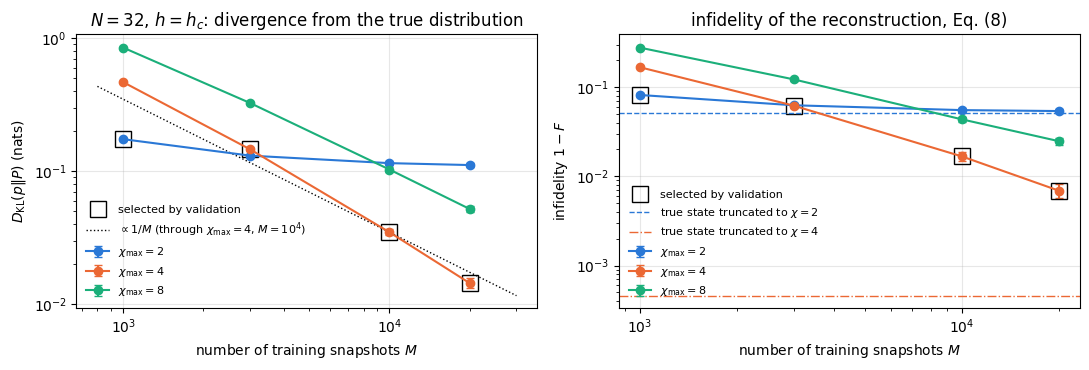

In [10]:
# ==============================================================================
# STEP 4: KL divergence and fidelity against M and chi_max at the critical point, N = 32
# ==============================================================================
H_A, N_A = 1.0, 32
B_A = GS[N_A][H_A]["B"]
V_TEST = snapshots(30, B_A, 20000)
LNP_TEST = 2 * np.asarray(log_amplitude(B_A, jnp.asarray(V_TEST)))
S_p = mean_se(-LNP_TEST)
print(f"Shannon entropy of the Z snapshots, S(p) = {S_p[0]:.3f} +- {S_p[1]:.3f} nats  (ln 2^32 = {32 * np.log(2):.2f})")


def truncate_mps(B, chi):
    """Truncate a right-canonical MPS (norm on site 0) to bond dimension chi by one left-to-right SVD sweep.

    MATH            centre C_j (a s, b) = U S V^dag;  A_j = U[:, :chi];  C_{j+1} = (S V^dag)[:chi] A_{j+1};  normalise
    RETURNS         padded MPS of the same array shape (NumPy), and the discarded weights of the N-1 bonds
    """
    A = np.array(B)
    n_s, c_s = A.shape[0], A.shape[1]
    eps = []
    for j in range(n_s - 1):
        U, S, Vh = np.linalg.svd(A[j].reshape(2 * c_s, c_s), full_matrices=False)
        eps.append(np.sum(S[chi:] ** 2) / np.sum(S ** 2))
        S = np.where(np.arange(S.size) < chi, S, 0.0)
        A[j] = (U * (S > 0)).reshape(c_s, 2, c_s)
        A[j + 1] = np.einsum("ab,bsc->asc", S[:, None] * Vh, A[j + 1])
    A[-1] /= np.linalg.norm(A[-1])
    return A, np.array(eps)


INF_TRUNC = {}
for chi in (2, 4, 8):                                       # best MPS of bond dimension chi, to a good approximation
    Bt, eps_t = truncate_mps(B_A, chi)
    INF_TRUNC[chi] = 1 - abs(complex(mps_overlap(B_A, jnp.asarray(Bt, dtype=CDTYPE)))) ** 2
    print(f"true state truncated to chi = {chi}: largest discarded weight at a bond {eps_t.max():.1e}, sum over the "
          f"31 bonds {eps_t.sum():.1e};  infidelity 1 - F = {INF_TRUNC[chi]:.1e}")

M_LIST, CHI_LIST = (1000, 3000, 10000, 20000), (2, 4, 8)
SCAN_A = {}
for M in M_LIST:
    v, v_val = snapshots(31, B_A, M), snapshots(32, B_A, M // 4)
    for chi in CHI_LIST:
        t0 = time.perf_counter()
        As, loop, val = train_born(v, v_val, chi)
        SCAN_A[M, chi] = dict(fidelity_kl(As, V_TEST, LNP_TEST, B_A), loop=loop, val=val[loop - 1], As=As,
                              time=time.perf_counter() - t0)
    best = min(CHI_LIST, key=lambda c: SCAN_A[M, c]["val"])
    for chi in CHI_LIST:
        r = SCAN_A[M, chi]
        print(f"M = {M:5d}, chi_max = {chi}{' (selected)' if chi == best else '           '}: best loop {r['loop']}, "
              f"validation NLL {r['val']:.3f};  D_KL = {r['kl']:.4f} +- {r['kl_se']:.4f};  F = {r['F']:.4f} +- "
              f"{r['F_se']:.4f};  exp(-D_KL) = {np.exp(-r['kl']):.4f};  |<psi|phi>|^2 = {r['F_mps']:.4f};  F^(1/N) = {r['F'] ** (1 / N_A):.5f};  {r['time']:.1f} s")
    SCAN_A[M, "best"] = best

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for k, chi in enumerate(CHI_LIST):
    kl = np.array([SCAN_A[M, chi]["kl"] for M in M_LIST])
    inf = np.array([1 - SCAN_A[M, chi]["F"] for M in M_LIST])
    axes[0].errorbar(M_LIST, kl, yerr=[SCAN_A[M, chi]["kl_se"] for M in M_LIST], fmt="o-", color=PALETTE[k],
                     capsize=3, label=rf"$\chi_{{\max}}={chi}$")
    axes[1].errorbar(M_LIST, inf, yerr=[SCAN_A[M, chi]["F_se"] for M in M_LIST], fmt="o-", color=PALETTE[k],
                     capsize=3, label=rf"$\chi_{{\max}}={chi}$")
sel = [SCAN_A[M, SCAN_A[M, "best"]] for M in M_LIST]
axes[0].plot(M_LIST, [r["kl"] for r in sel], "ks", mfc="none", ms=11, label="selected by validation")
axes[1].plot(M_LIST, [1 - r["F"] for r in sel], "ks", mfc="none", ms=11, label="selected by validation")
Mg = np.array([800, 30000])
axes[0].plot(Mg, SCAN_A[10000, 4]["kl"] * (1e4 / Mg), "k:", lw=1, label=r"$\propto 1/M$ (through $\chi_{\max}=4$, $M=10^4$)")
for chi, ls in ((2, "--"), (4, "-.")):
    axes[1].axhline(INF_TRUNC[chi], color=PALETTE[CHI_LIST.index(chi)], ls=ls, lw=1,
                    label=rf"true state truncated to $\chi={chi}$")
for ax in axes:
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("number of training snapshots $M$")
    ax.legend(fontsize=8)
axes[0].set_ylabel(r"$D_{\rm KL}(p\Vert P)$ (nats)")
axes[1].set_ylabel(r"infidelity $1-F$")
axes[0].set_title(r"$N=32$, $h=h_c$: divergence from the true distribution")
axes[1].set_title("infidelity of the reconstruction, Eq. (8)")
fig.tight_layout()
plt.show()

**Interpretation.** The snapshot distribution at the critical point has an entropy of $15.25$ nats, so a typical
snapshot has probability $e^{-15.25}\approx2.4\times10^{-7}$ and the $M\leq20000$ training snapshots are almost all
different: the model must generalise from a tiny sample of the $2^{32}$ strings. The validation NLLs sit just above
$S(p)$, for example $15.265$ against $15.246$ for the selected model at $M=20000$, whose test divergence is $0.0144$.

* **$\chi_{\max}=2$** is limited by the truncation error. For $M\geq10^4$ its divergence levels off at $0.11$ nats and
  its fidelity at $0.946$, against the infidelity floor $5.2\times10^{-2}$ of the truncated true state (dashed line); at $M=1000$
  and $3000$ it is also limited by the data ($F=0.918$ and $0.937$).
* **$\chi_{\max}=4$** is limited by the data. Its divergence falls from $0.466$ to $0.0144$ nats between $M=1000$ and
  $20000$, close to the $1/M$ line, and its fidelity rises from $0.833$ to $0.9931\pm0.0012$, a fidelity per site of
  $F^{1/32}=0.99978$. Its truncation floor, $4.6\times10^{-4}$, lies far below.
* **$\chi_{\max}=8$** is worse than $\chi_{\max}=4$ at every $M$, although it can represent the state more accurately:
  with more parameters to estimate from the same snapshots, the statistical error is larger. Early stopping keeps the
  first loop in every $\chi_{\max}=8$ run, and the validation NLL after that loop is already above the
  $\chi_{\max}=4$ one, so the first sweep, which may grow the bond dimension up to 8 at once, already fits noise of the
  training set. These runs do not separate this training effect from the statistical error.

At $M=1000$ the validation set picks $\chi_{\max}=2$: with few snapshots the smaller model wins, because its larger
truncation error is outweighed by its smaller statistical error. Above it picks $\chi_{\max}=4$ (open squares), the best
of the three fidelities in every case (at $M=3000$ the first two caps are nearly tied on the validation set and in fidelity).
The bound (9) holds in every run, and the overlap of the MPS $\phi$ itself stays within $0.002$ of $F$ for the selected
models: with the positive initial state the training rarely flips a sign. For the overfitted $\chi_{\max}=8$ model at
$M=1000$ it is $0.634$ against $F=0.723$; Eq. (7) recovers the difference.

### 4.7 Across the transition: fidelity and observables

The same procedure, with $M=10000$ snapshots and $\chi_{\max}\in\{2,4\}$ selected on the validation set
($\chi_{\max}=8$ was never selected in Section 4.6), is applied at five fields. For every reconstruction the cell
evaluates, from $4000$ samples of the model, the energy per site, the transverse magnetisation $\langle X_{16}\rangle$
in the middle of the chain and the correlator $\langle Z_8Z_{24}\rangle$, and compares them with the DMRG values and the
energy with the exact one. It also prints the lower bound on the energy error that follows from the fidelity: writing
$\psi_{\rm rec}=\sqrt F\,\psi_0+\sqrt{1-F}\,\psi_\perp$ with $\psi_\perp$ orthogonal to the ground state,
$\langle H\rangle-E_0=(1-F)(\langle\psi_\perp\vert H\vert\psi_\perp\rangle-E_0)\geq(1-F)\Delta$, with $\Delta=E_1-E_0$ the
gap of the open chain. $E_1$ lies in the odd parity sector, which does not change the bound. The quasi-particle energies of the open
chain are twice the singular values of the bidiagonal matrix that gives the exact energy, so $\Delta$ is twice the
smallest one, as derived in
[notebook 47, quantum phase transitions](../ch11_quantum_phase_transitions/47_quantum_phase_transitions.ipynb)
(Section 2.3). The direct baselines use snapshots: $\langle Z_8Z_{24}\rangle$ as the mean over the $10000$
training snapshots, and the energy from $5000$ of them and $5000$ new $X$ snapshots, $10000$ in all, against the
$Z$ snapshots of the reconstruction, $10000$ for training and $M/4$ for validation. At $h=1$ the training is repeated on three
independent data sets to measure the spread of the reconstruction itself.

h = 0.5: chi_max = 2 (validation NLL 2: 3.869, 4: 3.869), best loop 8 of 8 (change of the validation NLL in the last loop -0.0000);  S(p) = 3.935;  D_KL = 0.0244 +- 0.0021,  F = 0.9919 +- 0.0015,  F^(1/N) = 0.99975
      E/N: reconstruction -1.03533 +- 0.00024,  direct (Z + X) -1.03669 +- 0.00179,  exact -1.03634;  (E - E_0)/N = 0.00100 >= (1 - F) gap / N = 8.8e-14
      <X_16>: reconstruction 0.2548 +- 0.0155,  DMRG 0.2587;   <Z_8 Z_24>: reconstruction 0.9335 +- 0.0057,  direct 0.9348 +- 0.0036,  DMRG 0.9306


h = 0.8: chi_max = 4 (validation NLL 2: 8.849, 4: 8.704), best loop 3 of 8 (change of the validation NLL in the last loop -0.0015);  S(p) = 8.678;  D_KL = 0.0601 +- 0.0032,  F = 0.9736 +- 0.0022,  F^(1/N) = 0.99917
      E/N: reconstruction -1.14354 +- 0.00053,  direct (Z + X) -1.14992 +- 0.00279,  exact -1.14767;  (E - E_0)/N = 0.00413 >= (1 - F) gap / N = 4.7e-07
      <X_16>: reconstruction 0.4208 +- 0.0138,  DMRG 0.4445;   <Z_8 Z_24>: reconstruction 0.7655 +- 0.0102,  direct 0.7574 +- 0.0065,  DMRG 0.7654


h = 1.0: chi_max = 4 (validation NLL 2: 15.321, 4: 15.242), best loop 1 of 8 (change of the validation NLL in the last loop +0.0004);  S(p) = 15.256;  D_KL = 0.0341 +- 0.0019,  F = 0.9835 +- 0.0018,  F^(1/N) = 0.99948
      E/N: reconstruction -1.25829 +- 0.00043,  direct (Z + X) -1.25720 +- 0.00335,  exact -1.26201;  (E - E_0)/N = 0.00372 >= (1 - F) gap / N = 5.0e-05
      <X_16>: reconstruction 0.6560 +- 0.0118,  DMRG 0.6521;   <Z_8 Z_24>: reconstruction 0.1695 +- 0.0156,  direct 0.1838 +- 0.0098,  DMRG 0.1973


h = 1.2: chi_max = 2 (validation NLL 2: 18.528, 4: 18.544), best loop 1 of 8 (change of the validation NLL in the last loop +0.0000);  S(p) = 18.466;  D_KL = 0.0195 +- 0.0014,  F = 0.9907 +- 0.0014,  F^(1/N) = 0.99971
      E/N: reconstruction -1.41103 +- 0.00024,  direct (Z + X) -1.40677 +- 0.00347,  exact -1.41184;  (E - E_0)/N = 0.00081 >= (1 - F) gap / N = 1.3e-04
      <X_16>: reconstruction 0.7904 +- 0.0093,  DMRG 0.7926;   <Z_8 Z_24>: reconstruction -0.0075 +- 0.0158,  direct 0.0004 +- 0.0100,  DMRG 0.0098


h = 1.5: chi_max = 2 (validation NLL 2: 20.178, 4: 20.204), best loop 7 of 8 (change of the validation NLL in the last loop +0.0000);  S(p) = 20.111;  D_KL = 0.0091 +- 0.0009,  F = 0.9950 +- 0.0009,  F^(1/N) = 0.99984
      E/N: reconstruction -1.66558 +- 0.00020,  direct (Z + X) -1.66584 +- 0.00352,  exact -1.66618;  (E - E_0)/N = 0.00060 >= (1 - F) gap / N = 1.6e-04
      <X_16>: reconstruction 0.8784 +- 0.0075,  DMRG 0.8773;   <Z_8 Z_24>: reconstruction 0.0035 +- 0.0158,  direct 0.0046 +- 0.0100,  DMRG 0.0002



h = 1, three independent data sets of 10000 snapshots, chi_max = 4:  F = 0.9849, 0.9817, 0.9891;  E/N = -1.25887 (spread 0.00048);  <X_16> = 0.6408 (spread 0.0116)


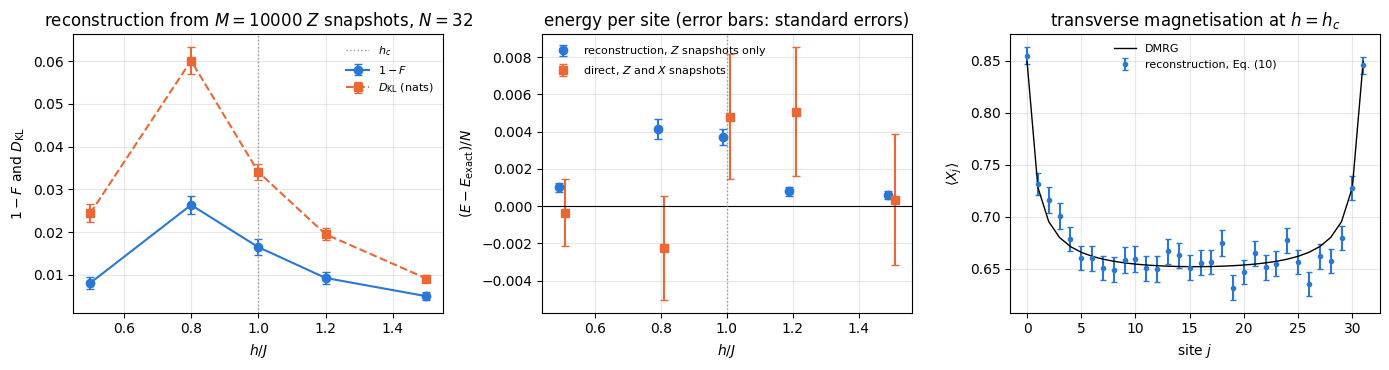

In [11]:
# ==============================================================================
# STEP 5: reconstructions at five fields, observables against DMRG and against direct estimates
# ==============================================================================
FIELDS_A = (0.5, 0.8, 1.0, 1.2, 1.5)
M_A = 10000
REC = {}
for i, h in enumerate(FIELDS_A):
    gs = GS[N_A][h]
    v, v_val = snapshots(40 + i, gs["B"], M_A), snapshots(50 + i, gs["B"], M_A // 4)
    As, chi, loop, table, val_hist = select_and_train(v, v_val, chis=(2, 4))
    v_t = snapshots(60 + i, gs["B"], 20000)
    lnp_t = 2 * np.asarray(log_amplitude(gs["B"], jnp.asarray(v_t)))
    met = fidelity_kl(As, v_t, lnp_t, gs["B"])
    gap = 2.0 * np.min(np.linalg.svd(h * np.eye(N_A) + np.eye(N_A, k=1), compute_uv=False))   # exact E_1 - E_0
    obs = local_observables(lambda s: log_psi(As, jnp.asarray(s)), model_samples(70 + i, As, 4000), h)
    zs = model_samples(80 + i, As, 4000)
    zz_rec = mean_se((1 - 2 * zs[:, 8]) * (1 - 2 * zs[:, 24]))
    zz_dir = mean_se((1 - 2 * v[:, 8]) * (1 - 2 * v[:, 24]))
    vz, vx = v[:5000], snapshots(90 + i, gs["B"], 5000, "x")
    e_dir = mean_se(-np.sum((1 - 2 * vz[:, :-1]) * (1 - 2 * vz[:, 1:]), axis=1)) , mean_se(-h * np.sum(1 - 2 * vx, axis=1))
    REC[h] = dict(met=met, chi=chi, loop=loop, obs=obs, zz_rec=zz_rec, zz_dir=zz_dir, gap=gap,
                  E_dir=(e_dir[0][0] + e_dir[1][0], np.hypot(e_dir[0][1], e_dir[1][1])),
                  X_dmrg=float(mps_expect_sites(gs["B"], gs["lam"], X)[16]),
                  ZZ_dmrg=float(mps_correlator(gs["B"], gs["lam"], Z, 8, Z, 24)), E_exact=tfim_exact_energy(N_A, h))
    r = REC[h]
    print(f"h = {h}: chi_max = {chi} (validation NLL " + ", ".join(f"{c}: {t:.3f}" for c, t in table.items())
          + f"), best loop {loop} of {len(val_hist)} (change of the validation NLL in the last loop "
          f"{val_hist[-1] - val_hist[-2]:+.4f});  S(p) = {np.mean(-lnp_t):.3f};  D_KL = {met['kl']:.4f} +- "
          f"{met['kl_se']:.4f},  F = {met['F']:.4f} +- {met['F_se']:.4f},  F^(1/N) = {met['F'] ** (1 / N_A):.5f}")
    print(f"      E/N: reconstruction {obs['E'][0] / N_A:.5f} +- {obs['E'][1] / N_A:.5f},  direct (Z + X) "
          f"{r['E_dir'][0] / N_A:.5f} +- {r['E_dir'][1] / N_A:.5f},  exact {r['E_exact'] / N_A:.5f};  "
          f"(E - E_0)/N = {(obs['E'][0] - r['E_exact']) / N_A:.5f} >= (1 - F) gap / N = {(1 - met['F']) * gap / N_A:.1e}")
    print(f"      <X_16>: reconstruction {obs['X'][0][16]:.4f} +- {obs['X'][1][16]:.4f},  DMRG {r['X_dmrg']:.4f};   "
          f"<Z_8 Z_24>: reconstruction {zz_rec[0]:.4f} +- {zz_rec[1]:.4f},  direct {zz_dir[0]:.4f} +- {zz_dir[1]:.4f},  "
          f"DMRG {r['ZZ_dmrg']:.4f}")

# spread of the reconstruction over independent data sets at h = 1 (chi_max = 4)
rep = []
for k in range(3):
    v, v_val = snapshots(100 + k, B_A, M_A), snapshots(110 + k, B_A, M_A // 4)
    As, _, _ = train_born(v, v_val, 4)
    o = local_observables(lambda s: log_psi(As, jnp.asarray(s)), model_samples(120 + k, As, 4000), H_A)
    rep.append([fidelity_kl(As, V_TEST, LNP_TEST)["F"], o["E"][0] / N_A, o["X"][0][16]])
rep = np.array(rep)
print(f"\nh = 1, three independent data sets of {M_A} snapshots, chi_max = 4:  F = "
      + ", ".join(f"{x:.4f}" for x in rep[:, 0]) + f";  E/N = {rep[:, 1].mean():.5f} (spread {rep[:, 1].std(ddof=1):.5f});"
      f"  <X_16> = {rep[:, 2].mean():.4f} (spread {rep[:, 2].std(ddof=1):.4f})")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
hs = np.array(FIELDS_A)
axes[0].errorbar(hs, [1 - REC[h]["met"]["F"] for h in hs], yerr=[REC[h]["met"]["F_se"] for h in hs], fmt="o-",
                 capsize=3, label=r"$1-F$")
axes[0].errorbar(hs, [REC[h]["met"]["kl"] for h in hs], yerr=[REC[h]["met"]["kl_se"] for h in hs], fmt="s--",
                 capsize=3, label=r"$D_{\rm KL}$ (nats)")
axes[0].axvline(1.0, color="0.6", ls=":", lw=1, label=r"$h_c$")
axes[0].set_xlabel("$h/J$")
axes[0].set_ylabel(r"$1-F$ and $D_{\rm KL}$")
axes[0].set_title(rf"reconstruction from $M={M_A}$ $Z$ snapshots, $N={N_A}$")
axes[0].legend(fontsize=8)
de_rec = [(REC[h]["obs"]["E"][0] - REC[h]["E_exact"]) / N_A for h in hs]
de_dir = [(REC[h]["E_dir"][0] - REC[h]["E_exact"]) / N_A for h in hs]
axes[1].errorbar(hs - 0.01, de_rec, yerr=[REC[h]["obs"]["E"][1] / N_A for h in hs], fmt="o", capsize=3,
                 label="reconstruction, $Z$ snapshots only")
axes[1].errorbar(hs + 0.01, de_dir, yerr=[REC[h]["E_dir"][1] / N_A for h in hs], fmt="s", capsize=3,
                 color=PALETTE[1], label="direct, $Z$ and $X$ snapshots")
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_xlabel("$h/J$")
axes[1].set_ylabel(r"$(E-E_{\rm exact})/N$")
axes[1].axvline(1.0, color="0.6", ls=":", lw=1)
axes[1].set_title("energy per site (error bars: standard errors)")
axes[1].legend(fontsize=8)
o1 = REC[1.0]["obs"]
X_dmrg_prof = np.asarray(mps_expect_sites(gs32["B"], gs32["lam"], X))
axes[2].errorbar(np.arange(N_A), o1["X"][0], yerr=o1["X"][1], fmt="o", ms=3, capsize=2,
                 label="reconstruction, Eq. (10)")
axes[2].plot(np.arange(N_A), X_dmrg_prof, "k-", lw=1, label="DMRG")
axes[2].set_xlabel("site $j$")
axes[2].set_ylabel(r"$\langle X_j\rangle$")
axes[2].set_title(r"transverse magnetisation at $h=h_c$")
axes[2].legend(fontsize=8)
fig.tight_layout()
plt.show()

**Interpretation.** All five reconstructions reach $F\geq0.97$ from $10000$ snapshots of one basis, with fidelities per
site between $0.9992$ and $0.9998$. The hardest field is $h=0.8$ on the ordered side ($F=0.9736\pm0.0022$,
$D_{\rm KL}=0.060$ nats); at the critical point $F=0.9835\pm0.0018$. The validation NLL of the selected model lies
within $0.07$ nats of the entropy $S(p)$ at every field, on either side, since both are estimates from finite sets of
snapshots. The loop cap of 8 was reached at $h=0.5$, where the last loop changed the validation NLL by less than
$10^{-4}$, so the cap did not limit that run. At $h=0.5$, $1.2$ and $1.5$ the validation set selects $\chi_{\max}=2$.

The transverse magnetisation, never measured, is predicted from $Z$ snapshots alone: $\langle X_{16}\rangle$ agrees
with DMRG within $1.8$ standard errors at all five fields, and at $h_c$ the whole profile $\langle X_j\rangle$,
including its rise at the open ends, follows the DMRG curve (right panel). The three independent data sets at $h=1$
give $F=0.9849$, $0.9817$ and $0.9891$ and $\langle X_{16}\rangle$ values with a spread of $0.012$, as large as the
statistical error of one estimate, so a fair error bar of a reconstructed $\langle X_{16}\rangle$ is about
$\sqrt2$ times the printed one. The correlator $\langle Z_8Z_{24}\rangle$ of the reconstruction agrees with DMRG within
$1.8$ standard errors, as does its direct estimate from the snapshots.

The energy separates statistical error from bias. The reconstruction's energy per site has a statistical error of $2$ to
$5\times10^{-4}$, but it lies *above* the exact value at every field, by $0.0006$ to $0.0041$, and at $h=1$ the spread
over three data sets ($0.0005$) is far smaller than this offset. The sign follows from the variational principle: the
reconstruction is a normalised state, so its energy cannot lie below $E_0$. The size is not fixed by the fidelity. The
bound $(1-F)\Delta$ is printed for every field and lies far below the measured offsets; in the ordered phase $\Delta$ is
the exponentially small splitting of the two lowest levels, so a positive state far from the ground state, such as a
symmetry-broken one with $F\approx\frac12$, can have almost the ground-state energy. The direct estimate from $Z$ and
$X$ snapshots is unbiased and agrees with the exact energy within $1.5$ standard errors at every field. Its error,
$0.0018$ to $0.0035$ per site from $10000$ snapshots in two bases, is larger than the reconstruction's statistical error,
but at $h=0.8$ and $h=1$ the reconstruction's bias ($0.0041$ and $0.0037$) exceeds it, so there the direct estimate is
the more accurate one. The prior turns a single basis into precise estimates of the observables it gives, with a bias that
must be checked; the direct estimate is unbiased, noisier, and limited to what was measured.

### 4.8 Exact state-vector check of the reconstruction at $N=16$

At $N=16$ the reconstruction itself can be written out as a vector, $\psi_{\rm rec}=\vert\phi\vert/\Vert\phi\Vert$ from
the contracted Born machine, and graded without sampling against the exact ground state from Section 3.5. At $h=1$ the
cell trains three Born machines ($\chi_{\max}=4$, $M=10000$ plus $M/4$ validation snapshots, as in Section 4.7) on
snapshots from the DMRG state and one on the same number of snapshots drawn directly from the exact vector, by
inverse-transform sampling of $\vert\psi_{\rm ED}(\mathbf s)\vert^2$. For every model it prints the exact fidelity with
the exact state and with the DMRG state, and the exact energy per site, $\langle X_8\rangle$ and $\langle Z_4Z_{12}\rangle$
of $\psi_{\rm rec}$ against the exact values. For the first model it also prints the sampled estimates of Sections
4.3–4.4 (Eq. (8) from $20000$ test snapshots, the local energy from $4000$ model samples) next to the exact values of
the same reconstruction.

In [12]:
# ==============================================================================
# STEP 5b: the reconstruction at N = 16 against the exact state vector
# ==============================================================================
def ed_snapshots(seed, v, M):
    """M exact samples of |v(s)|^2 for a flat state vector v (inverse-transform sampling).  RETURNS bits (M, N)."""
    cdf = np.cumsum(v ** 2)
    k = np.searchsorted(cdf / cdf[-1], np.random.default_rng(seed).random(M))
    return BITS[np.minimum(k, D_X - 1)]


def rec_vector(As):
    """psi_rec = |phi| / ||phi||, Eq. (7), as a flat vector of 2^N amplitudes (contracted Born machine, small N)."""
    phi = dense_state(As)
    return np.abs(phi) / np.linalg.norm(phi)


def vector_observables(v, h):
    """Exact energy per site, <X_8> and <Z_4 Z_12> of a real normalised flat vector at field h."""
    return v @ tfim_matvec(v, h) / N_X, v @ v[FLIP[8]], (v ** 2) @ (SPIN[:, 4] * SPIN[:, 12])


v_ed, v_dm = ED[1.0]["v"], ED[1.0]["v_mps"]
ref16 = vector_observables(v_ed, 1.0)
print(f"exact ground state, N = 16, h = 1:  E/N = {ref16[0]:.6f},  <X_8> = {ref16[1]:.5f},  <Z_4 Z_12> = {ref16[2]:.5f}")
REC16 = []
for k, source in enumerate(("DMRG", "DMRG", "DMRG", "exact vector")):
    if source == "DMRG":
        v, v_val = snapshots(140 + k, GS[N_X][1.0]["B"], M_A), snapshots(150 + k, GS[N_X][1.0]["B"], M_A // 4)
    else:
        v, v_val = ed_snapshots(160, v_ed, M_A), ed_snapshots(161, v_ed, M_A // 4)
    As16, _, _ = train_born(v, v_val, 4)
    r16 = rec_vector(As16)
    obs16 = vector_observables(r16, 1.0)
    REC16.append(dict(source=source, F_ed=(r16 @ v_ed) ** 2, F_dm=(r16 @ v_dm) ** 2, obs=obs16))
    print(f"snapshots from the {source:12s}: F with the exact state {(r16 @ v_ed) ** 2:.5f}, with DMRG {(r16 @ v_dm) ** 2:.5f};"
          f"  E/N = {obs16[0]:.6f} (offset {obs16[0] - ref16[0]:+.5f}),  <X_8> = {obs16[1]:.5f},  <Z_4 Z_12> = {obs16[2]:.5f}")
    if k == 0:
        v_t = snapshots(170, GS[N_X][1.0]["B"], 20000)
        met16 = fidelity_kl(As16, v_t, 2 * np.asarray(log_amplitude(GS[N_X][1.0]["B"], jnp.asarray(v_t))))
        v_t2 = snapshots(300, GS[N_X][1.0]["B"], 200000)
        met16b = fidelity_kl(As16, v_t2, 2 * np.asarray(log_amplitude(GS[N_X][1.0]["B"], jnp.asarray(v_t2))))
        lo16 = local_observables(lambda s_: log_psi(As16, jnp.asarray(s_)), model_samples(171, As16, 4000), 1.0)
        print(f"      sampled estimates of the same model: F = {met16['F']:.4f} +- {met16['F_se']:.4f} (Eq. (8), 20000 test "
              f"snapshots; {(met16['F'] - (r16 @ v_ed) ** 2) / met16['F_se']:+.1f} standard errors from the exact value), "
              f"{met16b['F']:.4f} +- {met16b['F_se']:.4f} (200000 test snapshots; "
              f"{(met16b['F'] - (r16 @ v_ed) ** 2) / met16b['F_se']:+.1f} standard errors),  "
              f"E/N = {lo16['E'][0] / N_X:.5f} +- {lo16['E'][1] / N_X:.5f},  <X_8> = {lo16['X'][0][8]:.4f} +- {lo16['X'][1][8]:.4f}")
F_dmrg_runs = np.array([r["F_ed"] for r in REC16[:3]])
print(f"three models from DMRG snapshots: F = {F_dmrg_runs.mean():.5f}, spread {F_dmrg_runs.std(ddof=1):.5f};  model from "
      f"exact-vector snapshots: F = {REC16[3]['F_ed']:.5f}, {abs(REC16[3]['F_ed'] - F_dmrg_runs.mean()) / F_dmrg_runs.std(ddof=1):.1f} "
      f"spreads from their mean")

exact ground state, N = 16, h = 1:  E/N = -1.251024,  <X_8> = 0.66730,  <Z_4 Z_12> = 0.23646


snapshots from the DMRG        : F with the exact state 0.99181, with DMRG 0.99181;  E/N = -1.247516 (offset +0.00351),  <X_8> = 0.66407,  <Z_4 Z_12> = 0.23316


      sampled estimates of the same model: F = 0.9952 +- 0.0013 (Eq. (8), 20000 test snapshots; +2.7 standard errors from the exact value), 0.9923 +- 0.0004 (200000 test snapshots; +1.3 standard errors),  E/N = -1.24870 +- 0.00066,  <X_8> = 0.6744 +- 0.0121


snapshots from the DMRG        : F with the exact state 0.99263, with DMRG 0.99263;  E/N = -1.248094 (offset +0.00293),  <X_8> = 0.66183,  <Z_4 Z_12> = 0.23470


snapshots from the DMRG        : F with the exact state 0.99049, with DMRG 0.99049;  E/N = -1.246817 (offset +0.00421),  <X_8> = 0.65495,  <Z_4 Z_12> = 0.21484


snapshots from the exact vector: F with the exact state 0.99257, with DMRG 0.99257;  E/N = -1.247812 (offset +0.00321),  <X_8> = 0.65499,  <Z_4 Z_12> = 0.22280
three models from DMRG snapshots: F = 0.99164, spread 0.00108;  model from exact-vector snapshots: F = 0.99257, 0.9 spreads from their mean


**Interpretation.** The exact ground state at $N=16$, $h=1$ has $E/N=-1.251024$, $\langle X_8\rangle=0.66730$ and
$\langle Z_4Z_{12}\rangle=0.23646$. The three reconstructions from DMRG snapshots reach $F=0.99181$, $0.99263$ and
$0.99049$, the same to all printed digits whether graded against the exact vector or against the DMRG state, since the
two states differ by an infidelity of order $10^{-14}$ (Section 3.5). The model trained on snapshots drawn from the
exact vector reaches $0.99257$, 0.9 spreads from the mean $0.99164$ of the other three: the source of the snapshots
makes no difference within the spread of the training. Without sampling noise, the reconstructions show the pattern
of Section 4.7: the energy per site lies above the exact value at every model, by $0.00293$ to $0.00421$, and
$\langle X_8\rangle$ and $\langle Z_4Z_{12}\rangle$ lie below the exact values in all four models.

The sampled estimates of the first model are checked against its exact values. With $20000$ test snapshots,
Eq. (8) gives $F=0.9952\pm0.0013$, $2.7$ standard errors above the exact $0.99181$; with $200000$ test snapshots it
gives $0.9923\pm0.0004$, $1.3$ standard errors from it, so the first value is a statistical fluctuation. The local energy,
$-1.24870\pm0.00066$, and $\langle X_8\rangle=0.6744\pm0.0121$ agree with the exact values of the same reconstruction,
$-1.247516$ and $0.66407$, within two standard errors.

### 4.9 Where one basis is not enough: signs and mixed states

Two states produce exactly the same $Z$ snapshots as the ground state $\vert\psi\rangle$ at $h=1$:

* the **signed state** $\vert\psi_\sigma\rangle=\prod_{j\ {\rm odd}}Z_j\vert\psi\rangle$, with amplitudes
  $\psi_\sigma(\mathbf s)=\sigma(\mathbf s)\psi(\mathbf s)$, $\sigma(\mathbf s)=(-1)^{\sum_{j\,{\rm odd}}s_j}$. It is the
  ground state of $-J\sum_iZ_iZ_{i+1}-h\sum_j(-1)^jX_j$, whose off-diagonal elements on the odd sites are positive:
  this Hamiltonian is not stoquastic in the $Z$ basis;
* the **dephased state** $\rho_{\rm d}=\sum_{\mathbf s}p(\mathbf s)\vert\mathbf s\rangle\langle\mathbf s\vert$, the ground
  state after complete dephasing in the $Z$ basis: a classical mixture with the same diagonal.

The reconstruction from $Z$ snapshots is the same in all three cases, $\psi_{\rm rec}=\sqrt P\approx\psi$. Its fidelity
with the signed state is $\vert\langle\psi_\sigma\vert\psi_{\rm rec}\rangle\vert^2$, estimated by Eq. (8) with the
factor $\sigma(\mathbf s)$ inside the mean; a perfect reconstruction would give
$\langle\psi\vert\prod_{j\,{\rm odd}}Z_j\vert\psi\rangle^2$, computed exactly from the MPS. Its fidelity with the mixed
state is $\langle\psi_{\rm rec}\vert\rho_{\rm d}\vert\psi_{\rm rec}\rangle=\sum_{\mathbf s}p(\mathbf s)P(\mathbf s)$, the
mean of $P$ over test snapshots.

The $X$ basis tells the three states apart. Since $X_j$ flips bit $j$, and flipping an odd bit changes the sign
$\sigma$, $\langle\psi_\sigma\vert X_j\vert\psi_\sigma\rangle=(-1)^j\langle\psi\vert X_j\vert\psi\rangle$: the transverse
magnetisation alternates in sign. For $\rho_{\rm d}$, every $X$-basis string $\mathbf x$ has the probability
$\sum_{\mathbf s}p(\mathbf s)\vert\langle\mathbf x\vert\mathbf s\rangle\vert^2=2^{-N}$, because
$\vert\langle\mathbf x\vert\mathbf s\rangle\vert^2=2^{-N}$ for every pair; its $X$ snapshots are uniformly random bits and
every $\langle X_j\rangle$ vanishes. The reconstruction predicts $\langle X_j\rangle>0$ on every site (Eq. (10) is a mean
of positive numbers), and $X$ snapshots of either state contradict it.

For the signed state the $X$ data also repair the reconstruction, within a restricted class. If the true state is
$\prod_jg_j^{s_j}\sqrt{p(\mathbf s)}$ with unknown signs $g_j=\pm1$ (a positive state rotated by $Z$ on some sites), then
$\langle X_j\rangle=g_j\langle X_j\rangle_{\psi}$, and the sign of the measured $\langle X_j\rangle$ is $g_j$. The cell
uses the $M=10000$, $\chi_{\max}=4$ reconstruction of Section 4.6, measures $\langle X_j\rangle$ from $2000$ $X$
snapshots of $\psi_\sigma$ and of $\rho_{\rm d}$, compares them with the prediction of the reconstruction, reads off the
$g_j$, and computes the fidelity of the corrected reconstruction. Each comparison uses a combined error: the standard
error of the $X$ data, that of the 4000 model samples, and the spread of the reconstruction over independent data sets
measured in Section 4.7.

In [13]:
# ==============================================================================
# STEP 6: a signed state and a dephased state with the same Z snapshots
# ==============================================================================
odd = (np.arange(N_A) % 2 == 1)
sigma_fn = lambda v: (-1.0) ** np.sum(v[:, odd], axis=1)
Zodd = np.where(odd[:, None, None], np.diag([1.0, -1.0])[None], np.eye(2)[None])          # (N, 2, 2): Z on odd sites
B_sig = jnp.einsum("jst,jatb->jasb", jnp.asarray(Zodd, dtype=CDTYPE), B_A)                 # MPS of psi_sigma
string_odd = float(np.real(complex(mps_overlap(B_A, B_sig))))
As_rec = SCAN_A[10000, 4]["As"]                                                          # the M = 10^4 model of Sec. 4.6
r_sig = sigma_fn(V_TEST) * np.exp(0.5 * ((2 * np.asarray(log_psi(As_rec, jnp.asarray(V_TEST)))
                                           - float(log_Z_transfer(As_rec))) - LNP_TEST))
F_sig = mean_se(r_sig)
F_rec = fidelity_kl(As_rec, V_TEST, LNP_TEST)["F"]
print(f"<psi| prod_odd Z |psi> = {string_odd:.4f}:  a perfect reconstruction would have fidelity {string_odd ** 2:.1e} "
      f"with psi_sigma")
print(f"reconstruction (M = 10^4, chi_max = 4): F with psi = {F_rec:.4f},  F with psi_sigma = {F_sig[0] ** 2:.4f} "
      f"+- {2 * abs(F_sig[0]) * F_sig[1]:.4f}")
F_deph = mean_se(np.exp(2 * np.asarray(log_psi(As_rec, jnp.asarray(V_TEST))) - float(log_Z_transfer(As_rec))))
print(f"F with the dephased state = sum_s p(s) P(s) = mean of P over test snapshots = {F_deph[0]:.1e} +- {F_deph[1]:.1e}")

import math

M_X = 2000
x_sig = snapshots(130, B_sig, M_X, "x")
x_deph = (np.random.default_rng(131).random((M_X, N_A)) < 0.5).astype(int)    # X snapshots of rho_d: uniform bits
X_sig, X_deph = mean_se(1 - 2 * x_sig), mean_se(1 - 2 * x_deph)
obs_rec = local_observables(lambda s: log_psi(As_rec, jnp.asarray(s)), model_samples(132, As_rec, 4000), H_A)
X_pred = obs_rec["X"][0]
SPREAD_X = rep[:, 2].std(ddof=1)            # spread of <X_16> over independent data sets (Section 4.7)
err_pred = np.sqrt(X_sig[1] ** 2 + obs_rec["X"][1] ** 2 + SPREAD_X ** 2)
z_sig = (X_sig[0] - X_pred) / err_pred
z_deph = (X_deph[0] - X_pred) / np.sqrt(X_deph[1] ** 2 + obs_rec["X"][1] ** 2 + SPREAD_X ** 2)
print(f"\n<X_j> from {M_X} X snapshots of psi_sigma, sites 0-5: " + ", ".join(f"{x:+.3f}" for x in X_sig[0][:6])
      + f"  (standard error about {X_sig[1].mean():.3f});  reconstruction predicts " + ", ".join(f"{x:+.3f}" for x in X_pred[:6]))
print(f"   deviation from the prediction in units of the combined error (data, model samples, data-set spread "
      f"{SPREAD_X:.3f}; about {err_pred.mean():.3f}): odd sites median {np.median(np.abs(z_sig[odd])):.0f}, "
      f"even sites largest {np.abs(z_sig[~odd]).max():.2f} (probability of a maximum at least this large among 16 "
      f"independent normal deviations: {1 - (1 - math.erfc(np.abs(z_sig[~odd]).max() / np.sqrt(2))) ** 16:.2f})")
print(f"<X_j> from {M_X} X snapshots of rho_d, sites 0-5: " + ", ".join(f"{x:+.3f}" for x in X_deph[0][:6])
      + f";  all 32 sites: largest |<X_j>| / standard error {np.max(np.abs(X_deph[0] / X_deph[1])):.1f};  "
      f"median deviation from the prediction {np.median(np.abs(z_deph)):.0f} combined errors")
g = np.sign(X_sig[0])
print(f"signs g_j read from the X data: {int(np.sum(g == np.where(odd, -1, 1)))} of {N_A} correct")
r_fix = sigma_fn(V_TEST) * np.prod(np.where(V_TEST == 1, g[None, :], 1.0), axis=1) * np.exp(
    0.5 * ((2 * np.asarray(log_psi(As_rec, jnp.asarray(V_TEST))) - float(log_Z_transfer(As_rec))) - LNP_TEST))
F_fix = mean_se(r_fix)
print(f"corrected reconstruction prod_j g_j^(s_j) sqrt(P): F with psi_sigma = {F_fix[0] ** 2:.4f} +- "
      f"{2 * F_fix[0] * F_fix[1]:.4f}")

<psi| prod_odd Z |psi> = 0.0048:  a perfect reconstruction would have fidelity 2.3e-05 with psi_sigma
reconstruction (M = 10^4, chi_max = 4): F with psi = 0.9833,  F with psi_sigma = 0.0001 +- 0.0001
F with the dephased state = sum_s p(s) P(s) = mean of P over test snapshots = 7.3e-05 +- 3.3e-06



<X_j> from 2000 X snapshots of psi_sigma, sites 0-5: +0.854, -0.727, +0.712, -0.701, +0.679, -0.662  (standard error about 0.016);  reconstruction predicts +0.835, +0.690, +0.679, +0.651, +0.657, +0.653
   deviation from the prediction in units of the combined error (data, model samples, data-set spread 0.012; about 0.023): odd sites median 56, even sites largest 2.96 (probability of a maximum at least this large among 16 independent normal deviations: 0.05)
<X_j> from 2000 X snapshots of rho_d, sites 0-5: +0.007, +0.005, -0.034, -0.003, +0.023, +0.004;  all 32 sites: largest |<X_j>| / standard error 1.9;  median deviation from the prediction 24 combined errors
signs g_j read from the X data: 32 of 32 correct
corrected reconstruction prod_j g_j^(s_j) sqrt(P): F with psi_sigma = 0.9833 +- 0.0018


**Interpretation.** For the signed state the string $\langle\psi\vert\prod_{j\,{\rm odd}}Z_j\vert\psi\rangle$ is only
$0.0048$ at the critical point, so even a perfect positive reconstruction would have a fidelity of $2.3\times10^{-5}$
with $\psi_\sigma$; the actual one has $0.0001\pm0.0001$. With the dephased state the fidelity is
$7.3\times10^{-5}$, with a standard error of $3.3\times10^{-6}$. Both reconstructions are useless, although the $Z$ snapshots are exactly those of a state
reconstructed with $F=0.9833$.

The $X$ snapshots reveal both failures. For $\psi_\sigma$ the measured $\langle X_j\rangle$ alternate in sign, and on
the odd sites they deviate from the prediction of the reconstruction by a median of $56$ combined errors; on the even
sites the largest deviation is about 3 combined errors, and among 16 independent comparisons of a correct prediction a
maximum at least as large as the printed value occurs with a probability of $0.05$, so the even sites agree with the prediction to a
few combined errors. For $\rho_{\rm d}$ every $\langle X_j\rangle$ is compatible with zero (the largest of the 32 is
$1.9$ standard errors from zero), a median of $24$ combined errors from the prediction. The signs read from the $X$ data are
correct on all 32 sites, and the corrected reconstruction has the fidelity $0.9833\pm0.0018$ with $\psi_\sigma$, the
value the uncorrected one has with $\psi$. One extra basis was enough here because the unknown sign pattern had only
$N$ free bits; no second basis can repair a dephased state, which is not pure.

### 4.10 Towards general MPS tomography

A general state of $N$ qubits has $2^N$ signs or phases, and no fixed pair of bases determines them all. MPS
tomography, introduced in [[3]](#ref-3), keeps the cost polynomial in $N$ by measuring every block of $k$ neighbouring
qubits in a tomographically complete set of local bases, estimating the $k$-site reduced density matrices $\rho_i$, and
finding the MPS compatible with them by a singular-value thresholding iteration with DMRG-like steps. It also certifies
the result: the estimate $\vert\hat\psi\rangle$ is the ground state of a parent Hamiltonian $\sum_i\hat T_i$ of local
terms, and a lower bound on the fidelity of the laboratory state with $\vert\hat\psi\rangle$ follows from the measured
$\mathrm{tr}(\hat T_i\rho_i)$ and the gap of that Hamiltonian, without any assumption on the laboratory state. Giving
every $k$-th qubit the same Pauli basis measures all blocks at once, so $3^k$ settings suffice whatever $N$ is: $3^2=9$ or $3^3=27$
for $k=2$ or $3$, against $3^{32}\approx1.9\times10^{15}$ for full tomography of 32 qubits. The scheme was carried out
on up to 14 trapped ions in [[9]](#ref-9), with $k=3$. Generative models extend the same way: states with phases were
reconstructed in [[2]](#ref-2) by adding snapshots in rotated bases, and the MPS Born machine was trained on snapshots in
random local bases, which determine a pure state, in [[10]](#ref-10). The likelihood then becomes a sum over bases with
a complex MPS; the sign prior of Eq. (5) is dropped, and the data pay for it. A matrix product operator does the same
for mixed states, with two physical indices per site.

In [14]:
section_timer("5 classification")

## 5. Part B: locating the transition from labelled snapshots

### 5.1 The classifier and the training windows

Part B reconstructs nothing. Its question is one bit per field, "ordered or disordered?", and the data are again
snapshots. The approach of [[5]](#ref-5) trains on configurations labelled by their phase over a range of temperatures
on both sides of the transition and reads the transition off the crossing of the outputs, there for a lattice the
network was not trained on. An MPS classifier trained on $Z$ and $X$ snapshots of six central sites of 32-site
antiferromagnetic transverse-field Ising ground states, taken far from the transition, was studied in
[[11]](#ref-11); evaluated on entangled input states, translation-invariant matrix product states of the infinite chain
loaded on a trapped-ion quantum computer, it placed the transition at $h=0.962$ and $0.994$ (for classifier bond
dimensions 2 and 4), the point where the output crosses $\frac12$, located by a linear fit near the crossing; the test
states there describe the infinite chain.

We use the MPS classifier with two labels, $\ell=0$ (ordered) and $\ell=1$ (disordered). A snapshot is turned into a
product state of one-hot vectors $\mathbf e(s)=(1-s,\,s)$, so the score of a snapshot is a single component of the
weight MPS, $f^\ell(\mathbf s)=W^\ell_{s_0\cdots s_{N-1}}$, and the softmax of the two scores is the classifier
probability $q(\ell\vert\mathbf s)$. Training uses the sweeping algorithm of
[notebook 56, tensor networks as machine-learning models](56_tensor_networks_for_machine_learning.ipynb) (Section 6)
with the cross-entropy: two sweeps, bond dimension $\chi=4$, and at every bond 10 gradient steps with the step size
$1/\Lambda$, where $\Lambda$ is an upper bound on the curvature of the cost that guarantees that no step increases it
(derived there in Section 6.3). The training set has $500$ snapshots at each of the fields $h\in\{0.2,0.3,0.4,0.5\}$
(label ordered) and $h\in\{1.5,1.6,1.7,1.8\}$ (label disordered), all at least $0.5J$ from $h_c$. The trained classifier
is applied to $n_{\rm test}=500$ fresh snapshots at each of the 18 fields, and the mean probability of the label
"ordered",

$$\bar q_{\rm ord}(h)=\frac1{n_{\rm test}}\sum_{m=1}^{n_{\rm test}}q\big(\ell=0\,\vert\,\mathbf s_m\big),\qquad\mathbf s_m\sim p_h, \tag{12}$$

is recorded. The field $h^*(N)$ where $\bar q_{\rm ord}=\frac12$, found by linear interpolation between grid points, is
the transition seen by the classifier. Each experiment is repeated with three independent training and test sets; the
standard error of $h^*$ is the standard deviation of the three values divided by $\sqrt3$, a rough estimate with two
degrees of freedom.

In [15]:
# ==============================================================================
# STEP 7: training windows, MPS classifiers in both bases, q(ordered) against the field
# ==============================================================================
TRAIN_ORD, TRAIN_DIS = (0.2, 0.3, 0.4, 0.5), (1.5, 1.6, 1.7, 1.8)
N_PER, N_TEST, CHI_C, SWEEPS_C, REPEATS = 500, 500, 4, 2, 3


def snapshot_features(v):
    """Feature vector of a bit, e(s) = (1 - s, s) (one-hot), for every site of every snapshot:  v (M, N) -> (M, N, 2)."""
    return jax.nn.one_hot(jnp.asarray(v), 2, dtype=RDTYPE)


def train_classifier(v, y, chi, n_sweeps, n_steps=10, seed=6):
    """Sweeping training of the MPS classifier on snapshots v (M, N) with labels y (0 = ordered, 1 = disordered).

    n_sweeps sweeps (right + left), n_steps gradient steps per bond, bond dimension chi, fixed seed of the initial MPS
    """
    phi = snapshot_features(v)
    phiT = jnp.swapaxes(phi, 0, 1)
    Y = jax.nn.one_hot(jnp.asarray(y), N_LABELS, dtype=RDTYPE)
    As, C, Lst, Rst = init_sweep_mps(jax.random.PRNGKey(seed), phi.shape[1], chi, phiT)
    for _ in range(n_sweeps):
        As, C, Lst, cost_r, _ = half_sweep_right(As, C, Lst, Rst, phiT, Y, n_steps)
        As, C, Rst, cost_l, _ = half_sweep_left(As, C, Lst, Rst, phiT, Y, n_steps)
    return As, C, float(cost_l[-1])


def q_ordered(As, C, v):
    """Classifier probability q(ordered | s), the softmax of the two scores, for every snapshot."""
    return np.asarray(jax.nn.softmax(sweep_scores(As, C, snapshot_features(v)), axis=1)[:, 0])


def crossing(h, p, level=0.5):
    """Field where the curve p(h) (decreasing) crosses `level`, by linear interpolation between grid points."""
    k = int(np.argmax(p < level))
    return h[k - 1] + (p[k - 1] - level) * (h[k] - h[k - 1]) / (p[k - 1] - p[k])


CLS = {}
for N in SIZES:
    for basis in ("z", "x"):
        t0 = time.perf_counter()
        curves, costs, p_correct, models = [], [], [], []
        for rep_k in range(REPEATS):
            seed0 = 1000 * N + 100 * rep_k + (0 if basis == "z" else 50)
            v = np.concatenate([snapshots(seed0 + i, GS[N][h]["B"], N_PER, basis)
                                for i, h in enumerate(TRAIN_ORD + TRAIN_DIS)])
            y = np.repeat([0] * len(TRAIN_ORD) + [1] * len(TRAIN_DIS), N_PER)
            As_c, C_c, cost = train_classifier(v, y, CHI_C, SWEEPS_C)
            curve = np.array([q_ordered(As_c, C_c, snapshots(seed0 + 20 + i, GS[N][float(h)]["B"], N_TEST, basis)).mean()
                              for i, h in enumerate(FIELDS)])
            q_tr = np.mean([(curve[list(FIELDS).index(h)] if h in TRAIN_ORD else 1 - curve[list(FIELDS).index(h)])
                              for h in TRAIN_ORD + TRAIN_DIS])
            curves.append(curve)
            models.append((As_c, C_c))
            costs.append(cost)
            p_correct.append(q_tr)
        curves = np.array(curves)
        hx = np.array([crossing(FIELDS, c) for c in curves])
        CLS[N, basis] = dict(curves=curves, h_star=hx, models=models)
        print(f"N = {N:2d}, {basis} basis: training cross-entropy {np.mean(costs):.3f} (chance level ln 2 = "
              f"{np.log(2):.3f});  mean q(correct phase) on fresh snapshots of the training fields {np.mean(p_correct):.3f};"
              f"  crossing h* = {hx.mean():.3f} +- {hx.std(ddof=1) / np.sqrt(REPEATS):.3f}  (repeats: "
              + ", ".join(f"{x:.3f}" for x in hx) + f");  {(time.perf_counter() - t0) / REPEATS:.1f} s per classifier")

N = 16, z basis: training cross-entropy 0.100 (chance level ln 2 = 0.693);  mean q(correct phase) on fresh snapshots of the training fields 0.936;  crossing h* = 0.878 +- 0.006  (repeats: 0.886, 0.867, 0.880);  1.4 s per classifier


N = 16, x basis: training cross-entropy 0.140 (chance level ln 2 = 0.693);  mean q(correct phase) on fresh snapshots of the training fields 0.911;  crossing h* = 0.873 +- 0.007  (repeats: 0.885, 0.874, 0.860);  0.5 s per classifier


N = 32, z basis: training cross-entropy 0.041 (chance level ln 2 = 0.693);  mean q(correct phase) on fresh snapshots of the training fields 0.968;  crossing h* = 0.921 +- 0.004  (repeats: 0.915, 0.929, 0.918);  1.5 s per classifier


N = 32, x basis: training cross-entropy 0.059 (chance level ln 2 = 0.693);  mean q(correct phase) on fresh snapshots of the training fields 0.954;  crossing h* = 0.924 +- 0.006  (repeats: 0.915, 0.936, 0.920);  0.9 s per classifier


N = 64, z basis: training cross-entropy 0.021 (chance level ln 2 = 0.693);  mean q(correct phase) on fresh snapshots of the training fields 0.983;  crossing h* = 0.948 +- 0.004  (repeats: 0.945, 0.956, 0.943);  2.5 s per classifier


N = 64, x basis: training cross-entropy 0.033 (chance level ln 2 = 0.693);  mean q(correct phase) on fresh snapshots of the training fields 0.971;  crossing h* = 0.915 +- 0.006  (repeats: 0.919, 0.903, 0.924);  1.9 s per classifier


**Interpretation.** The training cross-entropies, $0.021$ to $0.140$, lie far below the chance level $\ln2=0.693$, and
the classifiers separate the training phases better the longer the chain: the mean probability of the correct phase on
fresh snapshots of the training fields rises from $0.936$ ($N=16$) to $0.983$ ($N=64$) in the $Z$ basis and from $0.911$
to $0.971$ in the $X$ basis. All crossings lie below $h_c=1$. In the $Z$ basis they move up with $N$, from
$0.878\pm0.006$ to $0.921\pm0.004$ and $0.948\pm0.004$. In the $X$ basis they move up from $N=16$ to $32$ and back down
from $32$ to $64$ ($0.873\pm0.007$, $0.924\pm0.006$, $0.915\pm0.006$). Where these sequences are heading is the subject
of Sections 5.2 and 5.3.

### 5.2 What each basis sees

In the $Z$ basis a snapshot records the spin configuration: ordered snapshots are long ferromagnetic domains, pointing
up or down with equal probability, disordered ones are short-range correlated. The order parameter, the correlator
$\langle Z_{j_1}Z_{j_2}\rangle$ between the distant sites $j_1=N/4$ and $j_2=3N/4$, and the squared magnetisation
$\langle m_z^2\rangle$, $m_z=\frac1N\sum_j(-1)^{s_j}$, are means over $Z$ snapshots; $\langle X_j\rangle$ is invisible.
In the $X$ basis the roles swap: disordered snapshots are mostly $s_j=0$ (the state is close to
$\vert+\cdots+\rangle$), ordered ones look random. Here the natural quantity is the *disorder operator*, the string
$\langle\prod_{k=j_1}^{j_2-1}X_k\rangle$, which flips all spins between $j_1$ and $j_2$ and so inserts two domain walls;
on a snapshot it is the parity $(-1)^{\sum_{k=j_1}^{j_2-1}s_k}$.

The Kramers–Wannier duality explains why the string is the order parameter of the disordered phase. Define *dual* Pauli
operators on the bonds,

$$\mu^x_{j+\frac12}=Z_jZ_{j+1},\qquad\mu^z_{j+\frac12}=\prod_{k\leq j}X_k,\qquad
X_j=\mu^z_{j-\frac12}\mu^z_{j+\frac12},\qquad\prod_{k=j_1}^{j_2-1}X_k=\mu^z_{j_1-\frac12}\mu^z_{j_2-\frac12}. \tag{13}$$

They obey the same algebra as Pauli matrices on each bond ($\mu^x$ and $\mu^z$ anticommute on the same bond and commute
on different bonds), and Eq. (2) becomes $-J\sum\mu^x-h\sum\mu^z\mu^z$: the same chain with $J$ and $h$ exchanged. The
string is therefore a two-point function of dual spins; in the bulk it behaves at field $h$ as the order correlator
does at $J^2/h$, tending to a non-zero constant for $h>J$ and decaying with the distance for $h<J$. On the open chain
the boundaries of the two descriptions differ, so the correspondence $h\leftrightarrow J^2/h$ between the two curves (a
reflection about $h_c$ on a logarithmic field axis) is only approximate. Each basis also contains *local* quantities,
the nearest-neighbour correlator $\langle Z_jZ_{j+1}\rangle$ and the transverse magnetisation $\langle X_j\rangle$, which
change smoothly through $h_c$.

Five statistics are estimated from $2000$ snapshots per field and basis, checks the order and disorder
estimators against the MPS values (`mps_correlator`, and `mps_overlap` with the string applied), and asks which
statistic each classifier follows: every statistic is mapped linearly onto $[0,1]$ between its means over the
disordered and the ordered training fields, and the field where it crosses $\frac12$ is compared with $h^*$.

N = 16, h = 1: <Z_N/4 Z_3N/4> = 0.218 +- 0.022,  <prod X> = 0.518 +- 0.019
N = 32, h = 1: <Z_N/4 Z_3N/4> = 0.186 +- 0.022,  <prod X> = 0.493 +- 0.019
N = 64, h = 1: <Z_N/4 Z_3N/4> = 0.159 +- 0.022,  <prod X> = 0.428 +- 0.020
N = 32: <Z_8 Z_24> at h = 0.8: snapshots 0.7270 +- 0.0154, MPS 0.7654;  <X_8 ... X_23> at h = 1.2: snapshots 0.7400 +- 0.0150, MPS 0.7444;  deviations 2.50 and 0.29 standard errors

crossing of 1/2 after normalising each statistic between the training windows (snapshots):
   N = 16: <Z_j1 Z_j2> 0.889,  <prod X> 0.936,  <m_z^2> 0.881,  <Z_j Z_j+1> 0.931,  <X_j> 0.838   | classifier: Z basis 0.878, X basis 0.873
   N = 32: <Z_j1 Z_j2> 0.921,  <prod X> 0.990,  <m_z^2> 0.915,  <Z_j Z_j+1> 0.960,  <X_j> 0.884   | classifier: Z basis 0.921, X basis 0.924
   N = 64: <Z_j1 Z_j2> 0.943,  <prod X> 1.004,  <m_z^2> 0.938,  <Z_j Z_j+1> 0.979,  <X_j> 0.904   | classifier: Z basis 0.948, X basis 0.915


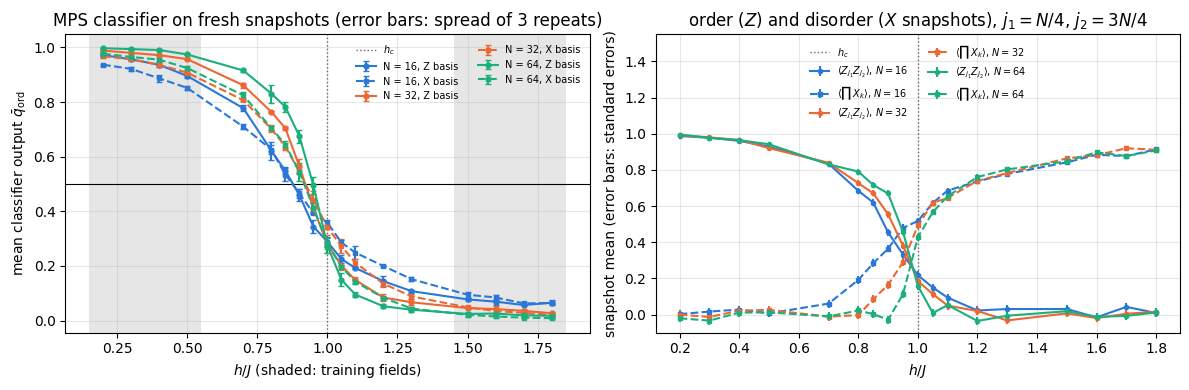

In [16]:
# ==============================================================================
# STEP 8: order parameter (Z snapshots) and disorder operator (X snapshots); which statistic each classifier follows
# ==============================================================================
def snapshot_statistics(N, h, M=2000, seed=0):
    """Means and standard errors of five statistics of Z and X snapshots (sites j1 = N/4, j2 = 3N/4).

    RETURNS (5, 2) array, rows:  <Z_j1 Z_j2>,  <prod_{j1<=k<j2} X_k>   (order and disorder operators)
                                 <m_z^2>, m_z = (1/N) sum_j (-1)^{s_j}  (Z snapshots: squared magnetisation)
                                 <Z_j Z_j+1> averaged over the bonds   (Z snapshots: local)
                                 <X_j> averaged over the sites         (X snapshots: local)
            and the magnetisation m_z of every Z snapshot (M,)
    """
    j1, j2 = N // 4, 3 * N // 4
    sz = 1 - 2 * snapshots(seed, GS[N][h]["B"], M, "z")
    sx = 1 - 2 * snapshots(seed + 1, GS[N][h]["B"], M, "x")
    stats = [sz[:, j1] * sz[:, j2], np.prod(sx[:, j1:j2], axis=1), sz.mean(axis=1) ** 2,
             (sz[:, :-1] * sz[:, 1:]).mean(axis=1), sx.mean(axis=1)]
    return np.array([mean_se(s) for s in stats]), sz.mean(axis=1)


OD, MZ = {}, {}
for N in SIZES:
    res = [snapshot_statistics(N, float(h), seed=3000 + 2 * i) for i, h in enumerate(FIELDS)]
    OD[N] = np.array([r[0].reshape(-1) for r in res])          # columns: mean, se of each statistic (10 columns)
    MZ[N] = np.array([r[1] for r in res])                      # (fields, 2000) magnetisations, for Section 5.3
for N in SIZES:
    i1 = list(FIELDS).index(1.0)
    print(f"N = {N:2d}, h = 1: <Z_N/4 Z_3N/4> = {OD[N][i1, 0]:.3f} +- {OD[N][i1, 1]:.3f},  "
          f"<prod X> = {OD[N][i1, 2]:.3f} +- {OD[N][i1, 3]:.3f}")
# check of the estimators against the MPS at N = 32, h = 0.8 (correlator) and h = 1.2 (string, by mps_overlap)
i08, i12 = list(FIELDS).index(0.8), list(FIELDS).index(1.2)
zz_mps = float(mps_correlator(GS[32][0.8]["B"], GS[32][0.8]["lam"], Z, 8, Z, 24))
Xstr = np.where(((np.arange(32) >= 8) & (np.arange(32) < 24))[:, None, None], np.array([[0.0, 1.0], [1.0, 0.0]])[None],
                np.eye(2)[None])
str_mps = float(np.real(complex(mps_overlap(GS[32][1.2]["B"], jnp.einsum("jst,jatb->jasb", jnp.asarray(Xstr, dtype=CDTYPE),
                                                                         GS[32][1.2]["B"])))))
print(f"N = 32: <Z_8 Z_24> at h = 0.8: snapshots {OD[32][i08, 0]:.4f} +- {OD[32][i08, 1]:.4f}, MPS {zz_mps:.4f};  "
      f"<X_8 ... X_23> at h = 1.2: snapshots {OD[32][i12, 2]:.4f} +- {OD[32][i12, 3]:.4f}, MPS {str_mps:.4f};  deviations "
      f"{abs(OD[32][i08, 0] - zz_mps) / OD[32][i08, 1]:.2f} and {abs(OD[32][i12, 2] - str_mps) / OD[32][i12, 3]:.2f} standard errors")
assert abs(OD[32][i08, 0] - zz_mps) < 4 * OD[32][i08, 1] and abs(OD[32][i12, 2] - str_mps) < 4 * OD[32][i12, 3]

# which statistic does the classifier follow?  Each statistic f(h) is mapped linearly onto [0, 1] between its means
# over the disordered and the ordered training fields; its crossing of 1/2 is compared with h* of the classifier
i_ord = [list(FIELDS).index(h) for h in TRAIN_ORD]
i_dis = [list(FIELDS).index(h) for h in TRAIN_DIS]
STAT_NAMES = ("<Z_j1 Z_j2>", "<prod X>", "<m_z^2>", "<Z_j Z_j+1>", "<X_j>")


def normalised_crossing(h, f, f_ord, f_dis):
    """Field where (f - f_dis) / (f_ord - f_dis) crosses 1/2 (linear interpolation on the grid h)."""
    r = (f - f_dis) / (f_ord - f_dis)
    return crossing(h, r if r[0] > r[-1] else 1 - r)


print("\ncrossing of 1/2 after normalising each statistic between the training windows (snapshots):")
SNAP_CR = {}
for N in SIZES:
    SNAP_CR[N] = cr = [normalised_crossing(FIELDS, OD[N][:, 2 * k], OD[N][i_ord, 2 * k].mean(), OD[N][i_dis, 2 * k].mean())
          for k in range(5)]
    print(f"   N = {N:2d}: " + ",  ".join(f"{n} {c:.3f}" for n, c in zip(STAT_NAMES, cr))
          + f"   | classifier: Z basis {CLS[N, 'z']['h_star'].mean():.3f}, X basis {CLS[N, 'x']['h_star'].mean():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.0))
for k, N in enumerate(SIZES):
    for basis, ls, mk in (("z", "-", "o"), ("x", "--", "s")):
        c = CLS[N, basis]["curves"]
        axes[0].errorbar(FIELDS, c.mean(0), yerr=c.std(0, ddof=1), fmt=mk + ls, ms=3.5, capsize=2, color=PALETTE[k],
                         label=f"N = {N}, {basis.upper()} basis")
for h in TRAIN_ORD + TRAIN_DIS:
    axes[0].axvspan(h - 0.05, h + 0.05, color="0.9", lw=0)
axes[0].axhline(0.5, color="k", lw=0.8)
axes[0].axvline(1.0, color="0.4", ls=":", lw=1, label=r"$h_c$")
axes[0].set_xlabel("$h/J$ (shaded: training fields)")
axes[0].set_ylabel(r"mean classifier output $\bar q_{\rm ord}$")
axes[0].set_title("MPS classifier on fresh snapshots (error bars: spread of 3 repeats)")
axes[0].legend(fontsize=7, ncol=2)
for k, N in enumerate(SIZES):
    axes[1].errorbar(FIELDS, OD[N][:, 0], yerr=OD[N][:, 1], fmt="o-", ms=3, color=PALETTE[k],
                     label=rf"$\langle Z_{{j_1}}Z_{{j_2}}\rangle$, $N={N}$")
    axes[1].errorbar(FIELDS, OD[N][:, 2], yerr=OD[N][:, 3], fmt="s--", ms=3, color=PALETTE[k],
                     label=rf"$\langle\prod\,X_k\rangle$, $N={N}$")
axes[1].axvline(1.0, color="0.4", ls=":", lw=1, label=r"$h_c$")
axes[1].set_xlabel("$h/J$")
axes[1].set_ylabel("snapshot mean (error bars: standard errors)")
axes[1].set_title(r"order ($Z$) and disorder ($X$ snapshots), $j_1=N/4$, $j_2=3N/4$")
axes[1].set_ylim(-0.1, 1.55)
axes[1].legend(fontsize=7, ncol=2, loc="upper center")
fig.tight_layout()
plt.show()

**Interpretation.** Both estimators agree with the MPS values within $2.50$ standard errors; the correlator at $h=0.8$ lies
at that bound, inside the 4-standard-error tolerance of the assert. At $h=1$ the order
correlator falls with $N$ ($0.218$, $0.186$, $0.159$), as it must at a critical point, where correlations decay as a
power of the distance, and the disorder string falls too ($0.518$, $0.493$, $0.428$). In the right panel the two curves
are related approximately by $h\leftrightarrow J^2/h$, the duality of Eq. (13) seen in snapshots, and both steepen with $N$.

The comparison of crossings shows which statistic each classifier tracks. The $Z$-basis classifier crosses where the order
parameter does: $0.878$, $0.921$, $0.948$ against $0.889$, $0.921$, $0.943$ for $\langle Z_{j_1}Z_{j_2}\rangle$ and
$0.881$, $0.915$, $0.938$ for $\langle m_z^2\rangle$, and far from the local correlator $\langle Z_jZ_{j+1}\rangle$
($0.931$, $0.960$, $0.979$). The $X$-basis classifier follows no single statistic: it lies between the local transverse
magnetisation ($0.838$, $0.884$, $0.904$) and the disorder string ($0.936$, $0.990$, $1.004$), and from $N=32$ to $64$ it
moves down while both of them move up. The string is the parity of $N/2$ bits, a product of single-site factors that
the MPS represents with bond dimension 1, so the model could express it; deep in the two phases the density of zeros
separates the training windows just as well, and the training has no reason to prefer the string.

Every one of these crossings moves with $N$, the local ones included. The local statistics are averages over all sites
or bonds of the open chain, and the sites near the ends contribute a correction of order $1/N$ to the average, which
moves the crossing. Whether a crossing moves *towards $h_c$* is a separate question, answered exactly in Section 5.3.

### 5.3 Fixed-level crossings and scale-invariant crossings

A classifier crossing $\bar q_{\rm ord}=\frac12$, and each normalised statistic crossing $\frac12$, are crossings at a
*fixed level*, set by the training windows. For the order parameter the limit of such a crossing can be computed. In
the infinite chain $\langle Z_0Z_r\rangle\to m^2$ for $r\to\infty$, with $m^2=(1-h^2)^{1/4}$ below $h_c$ [[6]](#ref-6);
the level set by the windows is crossed where $m^2(h)$ equals it, a field below $h_c$. By the duality of Eq. (13) the
string tends to $(1-h^{-2})^{1/4}$ above $h_c$, and its fixed-level crossing lies above $h_c$. Near the critical point
the order correlator has the finite-size scaling form [[12]](#ref-12)

$$\langle Z_{j_1}Z_{j_2}\rangle\approx N^{-2\beta/\nu}f\big((h-h_c)N^{1/\nu}\big),\qquad\frac{2\beta}\nu=\frac14,\quad\nu=1, \tag{14}$$

with a scaling function $f$. At $h_c$ the correlator vanishes as $N^{-1/4}$, so for large $N$ a fixed level is reached at
a field that tends to the field $h<h_c$ where $m^2(h)$ equals the level. A *scale-invariant* combination removes the prefactor: the
curves of $N^{1/4}\langle Z_{j_1}Z_{j_2}\rangle$ for $N$ and $2N$ are both $f(x)$ with $x=(h-h_c)N$, and they cross where
$f(x)=f(2x)$, that is at $x=0$ up to corrections to scaling. The Binder cumulant
$U=1-\langle m_z^4\rangle/(3\langle m_z^2\rangle^2)$, computed from the same $Z$ snapshots, is dimensionless and
crosses for two sizes near $h_c$ for the same reason. Even two unscaled curves cross near $h_c$: equating
$N^{-1/4}f(x)$ and $(2N)^{-1/4}f(2x)$ fixes $x$ at a value independent of $N$, so the crossing approaches $h_c$ as $1/N$.
The classifier output $\bar q_{\rm ord}$ is a mean over snapshots of a function of each snapshot, not a function of
$\langle Z_{j_1}Z_{j_2}\rangle$; the same argument applies to it only under the assumption that this mean obeys a scaling
form like Eq. (14), with its own prefactor.

The free-fermion solution of the chain [[6]](#ref-6), written here for the open chain with Majorana operators, gives
all four statistics without sampling. The Jordan–Wigner mapping of the spins to fermions writes each spin through two Majorana
operators, $\gamma_{2j}=\big(\prod_{k<j}X_k\big)Z_j$ and
$\gamma_{2j+1}=\big(\prod_{k<j}X_k\big)Y_j$, with $\gamma_m^2=1$ and $\gamma_m\gamma_n=-\gamma_n\gamma_m$ for $m\neq n$.
Then $X_j=i\gamma_{2j}\gamma_{2j+1}$ and $Z_jZ_{j+1}=i\gamma_{2j+1}\gamma_{2j+2}$, and the Hamiltonian is quadratic,

$$H=\frac i4\sum_{m,n=0}^{2N-1}A_{mn}\gamma_m\gamma_n,\qquad A_{2j,2j+1}=-2h,\quad A_{2j+1,2j+2}=-2J,\quad A=-A^{\rm T},
\qquad G_{mn}=\langle i\gamma_m\gamma_n\rangle=i\,\mathrm{sgn}(iA)_{mn}\ (m\neq n), \tag{15}$$

where $\mathrm{sgn}(iA)$ is the Hermitian matrix $iA$ with every eigenvalue replaced by its sign, and $E_0=\frac14\sum_{mn}A_{mn}G_{mn}$.
The form of $G$ follows in three steps. The ground state of a quadratic Hamiltonian is a fermionic Gaussian state,
fixed by its matrix $G$, which is real and antisymmetric; for a pure Gaussian state $G^2=-\mathbb 1$ (quoted here without
proof). Then $S=-iG$ is Hermitian with $S^2=\mathbb 1$, so its eigenvalues are $\pm1$. The energy is
$E=\frac14\sum_{mn}A_{mn}G_{mn}=-\frac14\mathrm{tr}\big[(iA)S\big]$, and over Hermitian $S$ with eigenvalues $\pm1$ the trace
is largest for $S=\mathrm{sgn}(iA)$, which gives every eigenvector of $iA$ the sign of its eigenvalue, that is, fills every
negative mode. Hence $G=i\,\mathrm{sgn}(iA)$ and $E_0=-\frac14\sum_k\vert\varepsilon_k\vert$, with $\varepsilon_k$ the
eigenvalues of $iA$.
The local statistics are single entries, $\langle X_j\rangle=G_{2j,2j+1}$ and $\langle Z_jZ_{j+1}\rangle=G_{2j+1,2j+2}$. The
two long operators are products of $L=N/2$ such pairs. By Wick's theorem, in a fermionic Gaussian state the expectation value of a product
of Majorana operators is the Pfaffian of the matrix of their two-point correlations; because $A$ couples only even to odd Majoranas, the even–even and odd–odd correlations vanish and the
Pfaffians become determinants,

$$\langle Z_{j_1}Z_{j_2}\rangle=\big\vert\det\big[G_{2k+1,\,2l+2}\big]_{k,l=j_1}^{j_2-1}\big\vert,\qquad
\Big\langle\prod_{k=j_1}^{j_2-1}X_k\Big\rangle=\big\vert\det\big[G_{2k,\,2l+1}\big]_{k,l=j_1}^{j_2-1}\big\vert, \tag{16}$$

at a cost of $O(N^3)$ for any $N$ (the absolute value fixes the sign convention; both are positive in the ground
state). For the infinite chain, the derivatives of the exact energy per site
$e=-\frac1\pi\int_0^\pi\sqrt{J^2+h^2+2hJ\cos q}\,{\rm d}q$ with respect to $h$ and $J$ give the two local expectation
values by the Hellmann–Feynman theorem: the derivative of the ground-state energy with respect to a parameter of $H$ equals the expectation value
of the derivative of $H$ ($\partial e/\partial h=-\langle X_j\rangle$, $\partial e/\partial J=-\langle Z_jZ_{j+1}\rangle$):

$$\langle X_j\rangle_\infty=\frac1\pi\int_0^\pi\frac{h+J\cos q}{\sqrt{J^2+h^2+2hJ\cos q}}\,{\rm d}q,\qquad
\langle Z_jZ_{j+1}\rangle_\infty=\frac1\pi\int_0^\pi\frac{J+h\cos q}{\sqrt{J^2+h^2+2hJ\cos q}}\,{\rm d}q. \tag{17}$$

The cell checks Eqs. (15)–(16) against the energies and the DMRG states at $N=16$, $32$ and $64$, tabulates the exact
fixed-level crossings of the four statistics for $N=16$ to $256$ and their limits from $m^2$, the dual string and
Eq. (17), and then compares three scale-invariant crossings with $h_c$: the exact $N^{1/4}\langle Z_{j_1}Z_{j_2}\rangle$
for $N$ and $2N$, the Binder cumulants of the $Z$ snapshots (standard error from 200 bootstrap resamples of the
snapshots), and the $Z$-basis classifier curves of Section 5.1. It also prints how far the fixed-level crossings of the
$Z$-basis classifier lie from the exact order-parameter crossings at the same $N$. The exact crossings use a grid of
step $0.01$;
the cell also prints how far the coarser grid of Section 5.1 shifts them for $N\leq64$, and the exact crossings of the
unscaled $\langle Z_{j_1}Z_{j_2}\rangle$ for $N$ and $2N$.

N = 16, h = 0.8: E_0 from G -18.0498764348, bidiagonal -18.0498764348;  statistics exact 0.686169, 0.176511, 0.762566, 0.516515;  largest |exact - DMRG| 5.5e-10
N = 32, h = 0.8: E_0 from G -36.7254488047, bidiagonal -36.7254488047;  statistics exact 0.765371, 0.027273, 0.791487, 0.476147;  largest |exact - DMRG| 1.7e-07


N = 64, h = 0.8: E_0 from G -74.0950686695, bidiagonal -74.0950686695;  statistics exact 0.774436, 0.000714, 0.802309, 0.459953;  largest |exact - DMRG| 1.5e-06



exact crossings of the normalised statistics (training windows as in Section 5.1):
      N   <Z_j1 Z_j2>   <prod X>   <Z_j Z_j+1>   <X_j>
     16      0.8886      0.9380      0.9356      0.8383
     32      0.9247      0.9913      0.9644      0.8794
     64      0.9492      1.0120      0.9799      0.8997
    128      0.9639      1.0186      0.9880      0.9090
    256      0.9711      1.0200      0.9924      0.9136
    inf      0.9727      1.0202      0.9970      0.9185
   check of the infinite chain: <X> at h = 1 is 0.636620 (2/pi = 0.636620)
   largest shift of these crossings for N <= 64 when interpolated on the grid of Section 5.1: 0.0032;  largest difference between the snapshot crossings of Section 5.2 and the exact ones on that grid: 0.0117



crossing of N^(1/4) <Z_j1 Z_j2> for N and 2N (exact): (16, 32): 0.99896, (32, 64): 0.99969, (64, 128): 0.99992, (128, 256): 0.99998


crossing of the unscaled <Z_j1 Z_j2> for N and 2N (exact):  (16, 32): 0.9734, (32, 64): 0.9869, (64, 128): 0.9935, (128, 256): 0.9968


pair (16, 32):  Binder cumulants of the Z snapshots cross at 0.996 +- 0.008 (bootstrap);  Z-basis classifier curves cross at 1.002 +- 0.017


pair (32, 64):  Binder cumulants of the Z snapshots cross at 1.005 +- 0.008 (bootstrap);  Z-basis classifier curves cross at 1.001 +- 0.008

Z-basis classifier: h*(N) = 0.878 +- 0.006, 0.921 +- 0.004, 0.948 +- 0.004;  exact <Z_j1 Z_j2> crossings 0.8886, 0.9247, 0.9492;  largest difference 0.011;  exact limit 0.9727


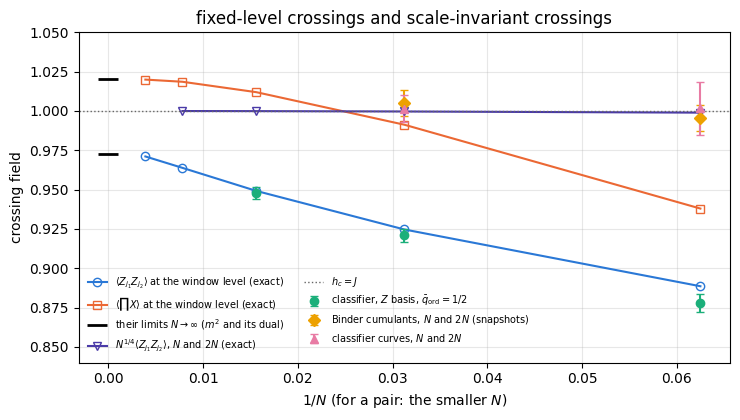

In [17]:
# ==============================================================================
# STEP 9: exact free-fermion statistics, their N -> infinity limits, and scale-invariant crossings
# ==============================================================================
from scipy.integrate import quad
from scipy.optimize import brentq


def majorana_correlations(N, h, J=1.0):
    """Ground-state Majorana correlation matrix G[m, n] = <i gamma_m gamma_n> (m != n) of the open chain, Eq. (15).

    MATH            H = (i/4) sum_{mn} A_mn gamma_m gamma_n,  A[2j, 2j+1] = -2h,  A[2j+1, 2j+2] = -2J,  A = -A^T;
                    ground state: G = i sgn(iA) (off-diagonal part), energy E_0 = (1/4) sum_{mn} A_mn G_mn
    COST            one Hermitian eigendecomposition of size 2N: O(N^3)
    RETURNS         G (2N, 2N), E_0
    """
    A = np.zeros((2 * N, 2 * N))
    A[2 * np.arange(N), 2 * np.arange(N) + 1] = -2 * h
    A[2 * np.arange(N - 1) + 1, 2 * np.arange(N - 1) + 2] = -2 * J
    A = A - A.T
    w, V = np.linalg.eigh(1j * A)
    G = np.real(1j * (V * np.sign(w)) @ V.conj().T)
    return G, 0.25 * np.sum(A * G)


def exact_statistics(N, h):
    """The statistics of Section 5.2 (without m_z^2) from G, Eqs. (15)-(16):  <Z_j1 Z_j2>, string, <Z_j Z_j+1>, <X_j>."""
    G, _ = majorana_correlations(N, h)
    k = np.arange(N // 4, 3 * N // 4)
    return np.array([abs(np.linalg.det(G[np.ix_(2 * k + 1, 2 * k + 2)])), abs(np.linalg.det(G[np.ix_(2 * k, 2 * k + 1)])),
                     np.mean(np.abs(G[2 * np.arange(N - 1) + 1, 2 * np.arange(N - 1) + 2])),
                     np.mean(np.abs(G[2 * np.arange(N), 2 * np.arange(N) + 1]))])


# CHECKPOINT: energy against the bidiagonal formula, the four statistics against the DMRG states (N = 16, 32, 64, h = 0.8)
dev = []
for N in SIZES:
    gs = GS[N][0.8]
    lam = gs["lam"]
    zz_far = float(mps_correlator(gs["B"], lam, Z, N // 4, Z, 3 * N // 4))
    Xs = np.where(((np.arange(N) >= N // 4) & (np.arange(N) < 3 * N // 4))[:, None, None],
                  np.array([[0.0, 1.0], [1.0, 0.0]])[None], np.eye(2)[None])
    strg = float(np.real(complex(mps_overlap(gs["B"], jnp.einsum("jst,jatb->jasb", jnp.asarray(Xs, dtype=CDTYPE), gs["B"])))))
    zz_nn = np.mean([float(mps_correlator(gs["B"], lam, Z, j, Z, j + 1)) for j in range(N - 1)])
    x_avg = float(np.mean(np.asarray(mps_expect_sites(gs["B"], lam, X))))
    ex = exact_statistics(N, 0.8)
    dev.append(np.max(np.abs(ex - np.array([zz_far, strg, zz_nn, x_avg]))))
    print(f"N = {N:2d}, h = 0.8: E_0 from G {majorana_correlations(N, 0.8)[1]:.10f}, bidiagonal {tfim_exact_energy(N, 0.8):.10f};"
          f"  statistics exact " + ", ".join(f"{x:.6f}" for x in ex) + f";  largest |exact - DMRG| {dev[-1]:.1e}")
assert max(dev) < 1e-5

# crossings of the normalised exact statistics on a fine grid, and their N -> infinity limits
FINE = np.round(np.arange(0.80, 1.1001, 0.01), 4)
EXACT_CR, GRID_SHIFT, SNAP_DIFF = {}, 0.0, 0.0
for N in (16, 32, 64, 128, 256):
    s_ord = np.mean([exact_statistics(N, h) for h in TRAIN_ORD], axis=0)
    s_dis = np.mean([exact_statistics(N, h) for h in TRAIN_DIS], axis=0)
    s = np.array([exact_statistics(N, h) for h in FINE])
    EXACT_CR[N] = [normalised_crossing(FINE, s[:, k], s_ord[k], s_dis[k]) for k in range(4)]
    if N <= 64:                                             # the same crossings interpolated on the grid FIELDS
        s_g = np.array([exact_statistics(N, h) for h in FIELDS])
        cr_g = [normalised_crossing(FIELDS, s_g[:, k], s_ord[k], s_dis[k]) for k in range(4)]
        GRID_SHIFT = max(GRID_SHIFT, max(abs(cr_g[k] - EXACT_CR[N][k]) for k in range(4)))
        SNAP_DIFF = max(SNAP_DIFF, max(abs(SNAP_CR[N][i] - cr_g[k]) for k, i in enumerate((0, 1, 3, 4))))
m2_inf = lambda h: (1 - h ** 2) ** 0.25 if h < 1 else 0.0            # <Z_0 Z_r>, r -> infinity: m^2 of ref. [6]
mu2_inf = lambda h: (1 - h ** -2) ** 0.25 if h > 1 else 0.0          # string: image of m^2 under the Kramers-Wannier duality, Eq. (13)
x_inf = lambda h: quad(lambda q: (h + np.cos(q)) / np.sqrt(1 + h * h + 2 * h * np.cos(q)), 0, np.pi)[0] / np.pi
zz_inf = lambda h: quad(lambda q: (1 + h * np.cos(q)) / np.sqrt(1 + h * h + 2 * h * np.cos(q)), 0, np.pi)[0] / np.pi
lim = []
for f in (m2_inf, mu2_inf, zz_inf, x_inf):
    f_o, f_d = np.mean([f(h) for h in TRAIN_ORD]), np.mean([f(h) for h in TRAIN_DIS])
    lim.append(brentq(lambda h: (f(h) - f_d) / (f_o - f_d) - 0.5, 0.6, 1.4))
EXACT_CR["inf"] = lim
print("\nexact crossings of the normalised statistics (training windows as in Section 5.1):")
print("      N   <Z_j1 Z_j2>   <prod X>   <Z_j Z_j+1>   <X_j>")
for N, cr in EXACT_CR.items():
    print(f"   {str(N):>4s}   " + "   ".join(f"{c:9.4f}" for c in cr))
print(f"   check of the infinite chain: <X> at h = 1 is {x_inf(1.0):.6f} (2/pi = {2 / np.pi:.6f})")
print(f"   largest shift of these crossings for N <= 64 when interpolated on the grid of Section 5.1: {GRID_SHIFT:.4f};  "
      f"largest difference between the snapshot crossings of Section 5.2 and the exact ones on that grid: {SNAP_DIFF:.4f}")

# scale-invariant crossings: N^(1/4) <Z_j1 Z_j2> (exact) and the Binder cumulant (snapshots), for the pairs (N, 2N)
scaled = lambda N, h: N ** 0.25 * exact_statistics(N, h)[0]
SC_CR = {N: brentq(lambda h: scaled(N, h) - scaled(2 * N, h), 0.85, 1.15) for N in (16, 32, 64, 128)}
print("\ncrossing of N^(1/4) <Z_j1 Z_j2> for N and 2N (exact): "
      + ", ".join(f"({N}, {2 * N}): {c:.5f}" for N, c in SC_CR.items()))
UN_CR = {N: brentq(lambda h: exact_statistics(N, h)[0] - exact_statistics(2 * N, h)[0], 0.85, 1.15) for N in (16, 32, 64, 128)}
print("crossing of the unscaled <Z_j1 Z_j2> for N and 2N (exact):  "
      + ", ".join(f"({N}, {2 * N}): {c:.4f}" for N, c in UN_CR.items()))


def binder(mz):
    """U = 1 - <m^4> / (3 <m^2>^2) for every field (rows of mz)."""
    return 1 - np.mean(mz ** 4, axis=1) / (3 * np.mean(mz ** 2, axis=1) ** 2)


def pair_crossing(h, f_small, f_large):
    """Field where f_small - f_large changes sign from negative to positive (linear interpolation)."""
    d = f_small - f_large
    k = int(np.argmax((d[:-1] < 0) & (d[1:] >= 0))) + 1
    return h[k - 1] - d[k - 1] * (h[k] - h[k - 1]) / (d[k] - d[k - 1])


rng_b = np.random.default_rng(7)
BINDER_CR, CLS_PAIR = {}, {}
for N in SIZES[:-1]:
    est = pair_crossing(FIELDS, binder(MZ[N]), binder(MZ[2 * N]))
    boot = [pair_crossing(FIELDS, binder(np.take_along_axis(MZ[N], rng_b.integers(0, 2000, MZ[N].shape), 1)),
                          binder(np.take_along_axis(MZ[2 * N], rng_b.integers(0, 2000, MZ[2 * N].shape), 1)))
            for _ in range(200)]
    BINDER_CR[N] = (est, np.std(boot, ddof=1))
    pc = [pair_crossing(FIELDS, CLS[N, "z"]["curves"][k], CLS[2 * N, "z"]["curves"][k]) for k in range(REPEATS)]
    CLS_PAIR[N] = (np.mean(pc), np.std(pc, ddof=1) / np.sqrt(REPEATS))
    print(f"pair ({N}, {2 * N}):  Binder cumulants of the Z snapshots cross at {est:.3f} +- {BINDER_CR[N][1]:.3f} "
          f"(bootstrap);  Z-basis classifier curves cross at {CLS_PAIR[N][0]:.3f} +- {CLS_PAIR[N][1]:.3f}")

# fixed-level crossings of the Z classifier against the exact order-parameter crossings at the same N
hstar = np.array([CLS[N, "z"]["h_star"].mean() for N in SIZES])
err = np.array([CLS[N, "z"]["h_star"].std(ddof=1) / np.sqrt(REPEATS) for N in SIZES])
print(f"\nZ-basis classifier: h*(N) = " + ", ".join(f"{x:.3f} +- {e:.3f}" for x, e in zip(hstar, err))
      + ";  exact <Z_j1 Z_j2> crossings " + ", ".join(f"{EXACT_CR[N][0]:.4f}" for N in SIZES)
      + f";  largest difference {np.max(np.abs(hstar - np.array([EXACT_CR[N][0] for N in SIZES]))):.3f};  exact limit "
      f"{EXACT_CR['inf'][0]:.4f}")

fig, ax = plt.subplots(figsize=(7.5, 4.3))
Ns = np.array([16, 32, 64, 128, 256])
ax.plot(1 / Ns, [EXACT_CR[N][0] for N in Ns], "o-", color=PALETTE[0], mfc="none",
        label=r"$\langle Z_{j_1}Z_{j_2}\rangle$ at the window level (exact)")
ax.plot(1 / Ns, [EXACT_CR[N][1] for N in Ns], "s-", color=PALETTE[1], mfc="none",
        label=r"$\langle\prod X\rangle$ at the window level (exact)")
ax.plot([0, 0], [EXACT_CR["inf"][0], EXACT_CR["inf"][1]], "_", color="k", ms=14, mew=2,
        label=r"their limits $N\to\infty$ ($m^2$ and its dual)")
ax.errorbar(1 / np.array(SIZES), hstar, yerr=err, fmt="o", color=PALETTE[2], capsize=3,
            label=r"classifier, $Z$ basis, $\bar q_{\rm ord}=1/2$")
ax.errorbar(1 / np.array(SIZES[:-1]), [BINDER_CR[N][0] for N in SIZES[:-1]], yerr=[BINDER_CR[N][1] for N in SIZES[:-1]],
            fmt="D", color=PALETTE[3], capsize=3, label=r"Binder cumulants, $N$ and $2N$ (snapshots)")
ax.errorbar(1 / np.array(SIZES[:-1]), [CLS_PAIR[N][0] for N in SIZES[:-1]], yerr=[CLS_PAIR[N][1] for N in SIZES[:-1]],
            fmt="^", color=PALETTE[4], capsize=3, label=r"classifier curves, $N$ and $2N$")
ax.plot(1 / np.array(list(SC_CR)), list(SC_CR.values()), "v-", color=PALETTE[5], mfc="none",
        label=r"$N^{1/4}\langle Z_{j_1}Z_{j_2}\rangle$, $N$ and $2N$ (exact)")
ax.axhline(1.0, color="0.4", ls=":", lw=1, label=r"$h_c=J$")
ax.set_xlabel(r"$1/N$ (for a pair: the smaller $N$)")
ax.set_ylabel("crossing field")
ax.set_title("fixed-level crossings and scale-invariant crossings")
ax.legend(fontsize=7, loc="lower left", ncol=2)
ax.set_ylim(0.84, 1.05)
fig.tight_layout()
plt.show()

**Interpretation.** Eqs. (15)–(16) reproduce the exact energies and the DMRG statistics, to at most $1.5\times10^{-6}$,
the accuracy of the $N=64$ DMRG state near the transition.

The table gives the reference values for the crossings of Section 5.2. The fixed-level crossing of the order parameter
moves from $0.8886$ ($N=16$) to $0.9711$ ($N=256$) and converges to $0.9727$, the field where $m^2(h)$ reaches the level
set by the training windows, below $h_c$. The string crossing passes $h_c$ between $N=32$ and $N=64$ and
converges to $1.0202$ from below. The local statistics converge to their own window-defined fields, $0.9970$ and
$0.9185$; that the first is close to 1 is a coincidence of the chosen windows. The snapshot crossings of Section 5.2
differ from the exact crossings on the same grid by at most $0.012$, and that grid shifts the exact crossings by at
most $0.0032$ for $N\leq64$. The fixed-level crossings of the $Z$-basis classifier lie within $0.011$ of the exact
order-parameter crossings at the same $N$, at $N=16$, $32$ and $64$, and the exact sequence converges to $0.9727$. The
classifier crossing therefore tracks a sequence whose limit lies below $h_c$; the classifier itself was not run at
larger $N$.

The scale-invariant crossings go to the critical point. The exact $N^{1/4}\langle Z_{j_1}Z_{j_2}\rangle$ curves for
$N$ and $2N$ cross at $0.99896$, $0.99969$, $0.99992$ and $0.99998$ for $N=16$ to $128$, approaching $h_c$ roughly as $1/N^2$. The unscaled curves of two sizes
cross at $0.9734$, $0.9869$, $0.9935$ and $0.9968$, approaching $h_c$ as $1/N$, as the scaling argument predicts. From the snapshots, the Binder cumulants
cross at $0.996\pm0.008$ for $(16,32)$ and $1.005\pm0.008$ for $(32,64)$, and the $Z$-basis classifier curves of two sizes cross at $1.002\pm0.017$
and $1.001\pm0.008$. These values lie within one standard error of $h_c$ and within two of the exact two-size crossings
of the unscaled order correlator. With three repeats per size the errors are rough, and the two classifier pairs cannot
distinguish a direct approach to $h_c$, like that of the Binder cumulants, from the $1/N$ approach of the unscaled
correlator.

### 5.4 Exact state-vector check of Part B at $N=16$

The exact vectors of Section 3.5 repeat Part B at $N=16$ without DMRG. The cell compares, at all 18 fields: the four
statistics of Eqs. (15)–(16) from the exact vectors, from the contracted DMRG states and from the free-fermion
solution; their fixed-level crossings on the grid of Section 5.1; the five snapshot statistics of Section 5.2 from
$2000$ snapshots per field and basis drawn from the exact vectors, against those from the DMRG snapshots (difference
in units of the combined standard error); and the crossings of the three trained $N=16$ classifiers of each basis on
$500$ snapshots per field from the exact vectors, against their crossings on DMRG snapshots. A two-size crossing needs
$N=32$, beyond the exact vector, so the cell forms the pair $(8,16)$ instead: $N^{1/4}\langle Z_{j_1}Z_{j_2}\rangle$ and
the Binder cumulant computed exactly from the full distributions (an $N=8$ ground state by dense diagonalisation),
against the free-fermion crossing of the same pair.

In [18]:
# ==============================================================================
# STEP 9b: Part B at N = 16 from exact state vectors
# ==============================================================================
def ed_statistics(v):
    """<Z_j1 Z_j2>, string, <Z_j Z_j+1> (bond average), <X_j> (site average) of a flat vector at N = 16, as in Eq. (16)."""
    zz, x, st, _ = dense_observables(v)
    return np.array([zz[N_X // 4, 3 * N_X // 4], st, np.mean(np.diag(zz, 1)), x.mean()])


S_ED = np.array([ed_statistics(ED[float(h)]["v"]) for h in FIELDS])
S_MP = np.array([ed_statistics(ED[float(h)]["v_mps"]) for h in FIELDS])
S_FF = np.array([exact_statistics(N_X, float(h)) for h in FIELDS])
print(f"N = 16, four statistics at 18 fields: largest |exact vector - free fermions| {np.abs(S_ED - S_FF).max():.1e},  "
      f"largest |DMRG - exact vector| {np.abs(S_MP - S_ED).max():.1e}")
cr_ed = [normalised_crossing(FIELDS, S_ED[:, k], S_ED[i_ord, k].mean(), S_ED[i_dis, k].mean()) for k in range(4)]
cr_ff = [normalised_crossing(FIELDS, S_FF[:, k], S_FF[i_ord, k].mean(), S_FF[i_dis, k].mean()) for k in range(4)]
cr_mp = [normalised_crossing(FIELDS, S_MP[:, k], S_MP[i_ord, k].mean(), S_MP[i_dis, k].mean()) for k in range(4)]
print("fixed-level crossings on the grid (exact vector | DMRG states | free fermions): "
      + ",  ".join(f"{n} {a:.4f} | {c:.4f} | {b:.4f}" for n, a, b, c in zip(("<Z_j1 Z_j2>", "<prod X>", "<Z_j Z_j+1>", "<X_j>"),
                                                                          cr_ed, cr_ff, cr_mp)))


def stats_from(sz, sx):
    """The five snapshot statistics of Section 5.2 (mean, standard error) from spins sz, sx = (-1)^s of Z and X snapshots."""
    j1, j2 = sz.shape[1] // 4, 3 * sz.shape[1] // 4
    st = [sz[:, j1] * sz[:, j2], np.prod(sx[:, j1:j2], axis=1), sz.mean(axis=1) ** 2,
          (sz[:, :-1] * sz[:, 1:]).mean(axis=1), sx.mean(axis=1)]
    return np.array([mean_se(x) for x in st])


OD_ED = np.array([stats_from(1 - 2 * ed_snapshots(5000 + 2 * i, ED[float(h)]["v"], 2000),
                             1 - 2 * ed_snapshots(5001 + 2 * i, ED[float(h)]["vx"], 2000)).reshape(-1)
                  for i, h in enumerate(FIELDS)])
z_snap = np.array([(OD_ED[:, 2 * k] - OD[N_X][:, 2 * k]) / np.hypot(OD_ED[:, 2 * k + 1], OD[N_X][:, 2 * k + 1])
                   for k in range(5)])
z_snap = z_snap[np.isfinite(z_snap)]
cr_snap_ed = [normalised_crossing(FIELDS, OD_ED[:, 2 * k], OD_ED[i_ord, 2 * k].mean(), OD_ED[i_dis, 2 * k].mean())
              for k in range(5)]
print(f"snapshot statistics, exact-vector snapshots against DMRG snapshots: {z_snap.size} comparisons, largest |z| "
      f"{np.abs(z_snap).max():.2f}, fraction with |z| > 2: {np.mean(np.abs(z_snap) > 2):.3f}")
print("crossings of the snapshot statistics (exact-vector snapshots | DMRG snapshots): "
      + ",  ".join(f"{n} {a:.3f} | {b:.3f}" for n, a, b in zip(STAT_NAMES, cr_snap_ed, SNAP_CR[N_X])))

# the classifiers trained on DMRG snapshots at N = 16, applied to snapshots of the exact vectors
for basis, key in (("z", "v"), ("x", "vx")):
    hx_ed = np.array([crossing(FIELDS, np.array([q_ordered(As_c, C_c, ed_snapshots(6000 + 100 * k + i, ED[float(h)][key],
                                                                                      N_TEST)).mean()
                                                 for i, h in enumerate(FIELDS)]))
                      for k, (As_c, C_c) in enumerate(CLS[N_X, basis]["models"])])
    hx_mp = CLS[N_X, basis]["h_star"]
    hx_mp2 = np.array([crossing(FIELDS, np.array([q_ordered(As_c, C_c, snapshots(7000 + 100 * k + i, GS[N_X][float(h)]["B"],
                                                                                   N_TEST, basis)).mean()
                                                  for i, h in enumerate(FIELDS)]))
                       for k, (As_c, C_c) in enumerate(CLS[N_X, basis]["models"])])
    print(f"classifiers, {basis} basis, N = 16, crossings per classifier (exact-vector snapshots | DMRG snapshots | second "
          f"set of DMRG snapshots): " + ", ".join(f"{a:.3f} | {b:.3f} | {c:.3f}" for a, b, c in zip(hx_ed, hx_mp, hx_mp2))
          + f";  means {hx_ed.mean():.3f} | {hx_mp.mean():.3f} | {hx_mp2.mean():.3f};  rms difference between the two DMRG "
          f"test sets {np.sqrt(np.mean((hx_mp - hx_mp2) ** 2)):.3f}, between exact-vector and DMRG test sets "
          f"{np.sqrt(np.mean((hx_ed - hx_mp) ** 2)):.3f}")

# the pair (8, 16): exact vectors (N = 8 by dense diagonalisation) against free fermions
bits8 = (np.arange(2 ** 8)[:, None] >> np.arange(7, -1, -1)) & 1
spin8 = 1 - 2 * bits8


def binder_exact(prob, spin):
    """U = 1 - <m^4> / (3 <m^2>^2), m = (1/N) sum_j (-1)^(s_j), from the full distribution prob of the Z basis."""
    m = spin.mean(axis=1)
    return 1 - (prob @ m ** 4) / (3 * (prob @ m ** 2) ** 2)


sc8, sc16, U8, U16 = [], [], [], []
for h in FIELDS:
    w8, V8 = np.linalg.eigh(tfim_sparse(8, float(h)).toarray())
    p8 = V8[:, 0] ** 2
    sc8.append(8 ** 0.25 * (p8 @ (spin8[:, 2] * spin8[:, 6])))
    U8.append(binder_exact(p8, spin8))
    p16 = ED[float(h)]["v"] ** 2
    sc16.append(16 ** 0.25 * (p16 @ (SPIN[:, 4] * SPIN[:, 12])))
    U16.append(binder_exact(p16, SPIN))
scff = lambda N, h: N ** 0.25 * exact_statistics(N, h)[0]
print(f"pair (8, 16): N^(1/4) <Z_j1 Z_j2> crosses at {pair_crossing(FIELDS, np.array(sc8), np.array(sc16)):.4f} "
      f"(exact vectors, grid), {pair_crossing(FIELDS, np.array([scff(8, float(h)) for h in FIELDS]), np.array([scff(16, float(h)) for h in FIELDS])):.4f} "
      f"(free fermions, grid), {brentq(lambda h: scff(8, h) - scff(16, h), 0.85, 1.15):.4f} (free fermions, root);  "
      f"exact Binder cumulants cross at {pair_crossing(FIELDS, np.array(U8), np.array(U16)):.4f} (grid)")

N = 16, four statistics at 18 fields: largest |exact vector - free fermions| 4.2e-15,  largest |DMRG - exact vector| 4.1e-07
fixed-level crossings on the grid (exact vector | DMRG states | free fermions): <Z_j1 Z_j2> 0.8884 | 0.8884 | 0.8884,  <prod X> 0.9385 | 0.9385 | 0.9385,  <Z_j Z_j+1> 0.9359 | 0.9359 | 0.9359,  <X_j> 0.8380 | 0.8380 | 0.8380
snapshot statistics, exact-vector snapshots against DMRG snapshots: 90 comparisons, largest |z| 2.70, fraction with |z| > 2: 0.033
crossings of the snapshot statistics (exact-vector snapshots | DMRG snapshots): <Z_j1 Z_j2> 0.896 | 0.889,  <prod X> 0.945 | 0.936,  <m_z^2> 0.881 | 0.881,  <Z_j Z_j+1> 0.931 | 0.931,  <X_j> 0.839 | 0.838


classifiers, z basis, N = 16, crossings per classifier (exact-vector snapshots | DMRG snapshots | second set of DMRG snapshots): 0.870 | 0.886 | 0.861, 0.868 | 0.867 | 0.875, 0.855 | 0.880 | 0.870;  means 0.864 | 0.878 | 0.869;  rms difference between the two DMRG test sets 0.016, between exact-vector and DMRG test sets 0.017


classifiers, x basis, N = 16, crossings per classifier (exact-vector snapshots | DMRG snapshots | second set of DMRG snapshots): 0.888 | 0.885 | 0.905, 0.882 | 0.874 | 0.881, 0.884 | 0.860 | 0.887;  means 0.885 | 0.873 | 0.891;  rms difference between the two DMRG test sets 0.020, between exact-vector and DMRG test sets 0.015


pair (8, 16): N^(1/4) <Z_j1 Z_j2> crosses at 0.9976 (exact vectors, grid), 0.9976 (free fermions, grid), 0.9972 (free fermions, root);  exact Binder cumulants cross at 0.9691 (grid)


**Interpretation.** At $N=16$ the exact vectors reproduce the free-fermion statistics to $4.2\times10^{-15}$, and the
DMRG states the exact vectors to $4.1\times10^{-7}$, so the fixed-level crossings of the four statistics on the grid,
$0.8884$, $0.9385$, $0.9359$ and $0.8380$, are the same to all printed digits in the three calculations. Snapshots
drawn from the exact vectors and from the DMRG states are statistically indistinguishable: of the 90 comparisons of
snapshot means, the largest differs by $2.70$ combined standard errors and a fraction of $0.033$ by more than two,
close to what independent normal deviations give. Their crossings differ by at most $0.009$, the sampling noise of
$2000$ snapshots per field.

The three $N=16$ classifiers of each basis, trained on DMRG snapshots, cross on snapshots of the exact vectors at
fields that differ from their crossings on DMRG snapshots by an rms of $0.017$ ($Z$ basis) and $0.015$ ($X$ basis),
the same size as the differences between two independent sets of DMRG test snapshots, $0.016$ and $0.020$: the
scatter is the noise of $500$ test snapshots per field. The mean crossings of the three test sets, $0.864$, $0.878$
and $0.869$ in the $Z$ basis and $0.885$, $0.873$ and $0.891$ in the $X$ basis, scatter by the same amount.

The pair $(8,16)$ of $N^{1/4}\langle Z_{j_1}Z_{j_2}\rangle$ crosses at $0.9976$ from the exact vectors and from the free
fermions on the same grid, and at $0.9972$ at the exact root. The exact Binder cumulants of the same pair cross at
$0.9691$, further from $h_c$ than the snapshot Binder crossing of the pair $(16,32)$ in Section 5.3: at $N=8$ the
corrections to scaling of the Binder cumulant are still large. The pair $(16,32)$ itself needs a state vector of
$N=32$, which Section 6 shows to be out of reach.

In [19]:
section_timer("6 cost")

## 6. Cost of the computation

| operation | cost | here |
|---|---|---|
| DMRG ground state, one field | $O(n_{\rm sweeps}\,N\,m\,\chi^3w)$, $m$ Lanczos steps per bond | $\chi=16$, MPO bond dimension $w=5$, $m=20$ |
| parity projection, Eq. (6) | $O(N\chi^3)$, bond dimension doubled | `parity_project` |
| one exact snapshot | $O(N\chi^2)$ | `sample_mps` |
| $\ln\vert\psi(\mathbf s)\vert$ of one string | $O(N\chi^2)$ | `log_amplitude`, `log_psi` |
| local estimator (10)–(11), one sample | $N+1$ amplitudes, $O(N^2\chi^2)$ | `local_observables` |
| one Born-machine loop | $O(N(M\chi^2+\chi^3))$ | `training_loop` |
| one classifier sweep, two labels | $O(N(n_{\rm steps}+n_{\rm power})M\chi^2+N\chi^3)$, $n_{\rm steps}=10$ gradient and $n_{\rm power}=20$ power-iteration steps per bond | `half_sweep_right/left` |
| exact statistics, Eqs. (15)–(16) | $O(N^3)$ per field | `exact_statistics` |
| exact ground state, Lanczos on the state vector | $O(n_{\rm restarts}\,m\,(N+m)\,2^N)$ time, $O(m\,2^N)$ memory with full reorthogonalisation | $N=16$, $m=60$, 3 restarts |
| full tomography, for comparison | $3^N$ settings, $4^N-1$ parameters | not run |

The scalings are the standard operation counts of the algorithms, not measurements; the measured wall-clock time of
every section is printed below. The training functions are compiled once per array shape, so
runs with the same number of snapshots share one compilation. The cell also prints the memory of one state vector and
the time per field of DMRG and of the exact state vector at $N=16$.

The exact state-vector checks of Sections 3.5, 4.8 and 5.4, all at $N=16$, in one table:

| quantity at $N=16$ | MPS side | exact state vector | agreement |
|---|---|---|---|
| ground-state energy, 18 fields | DMRG | Lanczos, even sector | at most $1.0\times10^{-9}$ |
| infidelity of the ground state | DMRG, contracted | Lanczos | at most $5.4\times10^{-10}$ |
| all $\langle Z_iZ_j\rangle$, all $\langle X_j\rangle$ | DMRG | Lanczos | $1.1\times10^{-6}$, $3.6\times10^{-6}$ |
| snapshot distributions, both bases | DMRG | Lanczos | total variation at most $1.9\times10^{-5}$ |
| gap, gap inside the even sector | free fermions | Lanczos | all printed digits, except the full-chain gap at $h=0.2$, equal to round-off |
| reconstruction fidelity, $h=1$ | $0.99164$, mean of 3 models (DMRG snapshots) | $0.99257$ (exact-vector snapshots) | 0.9 spreads |
| four statistics, fixed-level crossings | DMRG, free fermions | Lanczos | statistics to $4.1\times10^{-7}$, crossings identical |
| snapshot statistics, 90 means | DMRG snapshots | exact-vector snapshots | largest difference $2.70$ standard errors |
| classifier crossings | DMRG snapshots | exact-vector snapshots | rms difference $0.017$ and $0.015$, as between two DMRG test sets ($0.016$, $0.020$) |
| two-size crossing $(8,16)$ of $N^{1/4}\langle Z_{j_1}Z_{j_2}\rangle$ | free fermions $0.9976$ | $0.9976$ | identical on the grid |

In [20]:
# ==============================================================================
# STEP 10: wall-clock time per section
# ==============================================================================
section_timer("end")
print("wall-clock time per section:")
for k, v in SECTION_TIMES.items():
    if k != "end":
        print(f"   {k:24s} {v:6.1f} s")
print(f"   {'total (Sections 3-6)':24s} {sum(v for k, v in SECTION_TIMES.items() if k != 'end'):6.1f} s")

# memory of one state vector of double-precision complex amplitudes (16 bytes each), decimal units
for N, unit, scale in ((16, "MB", 1e6), (32, "GB", 1e9), (64, "EB", 1e18)):
    print(f"state vector of N = {N} spins: 2^{N} x 16 bytes = {2 ** N * 16:.3e} bytes = {2 ** N * 16 / scale:.3g} {unit}")
assert abs(2 ** 32 * 16 / 1e9 - 68.719476736) < 1e-9
B64 = np.asarray(GS[64][1.0]["B"])
print(f"stored MPS of N = 64 spins (array {B64.shape}, {B64.dtype}): {B64.nbytes / 1e6:.2f} MB")
print(f"N = 16, time per field: DMRG {T_DMRG[16] / len(FIELDS):.2f} s,  exact even ground state {T_ED['even'] / len(FIELDS):.2f} s;"
      f"  DMRG for N = 32 and 64: {T_DMRG[32] / len(FIELDS):.2f} s and {T_DMRG[64] / len(FIELDS):.2f} s per field")

wall-clock time per section:
   3 data                    127.9 s
   4 reconstruction           46.2 s
   5 classification           42.4 s
   6 cost                      0.0 s
   total (Sections 3-6)      216.4 s
state vector of N = 16 spins: 2^16 x 16 bytes = 1.049e+06 bytes = 1.05 MB
state vector of N = 32 spins: 2^32 x 16 bytes = 6.872e+10 bytes = 68.7 GB
state vector of N = 64 spins: 2^64 x 16 bytes = 2.951e+20 bytes = 295 EB
stored MPS of N = 64 spins (array (64, 32, 2, 32), complex128): 2.10 MB
N = 16, time per field: DMRG 0.45 s,  exact even ground state 0.87 s;  DMRG for N = 32 and 64: 1.00 s and 2.01 s per field


One state vector of $N$ spins in double-precision complex numbers takes $2^N\times16$ bytes: $1.05$ MB at $N=16$,
$68.7$ GB at $N=32$ and $295$ EB at $N=64$. Lanczos keeps all its Krylov vectors for the reorthogonalisation, 60 here,
so at $N=32$ it would need $60\times68.7\ {\rm GB}\approx4.1\ {\rm TB}$, half that for the real vectors used here, and its time per step grows as $2^N$ as well. At
$N=16$ the exact even ground state already costs more time per field than DMRG, and every further spin doubles it. The
DMRG time per field only doubles from $N=16$ to $32$ and again to $64$, in proportion to $N$ at fixed bond dimension.
The MPS side continues to $N=64$, $128$ and beyond because the ground states of the chain carry little entanglement: a
bond dimension of 16 stores them to a relative energy error of at most $5.1\times10^{-10}$ (Section 3.4), with
$O(N\chi^2)$ numbers, and DMRG, exact sampling, the Born machine and the classifier all work on the tensors without
ever forming the $2^N$ amplitudes. The state-vector side stops between $N=16$ and $N=32$.

The whole computation takes between three and four minutes (the printed total); the times vary between runs. Section 3
takes the largest share, close to two minutes, roughly half of it DMRG and half the exact state vectors at $N=16$; the
time of a DMRG scan roughly doubles with each doubling of $N$ (printed in Section 3.4). Sections 4 and 5 take about
forty seconds each. A single Born-machine
training in Section 4.6 takes from a fraction of a second to about three seconds, and a single classifier in
Section 5.1 from about half a second to about two seconds (both printed there); the first call of each array shape
includes its compilation.

## 7. Limits of the methods

* **The prior decides everything in Part A.** One basis determines the state only if the amplitudes are non-negative
  and the state is pure. Section 4.9 showed that a sign pattern or complete dephasing leaves the $Z$ snapshots unchanged
  and destroys the fidelity, and that only measurements in another basis reveal the failure. For a laboratory state
  that is neither exactly pure nor exactly sign-free, the reconstruction is the closest positive pure state in the
  likelihood sense, and Eq. (8) cannot be evaluated without knowing the true state.
* **Fidelities need the truth.** The divergences and fidelities of Section 4 were computed with the exact $\ln p$ of the
  DMRG state. An experiment has only the snapshots; the held-out NLL measures $S(p)+D_{\rm KL}$, and $S(p)$ is unknown.
  The certified fidelity bound of [[3]](#ref-3) needs data in all local Pauli bases.
* **Bias of the reconstruction.** The energy of the reconstruction is precise but biased upwards (Section 4.7). The
  bias is not bounded by the fidelity in a useful way when the gap is small, and error bars from the model's own samples
  do not cover it.
* **One dimension.** The MPS suits chains. For two-dimensional ground states the bond dimension must grow exponentially
  with the width of the system.
* **A classifier crossing is not a pseudo-critical point.** The field where a classifier output crosses a fixed level
  tracks the field where the statistic it follows reaches the level set by the training windows, whose limit is
  $0.973$ for the order parameter tracked by the $Z$-basis classifier here and $1.020$ for the disorder string. Which
  statistic a classifier follows is not controlled (the $X$-basis classifier mixed a local one with the string). The crossing of the outputs for two
  system sizes, or a scale-invariant statistic such as the Binder cumulant, converges to $h_c$.
* **Labels need prior knowledge.** The supervised classifier needs two fields known to lie in different phases. The
  confusion scheme of Exercise 6 trains with trial labels instead and needs no prior knowledge of where the phases lie.

## 8. Key takeaways

* **Snapshots as data.** Measurement records of a many-body state are bit strings drawn from the Born distribution of
  the measured basis; an MPS state can be sampled exactly in any product basis by a gate on its physical legs, and a DMRG
  ground state with a parity projection (Eq. (6)) supplies them for chains of 64 spins.
* **Tomography with a prior.** For a pure state with non-negative amplitudes, $\psi=\sqrt p$ (Eq. (5)), which ground
  states of stoquastic Hamiltonians satisfy. An MPS Born machine trained on $20000$ $Z$ snapshots reconstructed the
  critical 32-spin Ising ground state with $F=0.9931\pm0.0012$, with the bond dimension and the number of loops chosen on
  a validation set, and $F\geq e^{-D_{\rm KL}}$ (Eq. (9)).
* **Observables from one basis.** Local estimators (Eqs. (10)–(11)) give off-diagonal observables of a positive wave
  function from its $Z$ snapshots: the transverse magnetisation within two standard errors of DMRG, the energy with a
  small, always positive bias of up to $0.0041$ per site.
* **Where one basis fails.** A sign structure or dephasing is invisible in the $Z$ basis; the $X$ basis detects both and,
  for single-site signs, repairs the reconstruction. General MPS tomography measures blocks of $k$ neighbouring qubits in
  all $3^k$ Pauli settings and certifies its result.
* **Classification is property learning.** An MPS classifier trained far from the transition locates it in either
  basis. In the $Z$ basis its fixed-level crossings ($0.878$, $0.921$, $0.948$ for $N=16$, $32$, $64$) track the exact
  crossings of the order parameter at the same $N$, whose limit is $0.973$, while the crossings of its outputs for two
  sizes, like the Binder cumulants, give $h_c=1$ within their errors.
* **Exact state vectors as the reference.** At $N=16$ the DMRG states match exact Lanczos ground states to an
  infidelity of at most $5.4\times10^{-10}$, and snapshots, reconstructions and classifier crossings from the exact
  vectors agree with their MPS counterparts within statistics. One state vector needs $2^N\times16$ bytes, $68.7$ GB at
  $N=32$, while the stored MPS of $N=64$ spins takes $2.10$ MB.
* **Duality in data.** The order parameter in $Z$ snapshots and the disorder string in $X$ snapshots are dual under
  the Kramers–Wannier duality (Eq. (13)), and their curves are related approximately by $h\leftrightarrow J^2/h$.

## 9. Exercises

1. ★ **Zero variance.** Show from Eq. (11) that $E_{\rm loc}(\mathbf s)=E$ for every $\mathbf s$ if $\psi_{\rm rec}$ is an
   eigenstate with eigenvalue $E$. Compute the standard deviation of $E_{\rm loc}$ for the reconstructions of
   Section 4.6 and plot it against $1-F$.
2. ★ **The bound (9).** When is $F=e^{-D_{\rm KL}}$? Find two distributions on two bits for which the bound is far from
   tight, and check Eq. (9) on the twelve runs of Section 4.6.
3. ★ **Dephased snapshots.** Generate $X$ snapshots of a *partially* dephased state, in which each qubit is dephased with
   probability $q$ (on each snapshot, replace the $X$ outcome of that qubit by a random bit with probability $q$). How
   does the mean $\langle X_j\rangle$ depend on $q$, and from how many snapshots can $q=0.05$ be detected at $h=1$?
4. ★★ **Reconstruction from $X$ snapshots (extend the code).** The ground state is also positive in the $X$ basis, on the
   even strings (Section 3.1). Train the Born machine on $X$ snapshots at $h=1$ and $h=0.5$, and compare the fidelity
   with that of Section 4.7. Which basis is the better one in each phase, and why?
5. ★★ **Signs that one basis does not fix (physics).** Apply a controlled-$Z$ gate to every bond of the ground state.
   Show that the $Z$ snapshots do not change, that $\langle X_j\rangle$ of the new state equals
   $\langle Z_{j-1}X_jZ_{j+1}\rangle$ of the old one, and compute it with the MPS. Which three-site measurement settings
   detect the signs, and how does this relate to the blocks of $k=3$ qubits of Section 4.10?
6. ★★ **Learning by confusion.** The confusion scheme was introduced in [[13]](#ref-13): label the snapshots of all fields
   below a trial field $h'$ as one phase and the rest as the other, train the classifier and record its accuracy on
   fresh snapshots, for $h'$ on the grid. Plot the accuracy against $h'$ for $N=32$ in the $Z$ basis; where is the peak
   of the W-shaped curve?
7. ★★ **Training windows.** Move the training windows to $\{0.5,0.7\}$ and $\{1.3,1.5\}$ (fields of the grid) and repeat
   Section 5 for both bases. Compute the new exact limit of the order-parameter crossing from $m^2(h)$, and check
   whether the $Z$-basis crossings follow the exact crossings at each $N$.
8. ★★★ **Two bases, one complex model (extend the code).** Write the negative log-likelihood of a complex MPS for $Z$ and
   $X$ snapshots together, with the $X$ term computed from the Hadamard-rotated tensors, and train it on snapshots of
   the signed state $\psi_\sigma$ by automatic differentiation. Compare the fidelity with that of the sign-corrected
   reconstruction of Section 4.9.

## References

<span id="ref-1">[1]</span> Z.-Y. Han, J. Wang, H. Fan, L. Wang and P. Zhang, *Unsupervised generative modeling
using matrix product states*, Phys. Rev. X **8**, 031012 (2018), arXiv:1709.01662 — the MPS Born machine: the
Born-rule model (Eq. (1)), training on the negative log-likelihood by two-site sweeps (Eqs. (4)–(5), Appendix B) and
direct sampling (Sec. II C).

<span id="ref-2">[2]</span> G. Torlai, G. Mazzola, J. Carrasquilla, M. Troyer, R. Melko and G. Carleo,
*Neural-network quantum state tomography*, Nat. Phys. **14**, 447 (2018), arXiv:1703.05334 — tomography with a
restricted Boltzmann machine trained on single-shot snapshots: positive ground states of the transverse-field Ising
and XXZ models from $\sigma^z$ snapshots only, with correlation functions compared with quantum Monte Carlo (Fig. 2) and
Rényi entropies with exact diagonalisation (Fig. 3); states with phases from additional rotated bases (Fig. 1, W
state with local phases, $2(N-1)$ extra bases).

<span id="ref-3">[3]</span> M. Cramer, M. B. Plenio, S. T. Flammia, R. Somma, D. Gross, S. D. Bartlett, O.
Landon-Cardinal, D. Poulin and Y.-K. Liu, *Efficient quantum state tomography*, Nat. Commun. **1**, 149 (2010),
arXiv:1101.4366 (a unified version of arXiv:1002.3780, arXiv:1002.3839 and arXiv:1002.4632) — MPS tomography from
tomographically complete local measurements on blocks of $k$ neighbouring qubits (Sec. II B), singular-value
thresholding with DMRG-like steps (Sec. II D), the certified fidelity lower bound from a parent Hamiltonian (Eqs.
(3)–(4)); for the critical transverse-field chain, from exact nearest-neighbour reductions, the infidelity of the
$n$-th iterate falls as $1/n$ at fixed $N$ and grows more slowly than $N^2$ at fixed $n$ (text of Sec. II E).

<span id="ref-4">[4]</span> E. M. Stoudenmire and D. J. Schwab, *Supervised learning with tensor networks*, Advances
in Neural Information Processing Systems 29 (2016); extended version *Supervised learning with quantum-inspired
tensor networks*, arXiv:1605.05775v2 (2017) — the MPS classifier with a label index (Eq. (5)) and its sweeping
training (Sec. V).

<span id="ref-5">[5]</span> J. Carrasquilla and R. G. Melko, *Machine learning phases of matter*, Nat. Phys. **13**,
431 (2017), arXiv:1605.01735 — neural networks trained on Monte Carlo configurations of the two-dimensional Ising
model over a broad range of temperatures on both sides of the transition, labelled by phase (arXiv v1, Fig. 1), and the
transition of the triangular lattice, on which the network was not trained, read off the crossing of the outputs
(arXiv v1, Fig. 2).

<span id="ref-6">[6]</span> P. Pfeuty, *The one-dimensional Ising model with a transverse field*, Ann. Phys. **57**,
79 (1970) — the exact solution of the chain by a transformation to non-interacting fermions (Sec. II A): ground-state
energy (Eq. (2.13)), correlation functions as Toeplitz determinants (Eqs. (2.17)–(2.18)), the gap that closes at the
critical field (Sec. II), and the long-range order of the ordered phase, Eqs. (3.10)–(3.12), with the spontaneous
magnetisation $M_x=\frac12(1-\lambda^{-2})^{1/8}$ for spin-$\frac12$ operators and $\lambda=J/2\Gamma$, which is
$(1-h^2)^{1/8}$ for the Pauli operators of Eq. (2).

<span id="ref-7">[7]</span> S. Bravyi, D. P. DiVincenzo, R. I. Oliveira and B. M. Terhal, *The complexity of
stoquastic local Hamiltonian problems*, Quantum Inf. Comput. **8**, 361 (2008), arXiv:quant-ph/0606140 — the term
*stoquastic* for Hamiltonians with non-positive off-diagonal elements in the standard basis (Sec. 1).

<span id="ref-8">[8]</span> S. R. White, *Density matrix formulation for quantum renormalization groups*, Phys. Rev.
Lett. **69**, 2863 (1992) — the density-matrix renormalization group, presented as a generalisation of the numerical
renormalization group, with results for Heisenberg chains (abstract).

<span id="ref-9">[9]</span> B. P. Lanyon, C. Maier, M. Holzäpfel, T. Baumgratz, C. Hempel, P. Jurcevic, I. Dhand,
A. S. Buyskikh, A. J. Daley, M. Cramer, M. B. Plenio, R. Blatt and C. F. Roos, *Efficient tomography of a quantum
many-body system*, Nat. Phys. **13**, 1158 (2017), arXiv:1612.08000 — MPS tomography of up to 14 trapped ions from
all three-site reduced density matrices (27 bases), with certified fidelities.

<span id="ref-10">[10]</span> J. Wang, Z.-Y. Han, S.-B. Wang, Z. Li, L.-Z. Mu, H. Fan and L. Wang, *Scalable quantum
tomography with fidelity estimation*, Phys. Rev. A **101**, 032321 (2020), arXiv:1712.03213 — the MPS Born machine
trained on single-shot measurements in random local bases (Sec. II A; informational completeness, Appendix A),
applied to W, cluster, dimer and random MPS states.

<span id="ref-11">[11]</span> M. L. Wall, P. Titum, G. Quiroz, M. Foss-Feig and K. R. A. Hazzard, *Tensor-network
discriminator architecture for classification of quantum data on quantum computers*, Phys. Rev. A **105**, 062439
(2022), arXiv:2202.10911 — an MPS classifier trained on $x$- and $z$-basis snapshots of six central sites of 32-site
antiferromagnetic transverse-field Ising ground states at $h=0.1$ and $h=10$ (Sec. IV A); evaluated on entangled
infinite-MPS input states on the H1-2 trapped-ion computer, the point where its output crosses $\frac12$, located by a
linear fit, is $h=0.962$ ($\chi=2$) and $0.994$ ($\chi=4$) (Figs. 8–9).

<span id="ref-12">[12]</span> M. E. Fisher and M. N. Barber, *Scaling theory for finite-size effects in the critical
region*, Phys. Rev. Lett. **28**, 1516 (1972) — a scaling theory of finite-size effects near a critical point, with
separate exponents for the shift and the rounding of the transition (abstract).

<span id="ref-13">[13]</span> E. P. L. van Nieuwenburg, Y.-H. Liu and S. D. Huber, *Learning phase transitions by
confusion*, Nat. Phys. **13**, 435 (2017), arXiv:1610.02048 — the confusion scheme and its W-shaped performance
curve (Sec. II C).

---
Marcin Płodzień, PhD

**Citation:** M. Płodzień, *Quantum Many-Body Simulation: from a single spin to quantum machine learning* (2026), https://marcinplodzien.github.io/quantum-many-body-simulation/